In [9]:
print("""Hannah Schmid -
Afonso Vieira da Luz -
Florian Radlmeier -
Moritz Olbrich - 43352
""")

Hannah Schmid -
Afonso Vieira da Luz -
Florian Radlmeier -
Moritz Olbrich - 43352



# Problem Set 1

# 1. Stock and Index Returns

Throughout, $P_t$ denotes the price and $D_t$ the dividend paid in month $t$. The **simple (net) return** and the **log (continuously compounded) return** are

$$R_t = \frac{P_t + D_t}{P_{t-1}} - 1, \qquad r_t = \ln(1 + R_t) = \ln\!\left(\frac{P_t + D_t}{P_{t-1}}\right) \quad\Longleftrightarrow\quad e^{r_t} = 1 + R_t$$

The log return is the constant continuously compounded rate that turns \$1 at the start of the month into exactly the same \$ amount at the end of the month as the simple return does. Both measure the same investment outcome, they just express it on different scales. The sample covers $T = 420$ months from January 1990 to December 2024 for Coca-Cola (KO), Microsoft (MSFT), ExxonMobil (XOM), the value-weighted market index (VWRET) and the equal-weighted market index (EWRET). All returns are monthly and, unless stated otherwise, reported in percent.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
import statsmodels.api as sm
from statsmodels.stats.stattools import jarque_bera
import statsmodels.formula.api as smf
from statsmodels.stats.diagnostic import het_breuschpagan, het_white

# 1 (a)

In [2]:
# Load the monthly simple returns (in decimals) from the 'stock_monthly' sheet, with the date column as index
ret = pd.read_excel('data_assignment1.xlsx', sheet_name='stock_monthly', index_col='DATE', parse_dates=True)

# Rename the companies to their tickers and fix the column order (stocks first, then indices)
ret = ret.rename(columns={'COCACOLA': 'KO', 'MICROSOFT': 'MSFT', 'EXXON': 'XOM'})[['KO', 'MSFT', 'XOM', 'VWRET', 'EWRET']]

# Sanity checks: sample size, sample period and missing values
print('Shape:', ret.shape)
print('Period:', ret.index.min().date(), 'to', ret.index.max().date())
print('Missing values:', ret.isna().sum().sum())
ret.head()

Shape: (420, 5)
Period: 1990-01-31 to 2024-12-31
Missing values: 0


,KO,MSFT,XOM,VWRET,EWRET
DATE,,,,,
1990-01-31,-0.108414,0.063218,-0.060000,-0.070114,-0.046408
1990-02-28,0.023593,0.067568,0.012766,0.014900,0.015434
1990-03-30,0.065957,0.121519,-0.018617,0.024148,0.021315
1990-04-30,0.020067,0.047404,-0.018970,-0.028283,-0.028116
1990-05-31,0.183607,0.258621,0.074033,0.088935,0.045673


**The data set contains 420 monthly observations of simple returns, from January 1990 to December 2024, for five series. There are no missing values, so no cleaning is needed.**

Each row is one month, dated on the last trading day of that month (e.g. 30 March 1990), and returns are stored in decimals (0.063 = 6.3%). For compact output, the company names are replaced by their tickers. The five series cover three very different businesses and two different ways of building "the market":

| Series | Description | Character |
|---|---|---|
| KO | Coca-Cola | Consumer staples, a classic *defensive* large cap with stable demand |
| MSFT | Microsoft | Technology, a *growth* large cap that became the largest US firm by the end of the sample |
| XOM | ExxonMobil (Exxon until the merger with Mobil in November 1999) | Energy, a *commodity-linked* large cap whose earnings follow the oil price |
| VWRET | Value-weighted market index | Each stock weighted by its market capitalization, so it is dominated by the largest firms |
| EWRET | Equal-weighted market index | Each stock gets the same weight, so it is dominated *in number* by the many small firms |

The labels VWRET and EWRET follow the CRSP naming convention, in which index returns include dividends. We therefore treat all five series as total (dividend-inclusive) holding-period returns, so that stocks and indices are directly comparable.

The 35-year sample is long and, importantly, covers several very different market regimes: the early-1990s recession, the dot-com boom and bust (1995–2002), the Global Financial Crisis (2007–2009), the long post-crisis bull market, the COVID-19 crash (2020) and the inflation and interest-rate shock of 2022. This variety matters for everything that follows, because many of the patterns below (volatility, correlations, betas) turn out to differ considerably across these regimes.

# 1 (b)

In [3]:
# Log (continuously compounded) return: r = ln(1 + R); log1p is numerically more accurate for small R
logret = np.log1p(ret)

# Compare the two definitions: the mean gap should be close to half the variance (second-order Taylor approximation)
comp = pd.DataFrame({'Mean simple': ret.mean(), 'Mean log': logret.mean(),
                     'Difference': ret.mean() - logret.mean(), 'Var(R)/2': ret.var() / 2,
                     'Median |gap|': (ret - logret).abs().median(), 'Max |gap|': (ret - logret).abs().max(),
                     'Std simple': ret.std(), 'Std log': logret.std()})
print('In %:')
print((comp.T * 100).round(3))

# Summed log returns give total compounded growth; 12 x mean log return gives the annualized geometric return
print(pd.DataFrame({'Growth of $1': np.exp(logret.sum()),
                    'Arithmetic p.a. (%)': ret.mean() * 12 * 100,
                    'Geometric p.a. (%)': (np.exp(12 * logret.mean()) - 1) * 100}).T.round(2))

In %:
                 KO   MSFT    XOM  VWRET  EWRET
Mean simple   0.970  2.046  0.959  0.903  0.967
Mean log      0.805  1.675  0.793  0.802  0.823
Difference    0.165  0.372  0.166  0.101  0.144
Var(R)/2      0.161  0.368  0.165  0.097  0.140
Median |gap|  0.058  0.129  0.050  0.038  0.050
Max |gap|     2.166  7.735  4.176  1.953  2.506
Std simple    5.677  8.584  5.753  4.401  5.287
Std log       5.701  8.397  5.690  4.437  5.303
                        KO     MSFT    XOM  VWRET  EWRET
Growth of $1         29.36  1134.43  27.93  29.00  31.74
Arithmetic p.a. (%)  11.64    24.56  11.50  10.83  11.60
Geometric p.a. (%)   10.14    22.26   9.98  10.10  10.38


**Log returns are computed as $r_t = \ln(1+R_t)$. Every log return is slightly below the corresponding simple return, and the gap grows with the size of the return. On average, the gap is almost exactly half the variance of returns, and it reflects the difference between the arithmetic average return and the compounded (geometric) growth rate an investor actually earns.**

**Why log returns?** Log returns have three properties that make them the standard input for statistical analysis of returns:

1. *Time additivity.* A multi-period log return is simply the sum of the one-period log returns, $r_{t\to t+k} = \sum_{j=1}^{k} r_{t+j}$, while simple returns have to be compounded multiplicatively, $1 + R_{t\to t+k} = \prod_{j=1}^{k}(1+R_{t+j})$. Sums are much easier to handle statistically than products. For example, if monthly log returns are i.i.d. with mean $\mu$ and variance $\sigma^2$, the $k$-month log return has mean $k\mu$ and variance $k\sigma^2$, and by the Central Limit Theorem it is approximately Normal even if the monthly returns are not.
2. *Unbounded support.* Because of limited liability, a simple return can never fall below $-100\%$, so it cannot literally be Normally distributed. Log returns range over $(-\infty, \infty)$ as $1+R_t \to 0$, which is consistent with a Normal distribution and with the lognormal price model behind Black–Scholes.
3. *Symmetry.* A gain of $+10\%$ followed by a loss of $-10\%$ in simple returns leaves an investor with $1.1 \times 0.9 = 0.99$, i.e. a net loss. In log returns, $+x$ followed by $-x$ always brings the investor exactly back to the starting point.

The price for these properties is that log returns are *not* additive across assets: the log return of a portfolio is not the weighted average of the log returns of its constituents, because $\ln\left(\sum_i w_i (1+R_i)\right) \neq \sum_i w_i \ln(1+R_i)$. This is directly relevant here, since VWRET and EWRET are constructed as weighted averages of the constituents' *simple* returns. Their log returns are therefore obtained by transforming the index return, not by averaging the constituents' log returns.

**How large is the difference?** A Taylor expansion of the logarithm around $R = 0$ gives

$$r_t = \ln(1+R_t) = R_t - \frac{R_t^2}{2} + \frac{R_t^3}{3} - \dots \;\approx\; R_t - \frac{R_t^2}{2}$$

Because $\ln(1+R) \le R$ for every $R > -1$ (the logarithm is concave and $R$ is its tangent at zero), with equality only at $R = 0$, the log return is below the simple return in *every* month in which the return is not exactly zero. The gap is approximately $R_t^2/2$ and is therefore negligible for normal-sized monthly returns, but it grows quadratically with the size of the return:

| Simple return $R_t$ | Log return $r_t$ | Gap |
|---|---|---|
| $+2\%$ | $+1.98\%$ | 0.02 pp |
| $+10\%$ | $+9.53\%$ | 0.47 pp |
| $+40.8\%$ (MSFT, January 2001) | $+34.2\%$ | 6.6 pp |
| $-34.4\%$ (MSFT, April 2000) | $-42.1\%$ | 7.7 pp |

The median gap is only 0.04 pp for the VW index and 0.13 pp for Microsoft, while the largest gaps range from 2.0 pp (VW) to 7.7 pp (MSFT), as shown in the output above. Since the gap depends on $R_t^2$, it is largest for the most volatile series.

**The mean gap is half the variance.** Taking expectations of the Taylor expansion gives

$$E[R_t] - E[r_t] \approx \frac{E[R_t^2]}{2} = \frac{\sigma^2 + \mu^2}{2} \approx \frac{\sigma^2}{2}$$

since $\mu^2$ is tiny for monthly returns. The data confirm this almost perfectly:

| (in %) | KO | MSFT | XOM | VWRET | EWRET |
|---|---|---|---|---|---|
| Mean simple return | 0.970 | 2.046 | 0.959 | 0.903 | 0.967 |
| Mean log return | 0.805 | 1.675 | 0.793 | 0.802 | 0.823 |
| Difference | 0.165 | 0.372 | 0.166 | 0.101 | 0.144 |
| $\sigma^2/2$ | 0.161 | 0.368 | 0.165 | 0.097 | 0.140 |

**Economic meaning: volatility drag.** The mean simple return is an *arithmetic* average, whereas the mean log return is the *geometric* (compounded) growth rate, since $\exp\left(\sum_t r_t\right) = \prod_t (1+R_t)$ is the actual growth of an investment. The difference of $\approx \sigma^2/2$ is the well-known volatility drag: for the same arithmetic mean, a more volatile asset compounds into less wealth. Microsoft illustrates this best. Its arithmetic average of 2.05% per month annualizes to 24.6%, but the realized compounded return was 22.3% p.a. The 2.3 pp difference is pure volatility drag. Even so, \$1 invested in Microsoft in January 1990 grew to about \$1,134 by December 2024, compared with roughly \$28–32 for Coca-Cola, ExxonMobil and both indices, which all compounded at about 10% p.a.

The same logic changes the comparison of the two indices. In arithmetic terms, the EW index beats the VW index by 0.064 pp per month (0.967% vs. 0.903%). Because the EW index is more volatile, its volatility drag is larger (0.144 vs. 0.101 pp), and its advantage in compounded terms shrinks to 0.021 pp per month (0.823% vs. 0.802%). The way the average is measured can therefore substantially change how attractive an investment looks.

Finally, the transformation barely affects the *dispersion* of returns: the standard deviations of simple and log returns differ by at most 0.2 pp (MSFT: 8.58% vs. 8.40%). It does, however, change the *shape* of the distribution, because it stretches large losses and compresses large gains (see (c)).

# 1 (c)

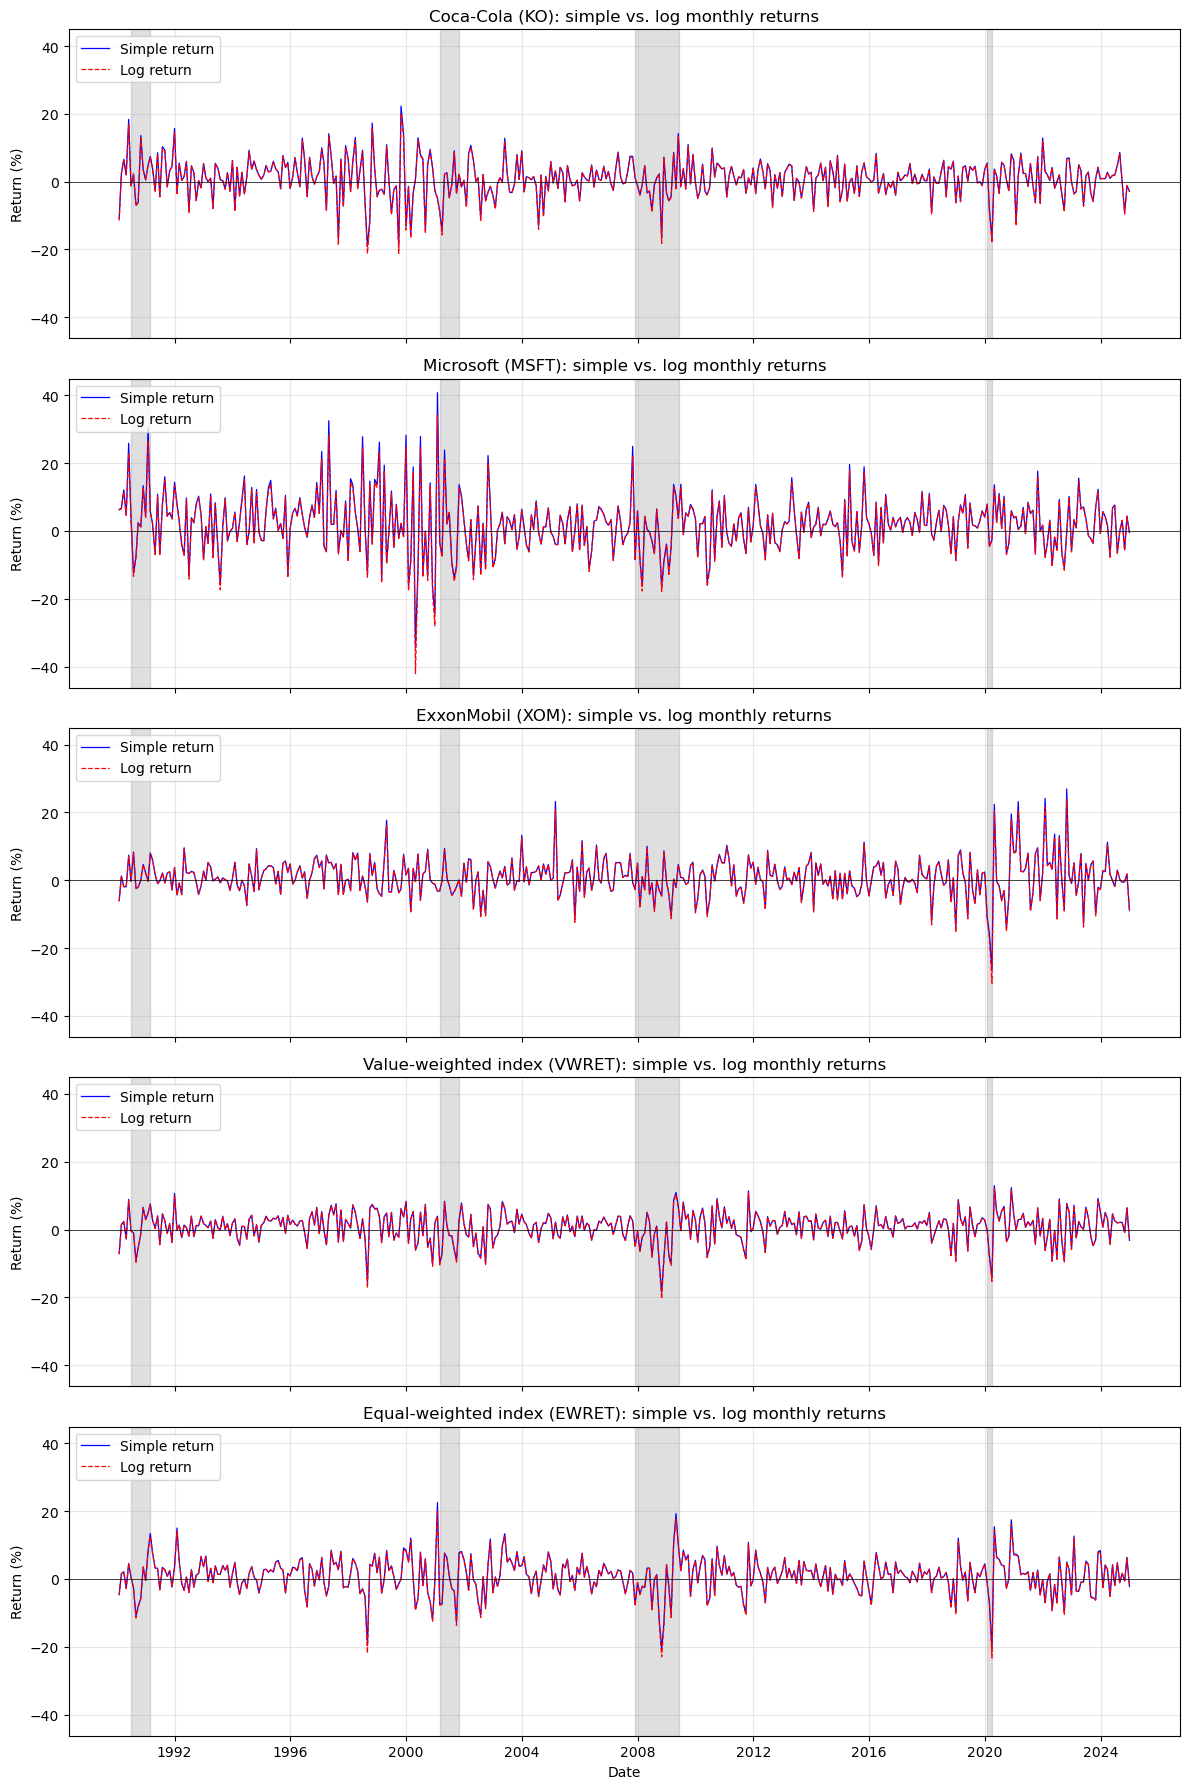

In [4]:
# NBER recession periods within the sample (shaded grey in the plots)
recessions = [('1990-07', '1991-03'), ('2001-03', '2001-11'), ('2007-12', '2009-06'), ('2020-02', '2020-04')]
names = {'KO': 'Coca-Cola', 'MSFT': 'Microsoft', 'XOM': 'ExxonMobil',
         'VWRET': 'Value-weighted index', 'EWRET': 'Equal-weighted index'}

# One panel per series with simple and log returns; shared axes make the volatilities directly comparable
fig, axes = plt.subplots(5, 1, figsize=(12, 18), sharex=True, sharey=True)
for ax, col in zip(axes, ret.columns):
    ax.plot(ret.index, ret[col] * 100, color='blue', lw=0.9, label='Simple return')
    ax.plot(logret.index, logret[col] * 100, color='red', lw=0.9, ls='--', label='Log return')
    for start, end in recessions:
        ax.axvspan(pd.Timestamp(start), pd.Timestamp(end), color='grey', alpha=0.25)
    ax.axhline(0, color='black', lw=0.5)
    ax.set_title(f'{names[col]} ({col}): simple vs. log monthly returns')
    ax.set_ylabel('Return (%)')
    ax.legend(loc='upper left')
    ax.grid(True, alpha=0.3)
axes[-1].set_xlabel('Date')
plt.tight_layout()
plt.show()

In [5]:
# Volatility clustering: standard deviation of monthly log returns (%) by decade
print('Std. dev. of log returns by decade (%):')
print((logret.groupby(logret.index.year // 10 * 10).std() * 100).round(2))

# Most extreme months per series (log returns, %)
print('\nMost extreme months (log returns, %):')
print(pd.DataFrame({'Min': logret.min() * 100, 'Min date': logret.idxmin().dt.date,
                    'Max': logret.max() * 100, 'Max date': logret.idxmax().dt.date}).round(2))

Std. dev. of log returns by decade (%):
        KO   MSFT   XOM  VWRET  EWRET
DATE                                 
1990  7.08   9.00  4.02   3.94   4.67
2000  5.82  10.11  5.17   5.01   6.42
2010  3.80   6.02  4.86   3.66   4.00
2020  5.50   6.34  9.73   5.38   6.31

Most extreme months (log returns, %):
         Min    Min date    Max    Max date
KO    -21.19  1998-08-31  20.11  1999-10-29
MSFT  -42.09  2000-04-28  34.20  2001-01-31
XOM   -30.36  2020-03-31  23.84  2022-10-31
VWRET -20.44  2008-10-31  12.19  2020-04-30
EWRET -23.26  2020-03-31  20.30  2001-01-31


**For all five series, simple and log returns are visually almost indistinguishable: the two lines lie on top of each other, and they only separate in extreme months, where the log return is always lower. Large losses therefore become larger and large gains smaller. Beyond this, the graphs display the classic stylized facts of financial returns: no trend (returns fluctuate around a small positive mean), volatility clustering, occasional extreme months (fat tails), and large shocks that hit all series at the same time.**

**1. Simple vs. log returns.** As derived in (b), the gap between the two lines is roughly $R_t^2/2$, so it is invisible for the vast majority of months and only appears in the spikes. Since the log transformation is concave, it is also *asymmetric*. It stretches the left tail and compresses the right tail. The most striking example is Microsoft, where the simple return of $-34.4\%$ in April 2000 becomes $-42.1\%$ in logs, while the $+40.8\%$ of January 2001 becomes only $+34.2\%$. In simple returns, Microsoft's best month is larger in absolute value than its worst month, and in log returns it is the other way round. As a consequence, log returns are shifted to the left and are more negatively skewed than simple returns, which matters for the distributional analysis in (f) and (h). The separation between the lines is therefore most visible for the most volatile series (MSFT, then XOM and EW) and least visible for the VW index.

**2. No trend, and a very noisy mean.** Unlike prices, which trend upwards (Microsoft's price rose more than a thousand-fold), returns move around a roughly constant mean with no visible trend. This is why we model returns rather than prices: returns are approximately *stationary*. However, the mean is tiny relative to the month-to-month variation. The VW index earns 0.80% per month on average with a standard deviation of 4.44%, a ratio of only 0.18. In the graphs, the positive mean is practically impossible to see, which already indicates that expected returns are hard to estimate precisely (a point we return to in the $t$-tests of (g)).

**3. Volatility clustering.** Calm and turbulent periods alternate, and large returns (of either sign) tend to be followed by large returns. Turbulent periods are the Asian and Russian crises and the collapse of LTCM (1997–1998), the dot-com bubble and its burst (1999–2002), the Global Financial Crisis (2008–2009), COVID-19 (2020) and the inflation shock of 2022. Calm periods are the mid-1990s, 2004–2006 and most of 2012–2019. The standard deviations by decade confirm this:

| Std. dev. (%) | KO | MSFT | XOM | VWRET | EWRET |
|---|---|---|---|---|---|
| 1990–1999 | 7.08 | 9.00 | 4.02 | 3.94 | 4.67 |
| 2000–2009 | 5.82 | 10.11 | 5.17 | 5.01 | 6.42 |
| 2010–2019 | 3.80 | 6.02 | 4.86 | 3.66 | 4.00 |
| 2020–2024 | 5.50 | 6.34 | 9.73 | 5.38 | 6.31 |

Volatility is therefore not constant but persistent and time-varying, which means that returns are not i.i.d., even if they are hardly predictable themselves. This is exactly the behaviour that ARCH/GARCH models are built to capture (Engle, 1982; Bollerslev, 1986). It also means that a single full-sample standard deviation averages over very different regimes and understates risk in turbulent periods while overstating it in calm ones.

**4. Fat tails.** The spikes are far larger than a Normal distribution would allow. The VW index lost 20.4% (log) in October 2008. Given its mean of 0.80% and standard deviation of 4.44%, this is a $-4.8\sigma$ event, which under a Normal distribution would be expected roughly once every 98,000 years of monthly data. Yet the sample contains several months of similar magnitude across the series within just 35 years. This is a first visual indication of excess kurtosis, which we quantify in (f) and test formally in (h).

**5. Series by series.** Using the same vertical axis for all panels makes clear how different the five series are:

- **Microsoft** is the most volatile series (8.40% per month). Its turbulence is concentrated in the dot-com era: $+24.9\%$ in December 1999 at the height of the bubble, then $-42.1\%$ in April 2000, when the court in the US antitrust case ruled against Microsoft in the middle of the Nasdaq crash, followed by $-28.0\%$ in December 2000 and a $+34.2\%$ rebound in January 2001. After 2010 its volatility drops sharply (6.02% compared with 10.11% in the 2000s), as Microsoft matured from a high-growth software company into a diversified mega cap (cloud, Azure, enterprise software). In March 2020, it lost only 2.7% while the market fell 15.3%, as investors saw it as a beneficiary of remote work.
- **Coca-Cola** is a defensive stock, but it was surprisingly volatile in the 1990s (7.08%, higher than the market's 3.94%). In August 1998 it lost 21.2% amid the Russian default and the emerging-market crises, which hit a company that earns most of its revenue abroad particularly hard. In October 1999 it gained 20.1%. In the 2010s, it was barely more volatile than the market itself (3.80%). The COVID shock of March 2020 ($-18.0\%$) hit Coca-Cola unusually hard for a staple, because lockdowns closed restaurants, stadiums and cinemas, a large part of its sales channel.
- **ExxonMobil** displays the most striking change over time. It was the *calmest* stock in the 1990s (4.02%, about the level of the market) but became the *most volatile* of all five series in the 2020s (9.73%). Its biggest moves are driven by the oil price: $-30.4\%$ in March 2020 when oil demand collapsed (WTI futures briefly traded at negative prices in April 2020), a $+20.2\%$ rebound in April 2020, and $+23.8\%$ in October 2022 during the energy rally after Russia's invasion of Ukraine. The oil price is a risk factor that is largely separate from the stock market, which explains why XOM can move sharply when the market does not.
- **The VW index** is the smoothest series (4.44%). Averaging over thousands of stocks diversifies away firm-specific news, so what remains is mostly market-wide (systematic) risk. Its extreme months all coincide with well-known crises: August 1998 ($-17.2\%$), October 2008 ($-20.4\%$), March 2020 ($-15.3\%$) and the rebound of April 2020 ($+12.2\%$).
- **The EW index** is noticeably more volatile than the VW index (5.30% vs. 4.44%), even though it holds the same stocks. Equal weighting puts far more weight on small, illiquid and riskier firms than their market value would justify. Its crashes are deeper (March 2020 $-23.3\%$, October 2008 $-23.0\%$, August 1998 $-21.9\%$) and its rebounds sharper: $+20.3\%$ in January 2001 (the small-cap "January effect" combined with the Fed's surprise rate cut on 3 January 2001) and $+17.6\%$ in April 2009, during the recovery rally that was led by the most beaten-down small stocks.

**6. Common shocks and recessions.** The largest negative months cluster around the shaded NBER recessions and financial crises, and they appear in several panels in the same month (August 1998, October 2008, March 2020). This common component is systematic risk, which we quantify with correlations in (d) and scatterplots in (e). At the same time, not every crisis hits every stock: in October 2008, XOM fell only 4.7% while the market lost 20.4%. In March 2020, MSFT lost only 2.7%. In April 2000, KO even rose by 0.7% while MSFT fell 42.1%. Note also that some of the most extreme episodes, such as Microsoft's in 2000 or Coca-Cola's in 1998, do not fall within recessions at all, since financial-market turmoil and the real business cycle do not always coincide.

**Conclusion.** For monthly data, whether we use simple or log returns hardly changes the *levels* and *dynamics* we see in the graphs, so any conclusion about trends, volatility regimes or co-movement is unaffected. The choice does matter for the *tails* and the *averages*, since log returns make large losses look worse and large gains look smaller and lower the mean by about $\sigma^2/2$. Statements about skewness, extremes and average returns should therefore always be clear about which return definition they refer to.

# 1 (d)

In [6]:
# Pearson correlation matrix of the five log-return series
corr = logret.corr()
corr.round(3)

,KO,MSFT,XOM,VWRET,EWRET
KO,1.000,0.226,0.322,0.436,0.281
MSFT,0.226,1.000,0.180,0.575,0.463
XOM,0.322,0.180,1.000,0.489,0.411
VWRET,0.436,0.575,0.489,1.000,0.875
EWRET,0.281,0.463,0.411,0.875,1.000


In [7]:
# Stock-index correlations: significance (t = rho*sqrt(T-2)/sqrt(1-rho^2)), share of variance explained (rho^2),
# and the rank (Spearman) correlation as a robustness check against outliers
T = len(logret)
stocks = ['KO', 'MSFT', 'XOM']
rho = corr.loc[stocks, ['VWRET', 'EWRET']]
pd.concat({'Pearson': rho, 't-stat': rho * np.sqrt(T - 2) / np.sqrt(1 - rho**2), 'R² = rho²': rho**2,
           'Spearman': logret.corr(method='spearman').loc[stocks, ['VWRET', 'EWRET']]}, axis=1).round(3)

Pearson         t-stat         R² = rho²        Spearman       
       VWRET  EWRET   VWRET   EWRET     VWRET  EWRET    VWRET  EWRET
KO     0.436  0.281   9.902   5.985     0.190  0.079    0.394  0.226
MSFT   0.575  0.463  14.377  10.669     0.331  0.214    0.586  0.448
XOM    0.489  0.411  11.453   9.207     0.239  0.169    0.465  0.389

In [8]:
# Stability over time: correlation with the VW index by sub-period
periods = [('1990', '1999'), ('2000', '2009'), ('2010', '2019'), ('2020', '2024')]
pd.DataFrame({f'{a}-{b}': logret.loc[a:b].corr()['VWRET'] for a, b in periods}).drop('VWRET').round(2)

,1990-1999,2000-2009,2010-2019,2020-2024
KO,0.53,0.31,0.39,0.58
MSFT,0.52,0.57,0.61,0.70
XOM,0.52,0.34,0.70,0.52
EWRET,0.78,0.89,0.95,0.91


**Yes. All three stocks are positively and highly significantly correlated with both indices, but only moderately so, with correlations between 0.28 and 0.58. Each stock correlates more strongly with the VW index than with the EW index. Microsoft is the most closely linked to the market and Coca-Cola the least. The correlations among the three stocks themselves are low (0.18–0.32).**

| Correlation with | KO | MSFT | XOM |
|---|---|---|---|
| VW index | 0.436 | 0.575 | 0.489 |
| EW index | 0.281 | 0.463 | 0.411 |
| $t$-statistic (VW / EW) | 9.90 / 5.99 | 14.38 / 10.67 | 11.45 / 9.21 |
| Variance explained by VW, $\rho^2$ | 19.0% | 33.1% | 23.9% |

**1. Statistical significance.** Under $H_0: \rho = 0$, the statistic $t = \hat\rho\sqrt{T-2}/\sqrt{1-\hat\rho^2}$ follows a $t_{T-2}$ distribution. With $T = 420$, the standard error of a sample correlation under the null is roughly $1/\sqrt{T} \approx 0.049$, so any correlation above about $0.10$ in absolute value is significant at the 5% level. The smallest stock–index correlation (KO with EW, 0.281) has $t \approx 6.0$, and all others are between 9 and 14. Even the lowest pairwise stock correlation (MSFT–XOM, 0.180) has $t \approx 3.7$. There is therefore no doubt that the stocks co-move with the market. The relevant question is *how strongly*.

**2. Moderate correlation means most risk is firm-specific.** The squared correlation $\rho^2$ equals the $R^2$ of a regression of the stock on the index, i.e. the share of the stock's variance that is explained by market movements. The VW index explains only 33% of Microsoft's monthly variance, 24% of ExxonMobil's and 19% of Coca-Cola's. Between two thirds and four fifths of each stock's risk is therefore *idiosyncratic*. This risk is driven by firm- and industry-specific news such as court rulings, product cycles, oil prices or emerging-market currencies, and it can be diversified away by holding many stocks. This is exactly why the VW index (4.44% per month) is much less volatile than any of the three stocks (5.69–8.40%). It is also the central idea of the CAPM: only the systematic part of risk should be rewarded with a risk premium, because only that part cannot be diversified away.

**3. The ranking makes economic sense.**
- *Microsoft* (0.575) is the most market-sensitive. Its cash flows depend on corporate and consumer IT spending, which moves with the business cycle, and as a growth stock most of its value comes from distant cash flows, which makes it sensitive to changes in discount rates. Its large and growing weight in the index also mechanically links it to the VW index (see point 4).
- *ExxonMobil* (0.489) is driven to a large extent by the oil price. Oil is correlated with economic activity, but it also moves for its own reasons (OPEC decisions, geopolitics, supply shocks), which is not a risk shared with the stock market.
- *Coca-Cola* (0.436) is the textbook defensive stock. Demand for soft drinks barely depends on the business cycle, so its cash flows, and therefore its returns, are only weakly tied to the market.

**4. Why the correlations are higher with the VW index than with the EW index.** There are three complementary reasons:
- *Composition.* The three stocks are mega caps, and the VW index is dominated by exactly such large firms. The EW index, in contrast, is dominated in number by small stocks, which are exposed to different risks (liquidity, access to credit, the size factor) and react differently to shocks. The gap is largest for Coca-Cola (0.436 vs. 0.281). A stable consumer-staples giant has little in common with the typical small, cyclical and high-beta firm that dominates the EW index.
- *A mechanical inclusion effect.* Each stock is itself a constituent of the VW index, with a substantial weight. Writing $r_{VW} = \sum_j w_j r_j$,
$$\text{Cov}(r_i, r_{VW}) = w_i\,\sigma_i^2 + \sum_{j\neq i} w_j\,\text{Cov}(r_i, r_j)$$
so a stock with a large weight $w_i$ is partly correlated with the index *with itself*. Microsoft accounted for roughly 5–6% of US market capitalization by the end of the sample. With an illustrative weight of 5%, the term $w_i\sigma_i^2 = 0.05 \times 0.0840^2 \approx 0.00035$ would make up about 16% of Microsoft's total covariance with the index ($0.575 \times 0.0840 \times 0.0444 \approx 0.00214$). In the EW index, each stock has a weight of only $1/N$ with $N$ in the thousands, so this effect is negligible. (Microsoft's weight was much lower in the early 1990s, so this is an upper bound for the full-sample effect.)
- *The two indices are not the same thing.* VW and EW are themselves correlated at only 0.875, so about 23% ($1 - 0.875^2$) of the EW index's variance is not shared with the VW index. That remaining part reflects small-firm risk that has little to do with large caps like KO, MSFT and XOM.

**5. Low correlations among the stocks.** The pairwise correlations are low: 0.180 for MSFT–XOM, 0.226 for MSFT–KO and 0.322 for KO–XOM. The three firms operate in unrelated industries, so their firm-specific news is largely independent and they mainly share the common market factor. KO–XOM is the highest pair: both are "old-economy" value stocks, both fell sharply in the emerging-market crisis of 1998, and both held up well while technology stocks collapsed in 2000–2001. For an investor, such low correlations mean large diversification benefits even within a portfolio of only three stocks.

**6. Correlations are not stable over time.** Correlations with the VW index by decade:

| | 1990–1999 | 2000–2009 | 2010–2019 | 2020–2024 |
|---|---|---|---|---|
| KO | 0.53 | 0.31 | 0.39 | 0.58 |
| MSFT | 0.52 | 0.57 | 0.61 | 0.70 |
| XOM | 0.52 | 0.34 | 0.70 | 0.52 |
| EWRET | 0.78 | 0.89 | 0.95 | 0.91 |

- Microsoft's correlation rises steadily from 0.52 to 0.70, as it grew into one of the largest weights in the index and technology became the dominant sector of the US market. Increasingly, Microsoft partly *is* the market.
- ExxonMobil's correlation fell to 0.34 in the 2000s, when the commodity super-cycle (oil rose from about \$25 to over \$140 per barrel) decoupled energy stocks from the rest of the market. It rose to 0.70 in the 2010s, when the oil price collapse of 2014–2016 hit the market as a whole.
- Coca-Cola's correlation dropped in the 2000s, as defensive stocks held up during the dot-com bust, and reached its highest level in the 2020s, when COVID-19 hit even staples.
- The two indices themselves have become much more similar (0.78 → 0.91–0.95).

The full-sample correlation matrix is therefore an *average* over very different regimes. A portfolio built on the full-sample numbers would have overestimated the diversification benefit of Coca-Cola in the 2020s, for example.

**7. Robustness.** The rank (Spearman) correlations with the VW index (KO 0.39, MSFT 0.59, XOM 0.47) are very close to the Pearson correlations, so the results are not driven by a few extreme months. The correlations of the simple returns are also almost identical to those of the log returns (e.g. 0.569 vs. 0.575 for MSFT–VW), as expected for a transformation that is monotone and almost linear for typical monthly returns. Note, however, that Pearson correlation measures only *linear* and *average* co-movement. As we show in (e), co-movement is noticeably stronger in down markets than in up markets.

**8. From correlation to beta.** Correlation measures how *tightly* a stock moves with the market, but not *how much* it moves. Its sensitivity to the market, the beta, combines the correlation with the relative volatility:
$$\beta_i = \rho_{i,m}\,\frac{\sigma_i}{\sigma_m}: \qquad \beta_{KO} = 0.436 \times \tfrac{5.70}{4.44} = 0.56, \qquad \beta_{MSFT} = 0.575 \times \tfrac{8.40}{4.44} = 1.09, \qquad \beta_{XOM} = 0.489 \times \tfrac{5.69}{4.44} = 0.63$$
Coca-Cola and ExxonMobil are both *more* volatile than the market but have betas well *below* one, because most of their volatility is uncorrelated with the market. A high total volatility therefore does not imply a high systematic risk. These betas are exactly the slopes of the fitted lines in the scatterplots of (e).

# 1 (e)

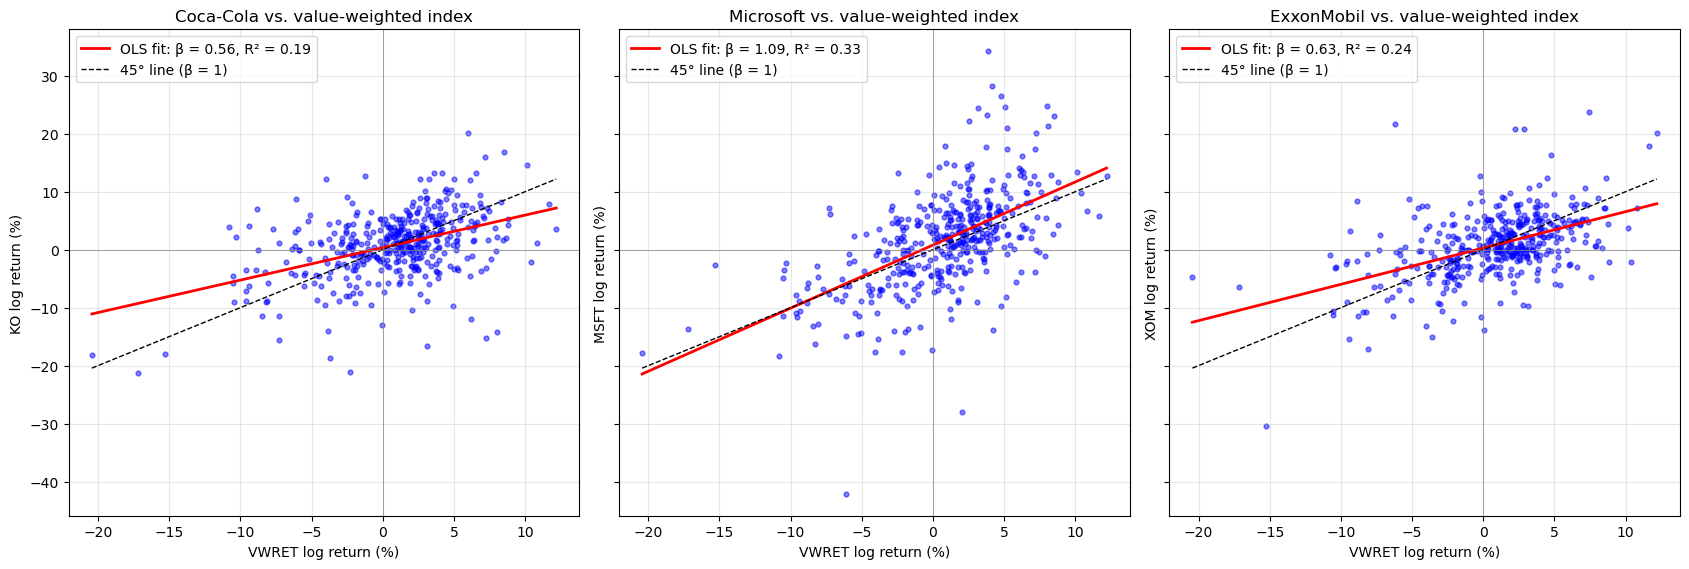

In [9]:
# Scatter of each stock against the VW index, with the OLS fit (slope = beta) and a 45-degree reference line (beta = 1)
x = logret['VWRET'] * 100
grid = np.linspace(x.min(), x.max(), 100)
fig, axes = plt.subplots(1, 3, figsize=(17, 5.8), sharex=True, sharey=True)
for ax, col in zip(axes, stocks):
    y = logret[col] * 100
    b, a = np.polyfit(x, y, 1)                          # OLS slope (beta) and intercept
    ax.scatter(x, y, s=12, alpha=0.5, color='blue')
    ax.plot(grid, a + b * grid, color='red', lw=2, label=f'OLS fit: β = {b:.2f}, R² = {x.corr(y)**2:.2f}')
    ax.plot(grid, grid, color='black', ls='--', lw=1, label='45° line (β = 1)')
    ax.axhline(0, color='grey', lw=0.5)
    ax.axvline(0, color='grey', lw=0.5)
    ax.set_title(f'{names[col]} vs. value-weighted index')
    ax.set_xlabel('VWRET log return (%)')
    ax.set_ylabel(f'{col} log return (%)')
    ax.legend(loc='upper left')
    ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [10]:
# Decomposing the scatter: beta, systematic vs. idiosyncratic volatility, and behaviour in down vs. up markets
mkt = logret['VWRET']
beta = logret[stocks].apply(lambda s: s.cov(mkt) / mkt.var())
down, up = logret[mkt < 0], logret[mkt > 0]
worst, best = mkt <= mkt.quantile(0.1), mkt >= mkt.quantile(0.9)

pd.DataFrame({'Beta': beta,
              'R²': logret[stocks].corrwith(mkt)**2,
              'Total sd (%)': logret[stocks].std() * 100,
              'Systematic sd (%)': beta * mkt.std() * 100,
              'Idiosyncratic sd (%)': np.sqrt(logret[stocks].var() - beta**2 * mkt.var()) * 100,
              'Corr | mkt down': down[stocks].corrwith(down['VWRET']),
              'Corr | mkt up': up[stocks].corrwith(up['VWRET']),
              'Avg in worst 10% mkt months (%)': logret.loc[worst, stocks].mean() * 100,
              'Avg in best 10% mkt months (%)': logret.loc[best, stocks].mean() * 100}).round(2)

,Beta,R²,Total sd (%),Systematic sd (%),Idiosyncratic sd (%),Corr | mkt down,Corr | mkt up,Avg in worst 10% mkt months (%),Avg in best 10% mkt months (%)
KO,0.56,0.19,5.70,2.49,5.13,0.38,0.21,-3.54,3.78
MSFT,1.09,0.33,8.40,4.83,6.87,0.42,0.34,-8.55,8.79
XOM,0.63,0.24,5.69,2.78,4.96,0.34,0.32,-4.59,5.20


In [11]:
print(f'Market itself: {mkt[worst].mean()*100:.2f}% in its worst 10% months, {mkt[best].mean()*100:.2f}% in its best 10% months')
print(f'Number of down / up market months: {len(down)} / {len(up)}')
print('Share of months moving in the same direction as the market:', (np.sign(logret[stocks]).eq(np.sign(mkt), axis=0)).mean().round(3).to_dict())

# Stability over time: beta with respect to the VW index by sub-period
pd.DataFrame({f'{a}-{b}': logret.loc[a:b, stocks].apply(lambda s: s.cov(logret.loc[a:b, 'VWRET']) / logret.loc[a:b, 'VWRET'].var())
              for a, b in periods}).round(2)

Market itself: -8.32% in its worst 10% months, 7.62% in its best 10% months
Number of down / up market months: 147 / 273
Share of months moving in the same direction as the market: {'KO': 0.669, 'MSFT': 0.757, 'XOM': 0.698}


,1990-1999,2000-2009,2010-2019,2020-2024
KO,0.96,0.36,0.41,0.59
MSFT,1.19,1.15,1.01,0.82
XOM,0.53,0.35,0.92,0.94


**All three scatterplots show an upward-sloping, roughly elliptical cloud: in months when the market rises, the stocks tend to rise too. The slope of the fitted line (the beta) is close to one for Microsoft (1.09), but only about 0.6 for Coca-Cola (0.56) and ExxonMobil (0.63), whose lines are clearly flatter than the 45° line. The most striking feature, however, is the large vertical scatter around the lines. The market explains only 19–33% of the stocks' monthly variation, so firm-specific risk dominates.**

**1. The slope is the beta.** The OLS slope of a regression of the stock on the market is $\hat\beta_i = \widehat{\text{Cov}}(r_i, r_m)/\widehat{\text{Var}}(r_m) = \hat\rho_{i,m}\,\hat\sigma_i/\hat\sigma_m$, the same numbers as derived from the correlations in (d). The 45° line shows what a stock with $\beta = 1$ would look like.
- *Microsoft* ($\beta = 1.09$) moves slightly more than one-for-one with the market, so it amplifies market movements and is an *aggressive* stock.
- *Coca-Cola* ($\beta = 0.56$) and *ExxonMobil* ($\beta = 0.63$) are *defensive*: on average, a 1% move in the market goes along with a move of only about 0.6% in these stocks.

The average returns in the most extreme market months confirm this directly, without any regression:

| | Market | KO | MSFT | XOM |
|---|---|---|---|---|
| Average in the 10% worst market months | $-8.32\%$ | $-3.54\%$ | $-8.55\%$ | $-4.59\%$ |
| Average in the 10% best market months | $+7.62\%$ | $+3.78\%$ | $+8.79\%$ | $+5.20\%$ |

When the market crashes, Microsoft falls about as much as the market, while Coca-Cola and ExxonMobil lose only about half as much. In the best months, they also gain only about half as much. Beta works in both directions: the protection on the downside comes at the cost of smaller gains on the upside.

**2. The vertical scatter is idiosyncratic risk.** The clouds are wide, and the fitted line describes only a small part of each stock's variation. Since the market return and the residual are uncorrelated by construction, each stock's variance can be split into a systematic and an idiosyncratic part,
$$\sigma_i^2 = \underbrace{\beta_i^2\,\sigma_m^2}_{\text{systematic}} + \underbrace{\sigma_{\varepsilon,i}^2}_{\text{idiosyncratic}}$$

| | Total sd | Systematic sd ($\beta\sigma_m$) | Idiosyncratic sd | $R^2$ |
|---|---|---|---|---|
| KO | 5.70% | 2.49% | 5.13% | 0.19 |
| MSFT | 8.40% | 4.83% | 6.87% | 0.33 |
| XOM | 5.69% | 2.78% | 4.96% | 0.24 |

For every stock, the idiosyncratic volatility is larger than the systematic volatility. Coca-Cola and ExxonMobil have *exactly the same* total volatility (5.7%), which is clearly *higher* than the market's 4.44%, yet only about 2.5–2.8 pp of this is market risk. This is the key lesson of the scatterplots: a stock can be more volatile than the market and still be much less exposed to it. According to the CAPM, investors are compensated only for the systematic part, because the rest can be diversified away. Coca-Cola and ExxonMobil should therefore earn *lower* expected returns than the market. In this sample, however, both compounded at about the market's 10% p.a., and Microsoft, with a beta of only slightly above one, earned more than twice the market's return (22.3% p.a.). This already suggests positive alphas, which we will test formally in the CAPM regressions of (i).

**3. The outliers tell their own stories.** Points far *above or below* the line (vertical outliers) are months in which the stock moved for firm-specific reasons that had nothing to do with the market:
- MSFT in April 2000: $-42.1\%$ while the market fell only 6.1% (antitrust ruling); December 2000: $-28.0\%$ while the market *rose* 2.0%; January 2001: $+34.2\%$ with a market return of $+3.9\%$.
- KO in October 1999: $+20.1\%$ with a market return of $+6.0\%$.
- XOM in October 2022: $+23.8\%$ with a market return of $+7.5\%$, driven by oil prices and record refining margins.

Points far to the *left* (market crashes) show that the reaction to a market-wide crisis depends heavily on its nature:
- October 2008, $-20.4\%$ market return (financial crisis): KO $-18.2\%$ and MSFT $-17.8\%$ fell almost one-for-one with the market, whereas XOM lost only 4.7%.
- March 2020, $-15.3\%$ market return (pandemic): XOM lost 30.4%, twice as much as the market, KO lost 18.0%, while MSFT lost only 2.7%.

In the two biggest crises of the sample, the "defensive" XOM was alternately a safe haven and the worst performer, and the "aggressive" MSFT was almost unaffected by the pandemic crash. A single beta estimated over all months cannot capture such crisis-specific exposures. Since OLS minimizes *squared* residuals, a few such extreme points can also have a disproportionate influence on the estimated slope.

**4. Stronger co-movement in down markets.** Splitting the sample by the sign of the market return gives:

| | Corr. when market falls (147 months) | Corr. when market rises (273 months) |
|---|---|---|
| KO | 0.38 | 0.21 |
| MSFT | 0.42 | 0.34 |
| XOM | 0.34 | 0.32 |

All three stocks co-move more strongly with the market when it falls, and for Coca-Cola the difference is large. Both conditional correlations are lower than the unconditional ones, because conditioning on the sign of the market return restricts its range, and a restricted range mechanically lowers correlations (Forbes & Rigobon, 2002). Since both halves are restricted in the same way, the *comparison* between them is still informative. This asymmetry is a well-documented feature of equity markets (Longin & Solnik, 2001; Ang & Chen, 2002). It means that diversification works worst exactly when investors need it most. Microsoft, Coca-Cola and ExxonMobil also move in the same direction as the market in only 76%, 67% and 70% of all months, respectively, a reminder of how noisy the relationship is month by month.

**5. Is a linear model appropriate?** The clouds show no visible curvature, so a linear relationship between stock and market returns, as assumed by the CAPM regression in (i), looks reasonable on average. Two features of the plots, however, call for caution in the statistical inference. First, both axes contain fat-tailed observations far from the centre of the cloud, so the residuals are unlikely to be Normal. Second, as seen in (c), volatility changes over time, so the residual variance is not constant (heteroskedasticity). OLS remains unbiased under these conditions, but the conventional standard errors may be wrong, and heteroskedasticity-robust (White) or Newey–West standard errors should be preferred.

**6. Beta is not constant over time either.** Each scatterplot pools 35 years of data. Estimating the slope by decade shows that the "true" exposure has changed considerably:

| Beta | 1990–1999 | 2000–2009 | 2010–2019 | 2020–2024 |
|---|---|---|---|---|
| KO | 0.96 | 0.36 | 0.41 | 0.59 |
| MSFT | 1.19 | 1.15 | 1.01 | 0.82 |
| XOM | 0.53 | 0.35 | 0.92 | 0.94 |

In the 1990s, Coca-Cola had a beta of about one: it then traded at very high valuation multiples and behaved more like a growth stock than a staple. Only after 2000 did it become the low-beta defensive stock we think of today. ExxonMobil changed from a low-beta stock (0.35 in the 2000s) to almost market-like exposure (0.92–0.94) since 2010, as oil-price shocks and the market have increasingly moved together. Microsoft's beta has declined steadily from 1.19 to 0.82. This is consistent with the tendency of betas to revert towards one over time (Blume, 1971) and with Microsoft's transformation into a mature mega cap. The full-sample beta is therefore an average across regimes, and for forward-looking decisions (e.g. estimating the cost of capital), a beta estimated over a recent window, or adjusted towards one, may be more appropriate.

**Conclusion.** The scatterplots show that all three stocks are positively exposed to the market, but very differently: Microsoft is an amplifier ($\beta \approx 1.1$), while Coca-Cola and ExxonMobil are dampeners ($\beta \approx 0.6$). In all three cases, firm-specific risk accounts for the bulk of the volatility. For an investor, this has two consequences. Holding any one of these stocks alone exposes them to large risks that are not rewarded under the CAPM, and combining the stocks with the market portfolio provides diversification, especially in the case of the two defensive stocks. These benefits are, however, smaller than the full-sample numbers suggest, because co-movement increases in down markets and exposures change over time.

# 1 (f)

In [12]:
# Summary statistics of the log returns (pandas skew/kurt are the bias-adjusted sample estimators; kurt() is EXCESS kurtosis)
summary = pd.DataFrame({'Mean (%)': logret.mean() * 100,
                        'Variance (%²)': logret.var() * 100**2,
                        'Std. dev. (%)': logret.std() * 100,
                        'Skewness': logret.skew(),
                        'Excess kurtosis': logret.kurt(),
                        'Min (%)': logret.min() * 100,
                        'Max (%)': logret.max() * 100})
print(f'Standard errors under normality: skewness {np.sqrt(6 / T):.3f}, excess kurtosis {np.sqrt(24 / T):.3f}')
summary.T.round(3)

Standard errors under normality: skewness 0.120, excess kurtosis 0.239


,KO,MSFT,XOM,VWRET,EWRET
Mean (%),0.805,1.675,0.793,0.802,0.823
Variance (%²),32.502,70.511,32.376,19.687,28.120
Std. dev. (%),5.701,8.397,5.690,4.437,5.303
Skewness,-0.569,-0.115,-0.093,-0.833,-0.579
Excess kurtosis,1.907,2.523,3.713,1.864,2.832
Min (%),-21.195,-42.088,-30.362,-20.436,-23.257
Max (%),20.114,34.201,23.835,12.193,20.297


In [13]:
# Additional risk measures for the investment comparison: annualized moments, reward-to-risk, tail risk and drawdowns
wealth = np.exp(logret.cumsum())                                   # growth of $1 (log returns are additive)
q05 = logret.quantile(0.05)
pd.DataFrame({'Mean p.a. (%)': logret.mean() * 12 * 100,
              'Std. dev. p.a. (%)': logret.std() * np.sqrt(12) * 100,
              'Mean / Std (monthly)': logret.mean() / logret.std(),
              '5% VaR, historical (%)': q05 * 100,
              '5% VaR, Normal (%)': (logret.mean() + stats.norm.ppf(0.05) * logret.std()) * 100,
              '5% Expected shortfall (%)': logret[logret <= q05].mean() * 100,
              'Max drawdown (%)': (wealth / wealth.cummax() - 1).min() * 100}).T.round(2)

,KO,MSFT,XOM,VWRET,EWRET
Mean p.a. (%),9.66,20.10,9.51,9.62,9.88
Std. dev. p.a. (%),19.75,29.09,19.71,15.37,18.37
Mean / Std (monthly),0.14,0.20,0.14,0.18,0.16
"5% VaR, historical (%)",-8.89,-11.59,-9.06,-7.71,-7.97
"5% VaR, Normal (%)",-8.57,-12.14,-8.57,-6.50,-7.90
5% Expected shortfall (%),-13.69,-16.89,-12.46,-10.51,-12.23
Max drawdown (%),-50.07,-66.63,-58.09,-51.48,-55.80


**The equal-weighted index carries more risk than the value-weighted index on almost every measure. It has a higher variance (28.1 vs. 19.7 %², i.e. 43% higher), fatter tails (excess kurtosis 2.83 vs. 1.86), a deeper worst month ($-23.3\%$ vs. $-20.4\%$), larger tail losses and a deeper maximum drawdown, while its mean return is only marginally higher (0.823% vs. 0.802% per month). The only measure on which the VW index looks worse is skewness ($-0.83$ vs. $-0.58$). From an investment perspective, the EW index is therefore the riskier one, and its additional risk is hardly rewarded.**

| | KO | MSFT | XOM | VWRET | EWRET |
|---|---|---|---|---|---|
| Mean (%) | 0.805 | 1.675 | 0.793 | 0.802 | 0.823 |
| Variance (%²) | 32.50 | 70.51 | 32.38 | 19.69 | 28.12 |
| Std. dev. (%) | 5.70 | 8.40 | 5.69 | 4.44 | 5.30 |
| Skewness | $-0.569$ | $-0.115$ | $-0.093$ | $-0.833$ | $-0.579$ |
| Excess kurtosis | 1.907 | 2.523 | 3.713 | 1.864 | 2.832 |
| Min (%) | $-21.19$ | $-42.09$ | $-30.36$ | $-20.44$ | $-23.26$ |
| Max (%) | 20.11 | 34.20 | 23.84 | 12.19 | 20.30 |

(In decimal units, the variances are 0.00325, 0.00705, 0.00324, 0.00197 and 0.00281.)

**What each statistic tells us about all five series**

- **Mean.** Four of the five series earn almost the same average log return of about 0.80% per month (roughly 9.5–9.9% p.a.). Microsoft is the clear exception with 1.67% per month (20.1% p.a.). Given how noisy means are (see (g)), the differences among the first four are economically and statistically negligible.
- **Variance and standard deviation.** Microsoft is by far the riskiest series (8.40% per month, 29.1% p.a.), followed by Coca-Cola and ExxonMobil, whose volatilities are practically identical (5.70% and 5.69%), then the EW index (5.30%) and the VW index (4.44%). The VW index is less volatile than *every* single stock: its variance (19.7) is less than half the average variance of the three stocks (45.1). This is diversification at work, as discussed in (d) and (e).
- **Skewness.** All five log-return series are negatively skewed, meaning that large losses are more extreme than large gains. Under normality, the standard error of the sample skewness is about $\sqrt{6/T} = 0.12$, so the skewness is significantly negative for the VW index ($z \approx -6.9$), the EW index ($-4.8$) and Coca-Cola ($-4.8$), but *not* for Microsoft ($-1.0$) or ExxonMobil ($-0.8$). The log transformation itself plays a role here, as seen in (c). In *simple* returns, Microsoft and ExxonMobil are actually positively skewed ($+0.42$ and $+0.38$), and the concave log transformation turns this into a slight negative skew. The most interesting pattern is that **the indices are more negatively skewed than the individual stocks**. Firm-specific jumps, both positive (a successful product, a takeover bid) and negative, diversify away in the index. Market-wide crashes, however, cannot be diversified, and since correlations rise in down markets (see (e)), the losses of many stocks pile up in the same months. Averaging thus removes the idiosyncratic positive skew of individual stocks but keeps the systematic crash risk, which makes indices more negatively skewed than their constituents (Chen, Hong & Stein, 2001; Albuquerque, 2012).
- **Excess kurtosis.** All series are *leptokurtic*, with excess kurtosis between 1.86 (VW) and 3.71 (XOM). The standard error under normality is $\sqrt{24/T} = 0.24$, so all values are highly significant. Compared with a Normal distribution, the returns have more mass in the centre and in the tails and less in the "shoulders": too many calm months and too many extreme months. ExxonMobil has the fattest tails, driven by the oil-price shocks of 2020–2022. The VW index has the thinnest tails, as diversification removes the firm-specific jumps.
- **Minimum and maximum.** For every series, the worst month is larger in absolute value than the best month, consistent with the negative skewness. The asymmetry is largest for the VW index ($-20.4\%$ vs. $+12.2\%$). In relation to their volatilities, the extreme months are far beyond what a Normal distribution would produce: the VW minimum is a $-4.8\sigma$ event, and ExxonMobil's March 2020 is $-5.5\sigma$.

**VW vs. EW: which index is riskier?** The additional risk measures above make the comparison concrete:

| | VWRET | EWRET | Riskier |
|---|---|---|---|
| Std. dev. p.a. | 15.37% | 18.37% | EW |
| Excess kurtosis | 1.86 | 2.83 | EW |
| Skewness | $-0.83$ | $-0.58$ | VW |
| Worst month | $-20.4\%$ | $-23.3\%$ | EW |
| 5% VaR (historical) | $-7.71\%$ | $-7.97\%$ | EW |
| 5% Expected shortfall | $-10.51\%$ | $-12.23\%$ | EW |
| Maximum drawdown | $-51.5\%$ | $-55.8\%$ | EW |
| Mean / Std (monthly) | 0.181 | 0.155 | EW (worse reward-to-risk) |

**The EW index is riskier**, for several reasons:

1. *Higher volatility.* Its standard deviation is about 20% higher (variance 43% higher), even though both indices hold the same stocks. Equal weighting gives the many small firms the same weight as the giants, and small firms are more volatile, less liquid, more dependent on external financing and more exposed to the business cycle. The EW index's beta with respect to the VW index is $0.875 \times 5.30/4.44 \approx 1.05$, so it also carries slightly *more* systematic risk, plus about 23% of variance that is not shared with the VW index at all (see (d)).
2. *Fatter tails and larger extreme losses.* Its excess kurtosis is about 50% higher, its worst month is 2.8 pp worse, and its expected shortfall (the average loss in the worst 5% of months) is 1.7 pp worse. In crises, small stocks suffer from flight-to-quality and liquidity dry-ups. In March 2020, for example, the EW index lost 23.3% compared with 15.3% for the VW index.
3. *Deeper drawdowns.* An investor in the EW index would have experienced a peak-to-trough loss of 55.8%, compared with 51.5% for the VW index.
4. *Risk that is hardly rewarded.* The extra mean return of 0.021 pp per month is tiny compared with the extra risk, and it is far from statistically significant (we test it in (g): $t = 0.17$). The reward per unit of risk is therefore clearly lower for the EW index (0.155 vs. 0.181). A mean-variance investor would prefer the VW index, since it offers practically the same expected return with substantially less variance. This is consistent with the observation that the size premium, documented for earlier periods (Banz, 1981; Fama & French, 1992), has been weak since the 1980s.
5. *Practical costs not visible in the data.* The EW index needs constant rebalancing towards the stocks that have fallen and away from those that have risen, and its many small, illiquid stocks are expensive to trade. Net of transaction costs, the EW index would look even less attractive. The VW index, in contrast, is a buy-and-hold portfolio that needs almost no rebalancing.

**The skewness caveat.** The VW index is more negatively skewed, which seems to contradict the conclusion above. Skewness, however, is a *standardized* measure: it describes the shape of the distribution relative to its own volatility. The VW index's crashes are large *compared with its calm normal months*, but in absolute terms the EW index's crashes are larger. An investor who dislikes negative skewness (a "prudent" investor with a preference for positive third moments) would care about this difference, but every measure of the actual size of losses (minimum, VaR, expected shortfall, drawdown) points to the EW index as the riskier investment. Overall, the EW index carries more risk on all dimensions except the relative asymmetry of its distribution.

# 1 (g)

In [14]:
# One-sample t-test of H0: E[r] = 0 against the two-sided alternative H1: E[r] != 0, with t = mean / (s / sqrt(T))
ttest = stats.ttest_1samp(logret, popmean=0)
se = logret.std() / np.sqrt(T)
tcrit = stats.t.ppf(0.975, T - 1)
print(f'Critical value (5%, two-sided, {T - 1} df): {tcrit:.3f}')
pd.DataFrame({'Mean (%)': logret.mean() * 100,
              'Std. error (%)': se * 100,
              't-stat': ttest.statistic,
              'p-value': ttest.pvalue,
              '95% CI low (%)': (logret.mean() - tcrit * se) * 100,
              '95% CI high (%)': (logret.mean() + tcrit * se) * 100,
              'Reject H0 at 5%': ttest.pvalue < 0.05}).round(4)

Critical value (5%, two-sided, 419 df): 1.966


,Mean (%),Std. error (%),t-stat,p-value,95% CI low (%),95% CI high (%),Reject H0 at 5%
KO,0.8047,0.2782,2.8927,0.0040,0.2579,1.3515,True
MSFT,1.6747,0.4097,4.0874,0.0001,0.8693,2.4801,True
XOM,0.7928,0.2776,2.8554,0.0045,0.2470,1.3385,True
VWRET,0.8017,0.2165,3.7031,0.0002,0.3762,1.2273,True
EWRET,0.8232,0.2588,3.1815,0.0016,0.3146,1.3318,True


In [15]:
# Robustness: Newey-West (HAC, 6 lags) t-statistics, which allow for autocorrelation and heteroskedasticity
nw_t = logret.apply(lambda s: sm.OLS(s, np.ones(T)).fit(cov_type='HAC', cov_kwds={'maxlags': 6}).tvalues.iloc[0])
pd.set_option('display.width', 200)
print(pd.DataFrame({'t-stat (iid)': ttest.statistic, 't-stat (Newey-West)': nw_t,
                    'AC(1) of returns': logret.apply(lambda s: s.autocorr()),
                    'AC(1) of squared returns': (logret**2).apply(lambda s: s.autocorr()),
                    'Months needed for t = 1.966': (tcrit * logret.std() / logret.mean())**2}).round(3))
print(f"\nVW mean log return 2000-2009: {logret.loc['2000':'2009', 'VWRET'].mean() * 100:.3f}% per month")

# Is the EW index's higher mean significantly different from the VW index's mean? (paired test on the difference)
diff_test = stats.ttest_1samp(logret['EWRET'] - logret['VWRET'], 0)
print(f'\nEW - VW: mean difference = {(logret.EWRET - logret.VWRET).mean() * 100:.3f}%, t = {diff_test.statistic:.2f}, p = {diff_test.pvalue:.3f}')

       t-stat (iid)  t-stat (Newey-West)  AC(1) of returns  AC(1) of squared returns  Months needed for t = 1.966
KO            2.893                3.296            -0.063                     0.176                      193.927
MSFT          4.087                4.578            -0.123                     0.179                       97.134
XOM           2.855                2.993            -0.040                     0.253                      199.030
VWRET         3.703                3.631             0.030                     0.249                      118.339
EWRET         3.181                2.900             0.169                     0.246                      160.324

VW mean log return 2000-2009: 0.015% per month

EW - VW: mean difference = 0.021%, t = 0.17, p = 0.864


**For all five series, we reject the null hypothesis that the average log return is zero at the 5% level. The $t$-statistics range from 2.86 (ExxonMobil) to 4.09 (Microsoft), all above the critical value of 1.966, and the largest $p$-value is 0.0045. The rejection is robust to autocorrelation and heteroskedasticity (Newey–West) and to correcting for testing five hypotheses at once. Still, the confidence intervals are remarkably wide: even 35 years of data pin down the average return only very roughly.**

**Test setup.** For each series, we test $H_0: \mu = 0$ against $H_1: \mu \neq 0$ using
$$t = \frac{\bar r}{s/\sqrt{T}} \;\sim\; t_{T-1} \text{ under } H_0, \qquad \text{reject if } |t| > t_{0.975,\,419} = 1.966 \;\text{ or equivalently if } p < 0.05$$

| | Mean (%) | Std. error (%) | $t$-stat | $p$-value | 95% CI (%) | Decision |
|---|---|---|---|---|---|---|
| KO | 0.805 | 0.278 | 2.89 | 0.0040 | [0.26, 1.35] | Reject $H_0$ |
| MSFT | 1.675 | 0.410 | 4.09 | 0.0001 | [0.87, 2.48] | Reject $H_0$ |
| XOM | 0.793 | 0.278 | 2.86 | 0.0045 | [0.25, 1.34] | Reject $H_0$ |
| VWRET | 0.802 | 0.217 | 3.70 | 0.0002 | [0.38, 1.23] | Reject $H_0$ |
| EWRET | 0.823 | 0.259 | 3.18 | 0.0016 | [0.31, 1.33] | Reject $H_0$ |

**1. Interpretation.** Holding US equities, both the market as a whole and each of the three stocks, delivered a positive average log return over 1990–2024 that cannot be explained by chance. Since the mean log return is the compounded growth rate (see (b)), the test asks whether an investment *grew* in value over time on average. It did. Because $E[R] > E[r]$, a test on *simple* returns would reject even more clearly. Note that this is a test of the raw return and not of the *equity premium*, since we do not subtract the risk-free rate. As a back-of-the-envelope calculation, with an average one-month T-bill rate of roughly 2.5% p.a. (about 0.21% per month) over the sample, the excess return of the VW index would be about $(0.80 - 0.21)/0.217 \approx 2.7$ standard errors from zero, still significant. For Coca-Cola and ExxonMobil, the corresponding $t$-statistics would drop to about 2.1, just above the critical value.

**2. The real lesson: means are estimated very imprecisely.** Despite 420 monthly observations, the 95% confidence interval for the VW index ranges from 0.38% to 1.23% per month, i.e. from about 4.5% to 14.7% p.a. A pension fund that uses the sample average to plan its future could be off by a factor of three. The reason is the low signal-to-noise ratio seen in (c): monthly volatility (4.4%) is more than five times the mean (0.8%). The standard error shrinks only with $\sqrt{T}$, so the number of months needed for the mean to become significant, *if the true mean equalled the sample mean*, is $T^* = (1.966\,s/\bar r)^2$:

| | KO | MSFT | XOM | VWRET | EWRET |
|---|---|---|---|---|---|
| Months needed for $t = 1.966$ | 194 | 97 | 199 | 118 | 160 |
| in years | 16.2 | 8.1 | 16.6 | 9.9 | 13.4 |

Even for the market index, about a decade of data is needed just to distinguish its average return from zero, let alone to estimate it precisely. In shorter windows, this precision is simply not available. For example, the average market return over 2000–2009 was essentially zero (0.015% per month, see the output above), even though over the full sample it is clearly positive. An investor with only that decade of data would have had no statistical evidence of a positive equity return at all. Moreover, sampling more frequently does not help: with daily instead of monthly data, the mean per period and the variance per period both scale with the length of the period, so the precision of the mean depends only on the *calendar length* of the sample and not on the number of observations (Merton, 1980). This is a fundamental reason why expected returns are so hard to estimate in finance, and why mean-variance optimization based on sample means is notoriously unstable.

**3. Are the test's assumptions satisfied?** The $t$-test is exact under i.i.d. Normal returns, which (f) and (h) clearly reject. With $T = 420$, however, the Central Limit Theorem ensures that the sample mean is approximately Normal even if returns are fat-tailed, so the test remains valid asymptotically. More relevant are violations of independence:
- *Autocorrelation.* The first-order autocorrelation is small for the stocks and the VW index ($-0.12$ to $0.03$) but clearly positive for the EW index ($0.17$). This is a well-known feature of small-cap portfolios, caused by non-synchronous trading and stale prices of illiquid stocks. Positive autocorrelation makes the conventional standard error too small.
- *Volatility clustering.* The squared returns are clearly autocorrelated (0.18–0.25), which confirms the time-varying volatility seen in (c).

The Newey–West standard errors account for both. The $t$-statistics change only modestly: the EW index falls from 3.18 to 2.90, as expected given its positive autocorrelation, while the negatively autocorrelated Microsoft rises from 4.09 to 4.58. All rejections hold.

**4. Multiple testing.** Testing five hypotheses at the 5% level each increases the probability of at least one false rejection. A conservative Bonferroni correction would require $p < 0.05/5 = 0.01$ for each test. The largest $p$-value is 0.0045, so all rejections survive.

**5. Statistical vs. economic significance, and a word of caution on the stocks.** The estimated means are not only statistically but also economically large: about 10% p.a. for the market, KO and XOM, and about 20% p.a. for MSFT. For the individual stocks, however, the result has to be interpreted with care. These three companies were chosen *with hindsight*: all three survived 35 years and are among the most successful firms in the world. Many companies that looked equally promising in 1990 went bankrupt or were taken over and would have shown much lower or negative average returns (survivorship bias). The significant positive means therefore say less about the expected return of a typical stock in 1990 than about the realized returns of three winners. This does not apply to the indices, which contain all stocks, including the ones that failed.

**6. Can we distinguish the two indices?** Although the EW index has a slightly higher mean, the paired test of the difference gives a mean of 0.021 pp per month with $t = 0.17$ and $p = 0.86$. The two means are statistically indistinguishable. This confirms the conclusion of (f): the additional risk of the EW index has not been compensated by a measurably higher return in this sample.

# 1 (h)

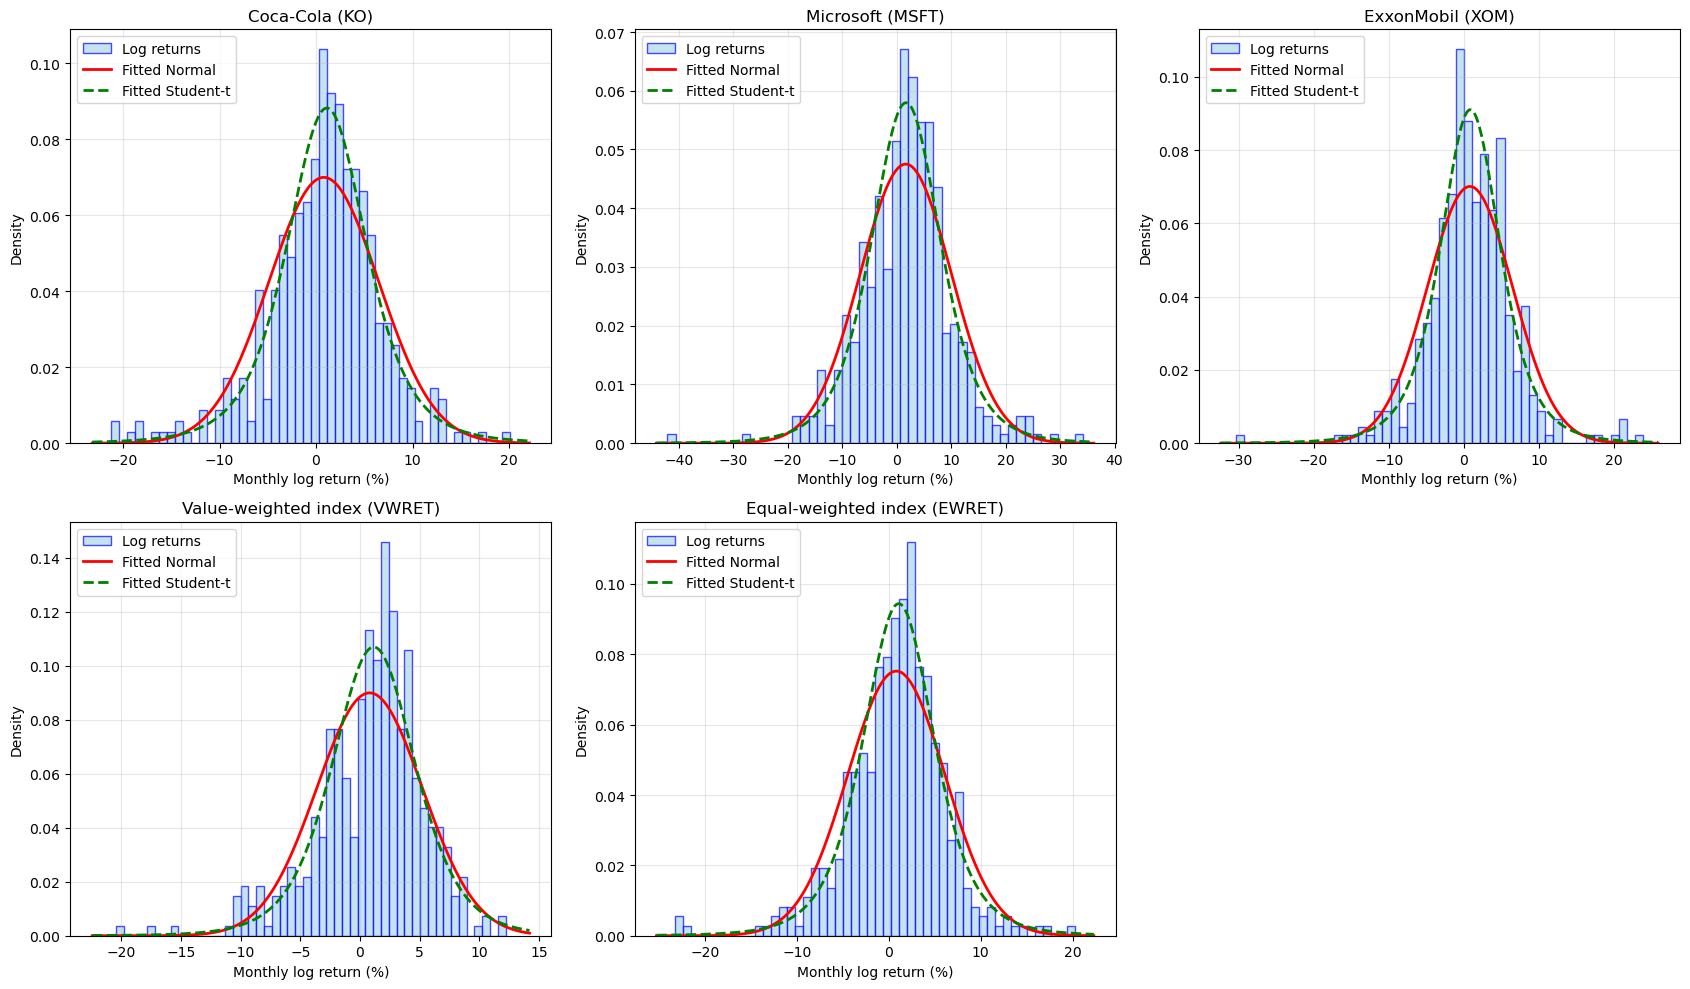

In [16]:
# Histograms of the log returns with a fitted Normal density (sample mean and std) and, for comparison, a fitted Student-t
fig, axes = plt.subplots(2, 3, figsize=(17, 10))
for ax, col in zip(axes.flat, logret.columns):
    x_ = logret[col] * 100
    grid = np.linspace(x_.min() - 2, x_.max() + 2, 400)
    ax.hist(x_, bins=50, density=True, color='lightblue', edgecolor='blue', alpha=0.7, label='Log returns')
    ax.plot(grid, stats.norm.pdf(grid, x_.mean(), x_.std()), color='red', lw=2, label='Fitted Normal')
    ax.plot(grid, stats.t.pdf(grid, *stats.t.fit(x_)), color='green', lw=2, ls='--', label='Fitted Student-t')
    ax.set_title(f'{names[col]} ({col})')
    ax.set_xlabel('Monthly log return (%)')
    ax.set_ylabel('Density')
    ax.legend(loc='upper left')
    ax.grid(True, alpha=0.3)
axes.flat[-1].axis('off')
plt.tight_layout()
plt.show()

In [17]:
# Jarque-Bera test: JB = T/6 * (S^2 + (K-3)^2/4) ~ chi2(2) under normality (note: K is the raw kurtosis here, not excess)
jb = pd.DataFrame([jarque_bera(logret[c]) for c in logret], index=logret.columns,
                  columns=['JB stat', 'p-value', 'Skewness', 'Kurtosis'])
jb['Skewness part'] = T / 6 * jb['Skewness']**2                   # contribution of skewness to JB
jb['Kurtosis part'] = T / 24 * (jb['Kurtosis'] - 3)**2            # contribution of excess kurtosis to JB
jb['5% critical value'] = stats.chi2.ppf(0.95, 2)
jb['Reject normality at 5%'] = jb['p-value'] < 0.05
jb.round(4)

,JB stat,p-value,Skewness,Kurtosis,Skewness part,Kurtosis part,5% critical value,Reject normality at 5%
KO,83.6492,0.0,-0.5666,4.8697,22.4703,61.1789,5.9915,True
MSFT,108.4159,0.0,-0.1146,5.4784,0.9198,107.4962,5.9915,True
XOM,234.3667,0.0,-0.0931,6.6548,0.6065,233.7601,5.9915,True
VWRET,106.6334,0.0,-0.8299,4.8272,48.2087,58.4246,5.9915,True
EWRET,158.9288,0.0,-0.5769,5.7840,23.2933,135.6356,5.9915,True


In [18]:
# How non-Normal are the tails? Standardized returns vs. Normal benchmarks, and a likelihood comparison Normal vs. Student-t
z = (logret - logret.mean()) / logret.std()
tfit = {c: stats.t.fit(logret[c]) for c in logret}                 # (degrees of freedom, location, scale)
ll_norm = pd.Series({c: stats.norm.logpdf(logret[c], logret[c].mean(), logret[c].std(ddof=0)).sum() for c in logret})
ll_t = pd.Series({c: stats.t.logpdf(logret[c], *tfit[c]).sum() for c in logret})
pd.DataFrame({'Share within ±1σ (Normal: 0.683)': (z.abs() < 1).mean(),
              'Obs. beyond ±3σ': (z.abs() > 3).sum(),
              'Expected beyond ±3σ (Normal)': T * 2 * stats.norm.sf(3),
              '1% quantile (%)': logret.quantile(0.01) * 100,
              '1% quantile, Normal (%)': (logret.mean() + stats.norm.ppf(0.01) * logret.std()) * 100,
              'Student-t degrees of freedom': pd.Series({c: tfit[c][0] for c in logret}),
              'Log-lik. Normal': ll_norm, 'Log-lik. Student-t': ll_t,
              'LR stat (t vs. Normal)': 2 * (ll_t - ll_norm)}).T.round(3)

,KO,MSFT,XOM,VWRET,EWRET
Share within ±1σ (Normal: 0.683),0.757,0.733,0.776,0.738,0.745
Obs. beyond ±3σ,7.000,4.000,8.000,3.000,5.000
Expected beyond ±3σ (Normal),1.134,1.134,1.134,1.134,1.134
1% quantile (%),-17.778,-17.693,-13.681,-10.549,-13.506
"1% quantile, Normal (%)",-12.458,-17.860,-12.444,-9.520,-11.513
Student-t degrees of freedom,4.227,4.954,4.083,5.460,4.491
Log-lik. Normal,607.646,445.007,608.460,712.929,638.058
Log-lik. Student-t,624.813,460.624,635.193,724.233,658.192
LR stat (t vs. Normal),34.335,31.234,53.466,22.608,40.268


**No, none of the five log-return series follows a Normal distribution. Every histogram is more peaked in the centre than the fitted Normal curve, has too few observations in the "shoulders", and shows extreme months far out in the tails, especially the left tail, where the Normal density is practically zero. The Jarque–Bera test rejects normality for every series with $p$-values below $10^{-18}$. Whether the indices are closer to normality than the stocks depends on the dimension: the VW index has the thinnest tails of all series, as diversification would suggest, but it is also the most asymmetric, so by the JB statistic Coca-Cola is in fact the closest to Normal and ExxonMobil the furthest. A fat-tailed distribution such as the Student-$t$ (with about 4–5.5 degrees of freedom) fits much better, ideally in a skewed form or combined with time-varying volatility.**

**1. What the histograms show.** The red Normal curve uses each series' sample mean and standard deviation, so it has exactly the same first two moments as the data. Nevertheless, three deviations are visible in every panel:
- *Too peaked.* The bars around the mean rise well above the red curve. Between 73% and 78% of all months lie within $\pm1\sigma$ of the mean, compared with 68.3% under normality. Calm months are more common than a Normal distribution suggests.
- *Thin shoulders.* Between roughly one and two standard deviations, the bars lie *below* the red curve.
- *Fat tails.* Far in the tails, there are observations where the Normal density is practically zero. Under normality, we would expect about 1.1 months beyond $\pm3\sigma$ in 420 months. We observe 7 for KO, 4 for MSFT, 8 for XOM, 3 for VW and 5 for EW. The most extreme months are $-5.2\sigma$ (MSFT, April 2000), $-5.5\sigma$ (XOM, March 2020), $-4.8\sigma$ (VW, October 2008) and $-4.5\sigma$ (EW, March 2020).

The left tail is longer than the right one in all panels, which is the negative skewness of (f) in visual form. The green Student-$t$ curve follows the peak, the shoulders and the tails clearly better.

**2. Relation to the summary statistics.** The histograms are a picture of the third and fourth moments computed in (f). The peak and the fat tails *are* the positive excess kurtosis (1.86–3.71), and the longer left tail *is* the negative skewness. Since the Normal curve is fitted to the variance, a distribution with more mass in both the centre and the tails must have less in between, which explains the thin shoulders. The Jarque–Bera test formalizes exactly these two moments:
$$JB = \frac{T}{6}\left(\hat S^2 + \frac{(\hat K - 3)^2}{4}\right) \;\overset{a}{\sim}\; \chi^2_2 \text{ under } H_0: \text{normality}, \qquad \chi^2_{2,\,0.95} = 5.99$$

| | JB stat | $p$-value | Skewness part | Kurtosis part | Decision |
|---|---|---|---|---|---|
| KO | 83.6 | $7\times10^{-19}$ | 22.5 (27%) | 61.2 (73%) | Reject |
| MSFT | 108.4 | $3\times10^{-24}$ | 0.9 (1%) | 107.5 (99%) | Reject |
| XOM | 234.4 | $1\times10^{-51}$ | 0.6 (0%) | 233.8 (100%) | Reject |
| VWRET | 106.6 | $7\times10^{-24}$ | 48.2 (45%) | 58.4 (55%) | Reject |
| EWRET | 158.9 | $3\times10^{-35}$ | 23.3 (15%) | 135.6 (85%) | Reject |

Even the series closest to normality (KO) has a JB statistic 14 times the critical value. The rejection is overwhelming for all five series, which confirms the visual impression.

**3. Indices or individual stocks: which is closer to Normal?** The intuitive answer is the indices, since by the Central Limit Theorem the average of many returns should be close to Normal. The data only partly support this:
- *In terms of tail thickness, yes.* The VW index has the lowest excess kurtosis of all five series (1.86), below each of the three stocks (1.91–3.71). Firm-specific jumps such as Microsoft's antitrust ruling or ExxonMobil's oil shocks are diversified away in a portfolio of thousands of stocks.
- *In terms of symmetry, no.* The VW index is the *most* negatively skewed series ($-0.83$), and almost half of its JB statistic (45%) comes from skewness. For Microsoft and ExxonMobil, the skewness contribution is practically zero.
- *The CLT argument fails because returns are not independent.* The CLT requires the averaged components to be (roughly) independent. Stock returns share a common market factor, and their correlations increase in crashes (see (e)). Diversification removes the independent, idiosyncratic part of the risk, which is why the index has thinner tails, but it cannot remove the common crash risk, which is why the index is more negatively skewed. What remains in the index is precisely the non-Normal, systematic part.
- *The EW index is further from normality than the VW index* (JB 158.9 vs. 106.6), with fatter tails (2.83), because it gives large weights to small stocks, whose returns are more extreme.

**By the JB statistic, the ranking from closest to furthest from normality is KO (83.6) < VW (106.6) ≈ MSFT (108.4) < EW (158.9) < XOM (234.4).** There is therefore no clear pattern of "indices closer than stocks". The VW index is close to normality in the tails but far from it in symmetry. The individual stocks, in contrast, are roughly symmetric (in logs) but more fat-tailed, ExxonMobil most of all.

**4. Which distribution would fit better?**
- ***Student-$t$ distribution.*** It has fatter tails than the Normal, controlled by the degrees of freedom $\nu$, and converges to the Normal as $\nu \to \infty$. The estimated values are low: about 4.1 for XOM, 4.2 for KO, 4.5 for EW, 5.0 for MSFT and 5.5 for VW. Since a $t$-distribution has finite kurtosis only if $\nu > 4$, these estimates indicate very fat tails. The likelihood clearly favours the $t$: the likelihood-ratio statistics range from 22.6 (VW) to 53.5 (XOM), far above the 5% critical value of 3.84 for one restriction. (Strictly speaking, the Normal is the boundary case $\nu \to \infty$, so the LR statistic does not follow a standard $\chi^2_1$ distribution, but the margins are so large that the conclusion is unaffected.) The green curves in the histograms illustrate the better fit.
- ***Skewed Student-$t$*** (e.g. Hansen, 1994). The standard $t$ is symmetric and therefore cannot capture the negative skewness, which is particularly relevant for the indices. A skewed $t$ adds an asymmetry parameter and can capture both features.
- ***Normal mixtures / regime-switching models.*** A mixture of a "calm" Normal regime with low volatility and a "turbulent" regime with high volatility produces exactly the observed shape: a high peak (from the calm regime) and fat tails (from the turbulent one). This corresponds directly to the alternating calm and turbulent periods seen in (c).
- ***Conditional models (GARCH).*** Perhaps the most important insight is that much of the unconditional non-normality comes from *time-varying volatility*. The squared returns are clearly autocorrelated (0.18–0.25, see (g)). If returns were Normal *conditional on* the current volatility, but volatility changed over time, the unconditional distribution would still be fat-tailed. GARCH models with Normal or, better, Student-$t$ innovations (Bollerslev, 1987) capture this and are the standard approach in practice.
- *Other candidates.* Stable Paretian distributions (Mandelbrot, 1963; Fama, 1965) have even fatter tails and infinite variance. They are, however, contradicted by the fact that returns become closer to Normal at longer horizons (daily returns are much more fat-tailed than monthly ones), which would not happen if the variance were infinite. Jump-diffusion models (Merton, 1976) explicitly model rare crashes such as October 2008 or March 2020.

**5. Why this matters.** Assuming normality systematically understates the risk of extreme losses. The empirical 1% quantile of Coca-Cola's monthly log return is $-17.8\%$, while the Normal distribution predicts $-12.5\%$. For the VW index the values are $-10.6\%$ and $-9.5\%$, and for the EW index $-13.5\%$ and $-11.5\%$. Risk managers who calculate Value-at-Risk with a Normal distribution will therefore underestimate their tail risk, typically exactly in the crisis periods in which it matters most. Normality-based inference such as the $t$-tests in (g) and (i), on the other hand, remains approximately valid, because with $T = 420$ the CLT applies to sample *means* and *regression coefficients*, even if the returns themselves are not Normal.

# 1 (i)

In [19]:
# CAPM regression r_i,t = alpha_i + beta_i * r_m,t + e_i,t with the VW index as market proxy and rf = 0
X = sm.add_constant(logret['VWRET'])
capm = {c: sm.OLS(logret[c], X).fit() for c in stocks}
for c in stocks:
    print(f'=== {names[c]} ({c}) ===   R² = {capm[c].rsquared:.3f},  T = {int(capm[c].nobs)}')
    print(capm[c].summary().tables[1], '\n')

=== Coca-Cola (KO) ===   R² = 0.190,  T = 420
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0036      0.003      1.396      0.163      -0.001       0.009
VWRET          0.5601      0.057      9.902      0.000       0.449       0.671

=== Microsoft (MSFT) ===   R² = 0.331,  T = 420
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0080      0.003      2.352      0.019       0.001       0.015
VWRET          1.0886      0.076     14.377      0.000       0.940       1.237

=== ExxonMobil (XOM) ===   R² = 0.239,  T = 420
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0029      0.002      1.178      0.239      -0.002

In [20]:
# Summary table with robustness checks: White (heteroskedasticity-robust) and Newey-West (HAC, 6 lags) t-statistics,
# a test of beta = 1, and the alpha obtained when the regression is run on simple instead of log returns
white = {c: sm.OLS(logret[c], X).fit(cov_type='HC0') for c in stocks}
nw = {c: sm.OLS(logret[c], X).fit(cov_type='HAC', cov_kwds={'maxlags': 6}) for c in stocks}
simple = {c: sm.OLS(ret[c], sm.add_constant(ret['VWRET'])).fit() for c in stocks}

pd.DataFrame({c: {'Alpha (% per month)': capm[c].params['const'] * 100,
                  'Alpha (% p.a., x12)': capm[c].params['const'] * 1200,
                  't(alpha)': capm[c].tvalues['const'],
                  'p(alpha)': capm[c].pvalues['const'],
                  't(alpha), White': white[c].tvalues['const'],
                  't(alpha), Newey-West': nw[c].tvalues['const'],
                  'Beta': capm[c].params['VWRET'],
                  '95% CI beta, low': capm[c].conf_int().loc['VWRET', 0],
                  '95% CI beta, high': capm[c].conf_int().loc['VWRET', 1],
                  't(beta)': capm[c].tvalues['VWRET'],
                  't(beta), White': white[c].tvalues['VWRET'],
                  't(beta), Newey-West': nw[c].tvalues['VWRET'],
                  't(beta = 1)': (capm[c].params['VWRET'] - 1) / capm[c].bse['VWRET'],
                  'p(beta = 1)': 2 * stats.t.sf(abs((capm[c].params['VWRET'] - 1) / capm[c].bse['VWRET']), capm[c].df_resid),
                  'R²': capm[c].rsquared,
                  'Residual std. dev. (%)': np.sqrt(capm[c].scale) * 100,
                  'Appraisal ratio p.a. (alpha / resid. sd)': capm[c].params['const'] / np.sqrt(capm[c].scale) * np.sqrt(12),
                  'Alpha, simple returns (% per month)': simple[c].params['const'] * 100} for c in stocks}).round(3)

,KO,MSFT,XOM
Alpha (% per month),0.356,0.802,0.290
"Alpha (% p.a., x12)",4.268,9.624,3.484
t(alpha),1.396,2.352,1.178
p(alpha),0.163,0.019,0.239
"t(alpha), White",1.382,2.370,1.108
"t(alpha), Newey-West",1.509,2.481,0.996
Beta,0.560,1.089,0.627
"95% CI beta, low",0.449,0.940,0.519
"95% CI beta, high",0.671,1.237,0.734
t(beta),9.902,14.377,11.453


In [21]:
# Stability: alpha in % per month (t-stat in brackets) by sub-period
pd.DataFrame({f'{a}-{b}': {c: '{:.2f} ({:.2f})'.format(m.params['const'] * 100, m.tvalues['const'])
                           for c in stocks
                           for m in [sm.OLS(logret.loc[a:b, c], sm.add_constant(logret.loc[a:b, 'VWRET'])).fit()]}
              for a, b in periods})

,1990-1999,2000-2009,2010-2019,2020-2024
KO,0.33 (0.57),0.17 (0.33),0.42 (1.27),-0.13 (-0.22)
MSFT,2.22 (2.98),-0.39 (-0.51),0.61 (1.34),0.89 (1.48)
XOM,0.58 (1.76),0.61 (1.38),-0.59 (-1.79),0.19 (0.17)


**The estimated alphas are 0.36% per month for Coca-Cola (≈ 4.3% p.a.), 0.80% for Microsoft (≈ 9.6% p.a.) and 0.29% for ExxonMobil (≈ 3.5% p.a.). The estimated betas are 0.56, 1.09 and 0.63. All three betas are highly significant ($t$ between 9.9 and 14.4). Coca-Cola's and ExxonMobil's betas are also significantly *below one*, while Microsoft's cannot be distinguished from one. All alphas are positive and economically large, but only Microsoft's is statistically significant ($t = 2.35$, $p = 0.019$). Coca-Cola's ($t = 1.40$) and ExxonMobil's ($t = 1.18$) are not. These conclusions are robust to heteroskedasticity- and autocorrelation-robust standard errors.**

**Model.** With the risk-free rate set to zero, the CAPM regression is
$$r_{i,t} = \alpha_i + \beta_i\, r_{m,t} + \varepsilon_{i,t}, \qquad \beta_i = \frac{\text{Cov}(r_i, r_m)}{\text{Var}(r_m)}$$
The CAPM states that expected returns are fully explained by market exposure, $E[r_i] = \beta_i E[r_m]$, so it predicts $\alpha_i = 0$. The beta measures how strongly a stock reacts to market movements (its systematic risk). The alpha (Jensen's alpha) is the average return that is *not* explained by the stock's market exposure.

| | $\hat\alpha$ (% / month) | $t(\alpha)$ | $p(\alpha)$ | $\hat\beta$ | 95% CI for $\beta$ | $t(\beta)$ | $t(\beta = 1)$ | $R^2$ |
|---|---|---|---|---|---|---|---|---|
| KO | 0.356 | 1.40 | 0.163 | 0.560 | [0.45, 0.67] | 9.90 | $-7.78$ | 0.190 |
| MSFT | 0.802 | 2.35 | 0.019 | 1.089 | [0.94, 1.24] | 14.38 | 1.17 | 0.331 |
| XOM | 0.290 | 1.18 | 0.239 | 0.627 | [0.52, 0.73] | 11.45 | $-6.82$ | 0.239 |

**1. Betas: interpretation and significance**
- *Statistical significance.* All three betas are significantly different from zero by a wide margin ($p < 10^{-20}$). More informative is the test against $\beta = 1$, the beta of the average stock. Coca-Cola ($t = -7.78$) and ExxonMobil ($t = -6.82$) have betas significantly below one, which makes them **defensive stocks** in the statistical sense too. Microsoft's beta of 1.09 is not significantly different from one ($t = 1.17$, $p = 0.24$), so it carries average market risk (its confidence interval [0.94, 1.24] includes one).
- *Economic meaning.* A 1 pp higher monthly market return is, on average, associated with a 0.56 pp higher return for Coca-Cola, 1.09 pp for Microsoft and 0.63 pp for ExxonMobil. Coca-Cola's demand barely depends on the business cycle. ExxonMobil's returns depend mainly on the oil price, which is only partly linked to the stock market. Microsoft's earnings depend on corporate IT spending, and as a growth stock its value is sensitive to discount-rate changes.
- *Economic significance: the cost of capital.* Under the CAPM, beta determines the required return, $E[r_i] - r_f = \beta_i\,(E[r_m] - r_f)$. With a market risk premium of, say, 6% p.a., investors would require a premium of only 3.4% for Coca-Cola and 3.8% for ExxonMobil, but 6.5% for Microsoft. The difference in beta translates into a difference of about 3 pp in the annual cost of equity, which matters a lot for valuation and capital budgeting. For a portfolio manager, adding KO or XOM to a market portfolio lowers its overall beta, while MSFT leaves it essentially unchanged.

**2. Alphas: economic vs. statistical significance**
- *Economic significance.* The alphas are large. Annualized, Microsoft earned about 9.6% p.a. more than its market exposure justifies, Coca-Cola 4.3% and ExxonMobil 3.5%. Splitting each stock's mean return into the part explained by the market ($\hat\beta\,\bar r_m$) and alpha:

| | Mean return | $\hat\beta \times \bar r_m$ (explained by market) | $\hat\alpha$ (unexplained) | Share unexplained |
|---|---|---|---|---|
| KO | 0.805% | 0.449% | 0.356% | 44% |
| MSFT | 1.675% | 0.873% | 0.802% | 48% |
| XOM | 0.793% | 0.502% | 0.290% | 37% |

Between 37% and 48% of each stock's average return is *not* explained by its market exposure. In terms of point estimates, the CAPM explains these three stocks' returns poorly. Coca-Cola and ExxonMobil earned about the same average return as the market (0.80%) with only 56–63% of its systematic risk, which, if taken at face value, is exactly what an alpha means.
- *Statistical significance.* Only Microsoft's alpha is significant at the 5% level ($t = 2.35$, $p = 0.019$). Coca-Cola's ($p = 0.16$) and ExxonMobil's ($p = 0.24$) are not. For these two stocks, we cannot reject the CAPM's prediction $\alpha = 0$, even though the point estimates are economically large.
- *Why large alphas can be insignificant: low power.* The standard errors of the alphas are 0.25–0.34% per month, so an alpha has to exceed roughly 0.5–0.7% per month (6–8% p.a.) to be significant. The reason is the large idiosyncratic volatility seen in (e). The $t$-statistic of alpha is approximately the *appraisal ratio* (alpha per unit of residual risk) times the square root of the number of years:
$$t(\hat\alpha) \approx \frac{\hat\alpha}{\hat\sigma_\varepsilon}\sqrt{T} = \underbrace{\frac{\hat\alpha}{\hat\sigma_\varepsilon}\sqrt{12}}_{\text{appraisal ratio p.a.}} \times \sqrt{\text{years}}$$
The annualized appraisal ratios are 0.24 (KO), 0.40 (MSFT) and 0.20 (XOM). For Coca-Cola's alpha to be significant at this appraisal ratio, about $(1.96/0.24)^2 \approx 67$ years of data would be needed, compared with about 24 years for Microsoft. Failing to reject $\alpha = 0$ therefore does not show that the alpha is zero. It shows that, given the noise, 35 years of data are not enough to tell. This is the same estimation problem as for the mean returns in (g), only worse, since the alpha is a *difference* of noisy means.

**3. Robustness of the inference.** As seen in (c) and (e), volatility varies over time and the residuals are fat-tailed, so the classical OLS standard errors may be unreliable. Using heteroskedasticity-robust (White) and Newey–West standard errors:

| | $t(\alpha)$: OLS / White / NW | $t(\beta)$: OLS / White / NW |
|---|---|---|
| KO | 1.40 / 1.38 / 1.51 | 9.90 / 7.79 / 7.75 |
| MSFT | 2.35 / 2.37 / 2.48 | 14.38 / 14.01 / 12.24 |
| XOM | 1.18 / 1.11 / 1.00 | 11.45 / 8.10 / 6.26 |

The robust standard errors for the betas are considerably larger for Coca-Cola and ExxonMobil (their $t$-statistics drop by 20–45%). Their residual volatility is higher in months with extreme market returns, which is the heteroskedasticity anticipated in (e). White standard errors become larger than the classical ones exactly when the residual variance increases with the squared regressor. All betas, however, remain overwhelmingly significant, and the conclusions about the alphas are unchanged: only Microsoft's is significant. With $T = 420$, the non-normality of the residuals does not invalidate the inference, because the coefficient estimates are approximately Normal by the CLT.

**4. Alpha is not stable over time.** Alpha by decade (in % per month, $t$-statistic in brackets):

| | 1990–1999 | 2000–2009 | 2010–2019 | 2020–2024 |
|---|---|---|---|---|
| KO | 0.33 (0.57) | 0.17 (0.33) | 0.42 (1.27) | $-0.13$ ($-0.22$) |
| MSFT | **2.22 (2.98)** | $-0.39$ ($-0.51$) | 0.61 (1.34) | 0.89 (1.48) |
| XOM | 0.58 (1.76) | 0.61 (1.38) | $-0.59$ ($-1.79$) | 0.19 (0.17) |

Microsoft's significant full-sample alpha comes mainly from the 1990s, when it rose to dominate the PC software market (2.22% per month, i.e. over 26% p.a. of abnormal return). In the 2000s, after the dot-com bust and the antitrust case, its alpha was negative. ExxonMobil's alpha changed sign between the 2000s commodity boom and the 2010s oil glut. No decade alpha other than Microsoft's in the 1990s is significant. This is not what a persistent, exploitable mispricing would look like. It is more consistent with periods of unexpectedly good (or bad) news for individual firms.

**5. Why are all three alphas positive? Possible explanations**
- *Look-ahead and survivorship bias.* As discussed in (g), these three firms were selected *ex post* as successful survivors. The CAPM is a model of *expected* returns, whereas the alphas measure *realized* returns. Positive surprises over 35 years, such as Microsoft's dominance of software and later of cloud computing, show up as alpha even if the stocks were priced correctly *ex ante*. This is probably the most important reason why we should not conclude that these stocks were "mispriced".
- *The zero risk-free rate assumption.* If the true model is $r_i - r_f = \alpha^*_i + \beta_i(r_m - r_f) + \varepsilon_i$, then rearranging gives $r_i = [\alpha^*_i + (1-\beta_i)\,r_f] + \beta_i\, r_m + \varepsilon_i$. Our regression therefore estimates $\alpha_i = \alpha^*_i + (1-\beta_i)\,r_f$. With an average risk-free rate of roughly 0.2% per month, this mechanically adds about $(1-0.56)\times0.2 \approx 0.09\%$ per month (≈ 1.1% p.a.) to Coca-Cola's alpha and about 0.08% to ExxonMobil's, while it reduces Microsoft's by about 0.02%. Low-beta stocks thus get an upward-biased alpha. With proper excess returns, the alphas of KO and XOM would be even smaller and even less significant.
- *Log vs. simple returns.* The CAPM is a model for simple returns. Since $E[R] \approx E[r] + \sigma^2/2$, the alpha in simple returns is approximately $\alpha^{simple} \approx \alpha^{log} + \sigma_i^2/2 - \beta_i\,\sigma_m^2/2$. Stocks with high idiosyncratic volatility therefore have a *higher* alpha in simple returns. Running the regression on simple returns indeed gives larger alphas (see the last row of the table above), so the log specification understates the alphas somewhat.
- *The low-beta anomaly.* Empirically, low-beta stocks have earned higher returns than the CAPM predicts, and high-beta stocks lower ones, so the security market line is "too flat" (Black, Jensen & Scholes, 1972; Frazzini & Pedersen, 2014, "Betting Against Beta"). Coca-Cola's and ExxonMobil's positive alphas with betas around 0.6 are consistent with this pattern.
- *Missing risk factors.* The CAPM uses only the market factor. Coca-Cola and ExxonMobil are large, profitable value stocks, and Microsoft is a highly profitable firm. Multi-factor models (Fama–French three- and five-factor models, Carhart momentum) would attribute part of these alphas to exposures to value, profitability or momentum.
- *The market proxy.* The CAPM refers to the market portfolio of *all* risky assets, including bonds, real estate and human capital. The VW stock index is only a proxy, and strictly speaking the CAPM cannot be tested without the true market portfolio (Roll, 1977). Part of what appears as alpha could be exposure to the parts of the market that the proxy leaves out.

**6. What about the $R^2$?** The market explains only 19–33% of the monthly variation in the three stocks. This does *not* contradict the CAPM. The CAPM is a statement about *expected* returns (alpha should be zero), not about how much of the month-to-month variation is explained by the market. A low $R^2$ simply means that idiosyncratic risk is large, which by the CAPM's own logic should be diversified away and is not priced. For the investor, it does mean that holding any single one of these stocks involves a lot of risk that is not rewarded.

**Conclusion.** The betas are precisely estimated and economically meaningful: Microsoft carries roughly market-level systematic risk, while Coca-Cola and ExxonMobil are clearly defensive. The CAPM's central prediction of zero alpha cannot be rejected for Coca-Cola and ExxonMobil, but it is rejected for Microsoft at the 5% level. Given the selection bias, the zero risk-free rate assumption and the instability of the alphas over time, this rejection is better seen as evidence of Microsoft's extraordinary realized success than as evidence of a persistent mispricing. A formal test of whether the three alphas are *jointly* zero would require the Gibbons–Ross–Shanken (1989) test, and a fair assessment of the CAPM would use excess returns and a broad, ex-ante selection of stocks instead of three famous winners.

# 2. Net Financial Wealth, Income and Age

Throughout, `nettfa` is net total financial assets (financial assets minus non-mortgage debt, so it can be negative), `inc` is annual family income, `age` is the respondent's age in years and `fsize` is the number of people in the household. Wealth and income are both measured in thousands of US dollars, so a coefficient of 1 in a regression of `nettfa` on `inc` means that \$1,000 more annual income goes along with \$1,000 more net financial wealth. The data are a single cross-section of US households (the variable set appears to correspond to the 401(k) survey data used in Wooldridge's econometrics textbook, which come from the early-1990s Survey of Income and Program Participation). All statements below therefore compare *different* households at one point in time, not the same household over time.

# 2 (a)

In [22]:
# Load the Stata file and read the variable labels stored in it (used as a small codebook)
pension = pd.read_stata('pension.dta')
with pd.read_stata('pension.dta', iterator=True) as reader:
    labels = reader.variable_labels()

print('Shape:', pension.shape, '| Missing values:', pension.isna().sum().sum())
print(pd.DataFrame({'Label': labels, 'Mean': pension.mean(), 'Median': pension.median(),
                    'Min': pension.min(), 'Max': pension.max()}).round(2))
pension.head()

Shape: (9275, 11) | Missing values: 0
                               Label     Mean   Median         Min           Max
e401k       =1 if eligble for 401(k)     0.39     0.00    0.000000      1.000000
inc            annual income, $1000s    39.25    33.29   10.010000    199.039993
marr                   =1 if married     0.63     1.00    0.000000      1.000000
male           =1 if male respondent     0.20     0.00    0.000000      1.000000
age                         in years    41.08    40.00   25.000000     64.000000
fsize                    family size     2.89     3.00    1.000000     13.000000
nettfa  net total fin. assets, $1000    19.07     2.00 -502.299988   1536.800049
p401k    =1 if participate in 401(k)     0.28     0.00    0.000000      1.000000
pira                  =1 if have IRA     0.25     0.00    0.000000      1.000000
incsq                          inc^2  2121.19  1108.09  100.160004  39617.320312
agesq                          age^2  1793.65  1600.00  625.000000   40

,e401k,inc,marr,male,age,fsize,nettfa,p401k,pira,incsq,agesq
0,0,13.170000,0,0,40,1,4.575000,0,1,173.448898,1600
1,1,61.230000,0,1,35,1,154.000000,1,0,3749.112793,1225
2,0,12.858000,1,0,44,2,0.000000,0,0,165.328156,1936
3,0,98.879997,1,1,44,2,21.799999,0,0,9777.253906,1936
4,0,22.614000,0,0,53,1,18.450001,0,0,511.393005,2809


**The data set contains 9,275 households and 11 variables with no missing values. Besides the four variables used in this question (`nettfa`, `inc`, `age`, `fsize`), it includes dummies for 401(k) eligibility and participation, IRA ownership, marital status and the gender of the respondent, as well as the squares of income and age.**

A few features of the data are important for the regressions that follow:

- **Net financial wealth is extremely skewed.** The mean is \$19,070, but the median is only \$2,000. Values range from $-\$502,300$ to $+\$1,536,800$, and at least a quarter of all households have zero or negative net financial assets. A small number of very wealthy households pull the mean far above the typical household. OLS estimates the *conditional mean*, so these households will have a large influence on the coefficients.
- **The sample is restricted by design.** Income ranges from about \$10,000 to \$199,000 and age from 25 to 64. The sample therefore covers working-age households only, with no retirees and no very low incomes. This matters for interpreting the intercept in (d) and the age effects.
- **Family size** ranges from 1 to 13 persons, with a mean of 2.9.
- The squared terms `incsq` and `agesq` are already provided, which anticipates the quadratic specification in (h).

# 2 (b)

In [23]:
# Single-person households are those with family size equal to one
single = pension[pension['fsize'] == 1]
print(f'Single-person households: {len(single)} of {len(pension)} ({len(single) / len(pension):.2%} of the sample)\n')

# Distribution of household size (number and share of households)
fs = pension['fsize'].value_counts().sort_index()
print(pd.DataFrame({'Households': fs, 'Share (%)': fs / len(pension) * 100}).T.round(1), '\n')

# How do single-person households differ from larger households?
cols = ['nettfa', 'inc', 'age', 'male', 'marr', 'e401k', 'p401k', 'pira']
larger = pension[pension['fsize'] > 1]
print('Medians (nettfa, inc, age): singles', single[['nettfa', 'inc', 'age']].median().round(2).to_dict(),
      '| larger households', larger[['nettfa', 'inc', 'age']].median().round(2).to_dict())
pd.DataFrame({'Singles (mean)': single[cols].mean(), 'Larger households (mean)': larger[cols].mean()}).round(3)

Single-person households: 2017 of 9275 (21.75% of the sample)

fsize           1       2       3       4      5      6     7     8    9    10   11   12   13
Households  2017.0  2199.0  1829.0  1990.0  816.0  268.0  95.0  38.0  7.0  7.0  3.0  4.0  2.0
Share (%)     21.7    23.7    19.7    21.5    8.8    2.9   1.0   0.4  0.1  0.1  0.0  0.0  0.0 

Medians (nettfa, inc, age): singles {'nettfa': 1.4, 'inc': 25.25, 'age': 37.0} | larger households {'nettfa': 2.25, 'inc': 36.41, 'age': 40.0}


,Singles (mean),Larger households (mean)
nettfa,13.595,20.594
inc,29.446,41.980
age,39.278,41.581
male,0.542,0.111
marr,0.018,0.798
e401k,0.360,0.401
p401k,0.243,0.285
pira,0.214,0.266


**There are 2,017 single-person households (`fsize` = 1). They make up 21.75% of the full sample of 9,275 households, a little more than one in five.**

**Household size distribution.** Singles are the second-largest group after two-person households (23.7%), followed by four-person (21.5%) and three-person households (19.7%). Households with five or more members together make up only about 13% of the sample.

| Size | 1 | 2 | 3 | 4 | 5 | 6+ |
|---|---|---|---|---|---|---|
| Households | 2,017 | 2,199 | 1,829 | 1,990 | 816 | 424 |
| Share | 21.7% | 23.7% | 19.7% | 21.5% | 8.8% | 4.6% |

**Singles are a distinct subpopulation.** Compared with larger households, single-person households are poorer, slightly younger and very different in their composition:

| | Singles | Larger households |
|---|---|---|
| Mean net financial wealth | \$13,595 | \$20,594 |
| Median net financial wealth | \$1,400 | \$2,250 |
| Mean income | \$29,446 | \$41,980 |
| Median income | \$25,245 | \$36,414 |
| Mean age | 39.3 | 41.6 |
| Male respondent | 54.2% | 11.1% |
| Married | 1.8% | 79.8% |
| Eligible for a 401(k) | 36.0% | 40.1% |
| Participates in a 401(k) | 24.3% | 28.5% |
| Has an IRA | 21.4% | 26.6% |

- *Lower income and wealth.* A large part of the gap comes from the fact that larger households often have two earners, while a single-person household has at most one. Average income is about 30% lower for singles, and median income about 31% lower.
- *Less access to and use of retirement saving plans.* Singles are less often eligible for a 401(k), less often participate and less often own an IRA, so they save less through tax-advantaged channels.
- *Gender.* The `male` variable refers to the *survey respondent*. In multi-person households, the respondent is mostly female (only 11% male), whereas among singles the respondent is by definition the only adult and 54% are men.
- *Data quirk.* 1.8% of the single-person households (37 households) report being married, presumably because their spouse lives elsewhere. "Single-person household" (household size) and "single" (marital status) are therefore not exactly the same. Following the question, we define the subsample by household size, and we treat "single-person" in (b) and "single-head" in (c) as the same group, `fsize` = 1.

**Why estimate the model on singles only?** In a single-person household, income, age and wealth all refer to *one* person. In larger households, wealth and income are pooled across several adults, and the age of the respondent may not be representative of the household. Restricting the sample to singles makes the link between a person's income, age and wealth much cleaner. It also removes family size, and the different needs and saving motives that come with children, as a confounding factor.

# 2 (c)

In [24]:
# OLS regression (1): nettfa = b0 + b1*inc + b2*age + u, single-person households only
model_c = smf.ols('nettfa ~ inc + age', data=single).fit()
print(model_c.summary())

                            OLS Regression Results                            
Dep. Variable:                 nettfa   R-squared:                       0.119
Model:                            OLS   Adj. R-squared:                  0.118
Method:                 Least Squares   F-statistic:                     136.5
Date:                Sun, 08 Nov 2026   Prob (F-statistic):           2.63e-56
Time:                        12:52:53   Log-Likelihood:                -10524.
No. Observations:                2017   AIC:                         2.105e+04
Df Residuals:                    2014   BIC:                         2.107e+04
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept    -43.0398      4.080    -10.548      0.0

In [25]:
# Economic magnitude and robustness of the estimates:
# effect of a one-standard-deviation increase, White (heteroskedasticity-robust) t-statistics,
# median (LAD) regression, and OLS without the top and bottom 1% of wealth
robust_c = smf.ols('nettfa ~ inc + age', data=single).fit(cov_type='HC1')
lad_c = smf.quantreg('nettfa ~ inc + age', data=single).fit(q=0.5)
trim = single[single['nettfa'].between(single['nettfa'].quantile(0.01), single['nettfa'].quantile(0.99))]
trim_c = smf.ols('nettfa ~ inc + age', data=trim).fit()

print(f"Correlation between inc and age among singles: {single['inc'].corr(single['age']):.3f}")
print(f"Residual skewness: {stats.skew(model_c.resid):.2f}, residual excess kurtosis: {stats.kurtosis(model_c.resid):.1f}\n")
pd.DataFrame({'OLS coef': model_c.params,
              't (classical)': model_c.tvalues,
              't (White)': robust_c.tvalues,
              'Effect of +1 sd ($1000s)': model_c.params * single[['inc', 'age']].std(),
              'Median regression coef': lad_c.params,
              'OLS coef, wealth trimmed 1%': trim_c.params}).round(3)

Correlation between inc and age among singles: 0.039
Residual skewness: 13.36, residual excess kurtosis: 282.4



,OLS coef,t (classical),t (White),Effect of +1 sd ($1000s),Median regression coef,"OLS coef, wealth trimmed 1%"
Intercept,-43.040,-10.548,-7.791,NaN,-10.971,-28.234
age,0.843,9.158,7.059,9.120,0.144,0.571
inc,0.799,13.382,7.931,13.327,0.360,0.578


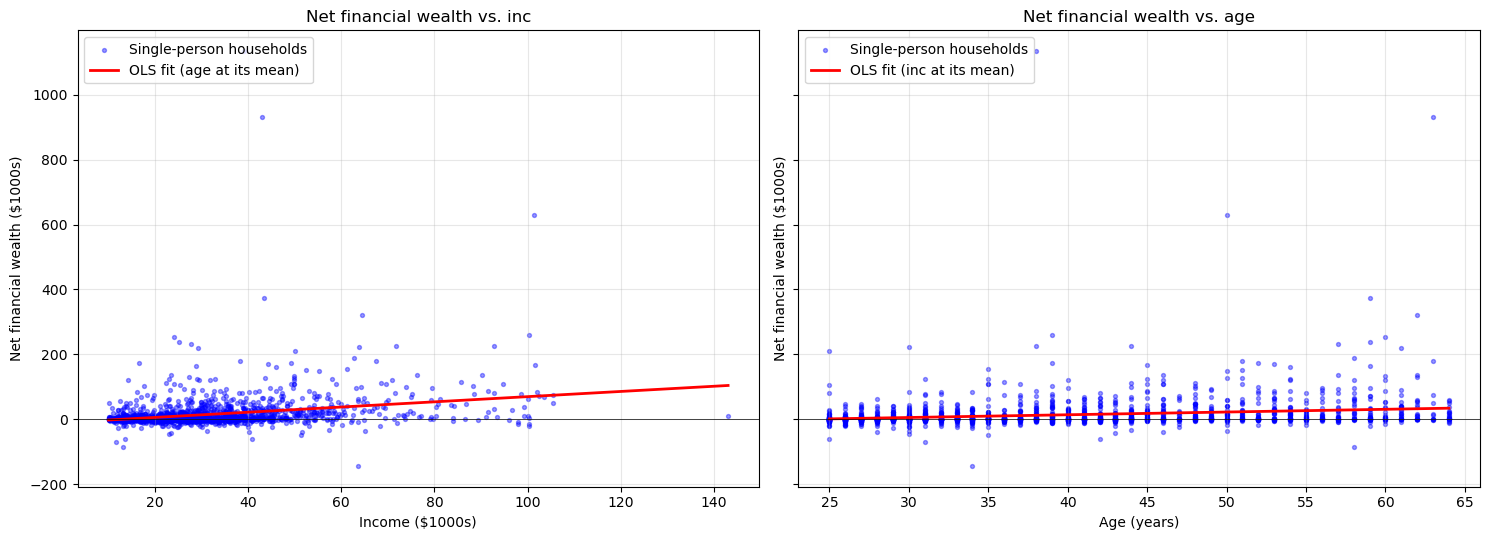

                       mean     median    std
inc                                          
(10.007, 16.564]   2.820000   0.020000  15.92
(16.564, 22.082]   3.110000   0.300000  11.65
(22.082, 28.754]   9.390000   1.220000  29.09
(28.754, 39.14]   16.430000   3.500000  62.25
(39.14, 143.067]  36.200001  18.120001  73.94
           mean  median    std
age                           
(24, 34]   4.26    0.42  18.54
(34, 44]  13.83    1.60  55.56
(44, 54]  23.17    5.45  48.63
(54, 64]  31.41    6.90  78.37


In [26]:
# Visual check: wealth against income and age, with the fitted partial effect of each regressor (other one at its mean)
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5), sharey=True)
for ax, var, other in zip(axes, ['inc', 'age'], ['age', 'inc']):
    grid = np.linspace(single[var].min(), single[var].max(), 100)
    fit = model_c.predict(pd.DataFrame({var: grid, other: single[other].mean()}))
    ax.scatter(single[var], single['nettfa'], s=8, alpha=0.4, color='blue', label='Single-person households')
    ax.plot(grid, fit, color='red', lw=2, label=f'OLS fit ({other} at its mean)')
    ax.axhline(0, color='black', lw=0.5)
    ax.set_xlabel('Income ($1000s)' if var == 'inc' else 'Age (years)')
    ax.set_ylabel('Net financial wealth ($1000s)')
    ax.set_title(f'Net financial wealth vs. {var}')
    ax.legend(loc='upper left')
    ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Mean and median wealth by income quintile and by age group
print(single.groupby(pd.qcut(single['inc'], 5), observed=True)['nettfa'].agg(['mean', 'median', 'std']).round(2))
print(single.groupby(pd.cut(single['age'], [24, 34, 44, 54, 64]), observed=True)['nettfa'].agg(['mean', 'median', 'std']).round(2))

**Both coefficients are positive and highly statistically significant. Holding age fixed, \$1,000 more annual income is associated with \$799 more net financial wealth ($\hat\beta_1 = 0.799$, $t = 13.4$). Holding income fixed, each additional year of age is associated with \$843 more net financial wealth ($\hat\beta_2 = 0.843$, $t = 9.2$). Both effects remain clearly significant with heteroskedasticity-robust standard errors ($t = 7.9$ and $7.1$). They are economically large compared with the wealth of the typical single, but they describe the *average* single and are strongly influenced by a few very wealthy households.**

$$\widehat{\text{nettfa}} = \underset{(4.080)}{-43.040} + \underset{(0.060)}{0.799}\,\text{inc} + \underset{(0.092)}{0.843}\,\text{age}, \qquad n = 2{,}017, \quad R^2 = 0.119$$

| | Coefficient | Std. error | $t$ | $p$-value | 95% CI | White $t$ |
|---|---|---|---|---|---|---|
| inc | 0.799 | 0.060 | 13.38 | < 0.001 | [0.682, 0.916] | 7.93 |
| age | 0.843 | 0.092 | 9.16 | < 0.001 | [0.662, 1.023] | 7.06 |

**1. Interpretation of the income coefficient.** Each coefficient is a *partial* (ceteris paribus) effect: it compares singles who differ in one regressor while the other is held fixed. Among singles of the same age, one with \$1,000 more annual income has, on average, \$799 more net financial wealth.
- *Stock versus flow.* Wealth is a *stock* accumulated over many years, while income is an annual *flow*. A coefficient of 0.8 therefore does not mean that 80% of each extra dollar is saved. It reflects that higher income has usually been earned for many years. The average single in the sample is 39 years old, so they have been in the workforce for roughly 14 years since age 25 (the youngest age in the sample). Spread over 14 years, \$0.80 of wealth per \$1 of income corresponds to saving only about 5–6 cents of each extra dollar of income per year, ignoring investment returns. This is a plausible marginal saving rate in financial assets.
- *Economic magnitude.* A one-standard-deviation increase in income (\$16,670) is associated with \$13,300 more wealth. This is about as large as the average wealth of singles (\$13,595) and almost ten times the median (\$1,400). Income is therefore an economically very important predictor of wealth. The grouped data confirm this: mean wealth rises from \$2,820 in the lowest income quintile to \$36,200 in the highest, and median wealth from \$20 to \$18,120.

**2. Interpretation of the age coefficient.** Among singles with the same income, someone one year older has, on average, \$843 more net financial wealth. Between the youngest (25) and the oldest (64) singles in the sample, a 39-year difference, this adds up to about $39 \times 0.843 \approx$ \$32,900. A one-standard-deviation difference in age (10.8 years) corresponds to about \$9,100 more wealth.
- *Life-cycle hypothesis.* This is exactly what the life-cycle model of saving (Modigliani & Brumberg, 1954) predicts. People save during their working lives to finance consumption in retirement, so wealth rises with age until retirement and declines afterwards. The sample contains only people aged 25 to 64, so we observe only the *accumulation phase* of the life cycle, and a positive slope is expected. In addition, older people have had more years for their savings to earn returns, so compound interest contributes to the age effect. Retirement saving is also increasingly urgent as people approach retirement.
- *Magnitude comparison.* One additional year of age is associated with about the same increase in wealth as \$1,000 of additional annual income. The two effects are of a similar order of magnitude per unit, but income varies more across singles, so it explains more of the variation in wealth.
- Mean wealth by age group rises from \$4,260 (25–34) to \$13,830 (35–44), \$23,170 (45–54) and \$31,410 (55–64), roughly in line with the linear slope.

**3. Statistical significance.** Both $t$-statistics are far above the 5% critical value of 1.96 ($p < 0.001$). The 95% confidence intervals [0.68, 0.92] for income and [0.66, 1.02] for age exclude zero by a wide margin. The $F$-statistic for the joint significance of both regressors is 136.5 ($p \approx 10^{-56}$). With more than 2,000 observations, there is no doubt that wealth is related to both income and age.

**4. Caveats on the inference.** The *statistical* significance holds up, but the size of the effects should be interpreted carefully:
- *Heteroskedasticity.* The scatterplots show a clear fan shape: the dispersion of wealth increases strongly with income (the standard deviation of wealth rises from \$15,900 in the lowest income quintile to \$73,900 in the highest). The classical standard errors assume constant error variance and are too small. White standard errors are about 70% larger for income (0.101 vs. 0.060), and the $t$-statistic falls from 13.4 to 7.9. Both coefficients remain highly significant, so the conclusions do not change, but the robust standard errors are the appropriate ones here. (We return to this in (k).)
- *Non-normal errors.* The residuals are extremely skewed (skewness 13.4) and fat-tailed (excess kurtosis about 282), because of a few singles with very high wealth (up to \$1.13 million). Exact $t$-tests require normal errors, but with $n = 2{,}017$ the OLS estimators are approximately normal by the Central Limit Theorem, so the $t$-tests remain valid asymptotically.
- *Influence of the wealthiest singles.* Because OLS minimizes squared residuals, the coefficients are dominated by the richest households. A median regression, which describes the *typical* single instead of the average, gives much smaller effects: 0.36 for income and 0.14 for age. Excluding the top and bottom 1% of wealth reduces the OLS coefficients to 0.58 and 0.57. The effects for the typical single are therefore considerably smaller than the OLS estimates suggest. Most of the large average effect comes from the upper part of the distribution, where high income and high age go along with *very* high wealth.
- *Low explanatory power.* The $R^2$ of 0.119 means that income and age explain only 12% of the variation in wealth among singles. The residual standard deviation (\$44,700) is more than three times the mean wealth. Financial wealth depends on many other factors, such as education, inheritances, financial literacy, risk preferences, health, and access to employer pension plans.

**5. Correlation, not causation.** The coefficients describe conditional associations in a cross-section and should not be read as causal effects:
- *Omitted variables.* Education, financial literacy and patience are positively related both to income and to saving behaviour. The income coefficient therefore partly reflects that higher earners are, for example, better educated and more likely to have access to a 401(k). It is not the pure effect of an exogenous increase in income.
- *Age versus cohort.* In a single cross-section, differences between age groups mix the effect of *age* with the effect of *birth cohort*. The 60-year-olds in the sample grew up and started working in a different economic environment than the 25-year-olds. Disentangling the two would require following the same people over time (panel data).
- *Interaction with income.* Fortunately, income and age are almost uncorrelated among singles ($\rho = 0.039$), so the two partial effects are hardly affected by each other. Regressing wealth on income alone gives practically the same income coefficient, which we examine in (g).

# 2 (d)

In [27]:
# The intercept is the prediction at inc = 0 and age = 0 -- compare with the region actually covered by the data
print(f"Smallest income in the sample: {single['inc'].min():.2f}k; smallest age: {single['age'].min()}")
young_low = single[(single['age'] < 30) & (single['inc'] < 15)]
print(f'Young (<30), low-income (<15k) singles: n = {len(young_low)}, '
      f'actual mean nettfa = {young_low.nettfa.mean():.2f}, median = {young_low.nettfa.median():.2f}, '
      f'mean predicted nettfa = {model_c.predict(young_low).mean():.2f}')
print(f"Share of negative fitted values: {(model_c.fittedvalues < 0).mean():.1%}; "
      f"share of negative observed wealth: {(single['nettfa'] < 0).mean():.1%}\n")

# Re-centring the regressors changes only the intercept, and gives it a meaningful interpretation
centred = smf.ols('nettfa ~ I(inc - inc.mean()) + I(age - age.mean())', data=single).fit()
at_min = smf.ols('nettfa ~ I(inc - 10) + I(age - 25)', data=single).fit()
pd.DataFrame({'Original (inc = 0, age = 0)': model_c.params.values,
              'Centred at the means': centred.params.values,
              'Centred at inc = 10, age = 25': at_min.params.values},
             index=['Intercept', 'inc', 'age']).round(3)

Smallest income in the sample: 10.01k; smallest age: 25
Young (<30), low-income (<15k) singles: n = 77, actual mean nettfa = -0.24, median = 0.00, mean predicted nettfa = -10.26
Share of negative fitted values: 21.2%; share of negative observed wealth: 26.0%



,"Original (inc = 0, age = 0)",Centred at the means,"Centred at inc = 10, age = 25"
Intercept,-43.040,13.595,-13.980
inc,0.799,0.799,0.799
age,0.843,0.843,0.843


**No, not in its literal form. The intercept of $-43.04$ is the predicted net financial wealth of a single with zero income and an age of zero, i.e. $-\$43,040$ for a newborn with no income. Nobody like this exists in the data (the minimum income is \$10,000 and the minimum age is 25), so the intercept is an extrapolation far outside the observed data and has no economic meaning by itself. Its role is statistical: it positions the regression plane so that the slopes can be estimated correctly. The intercept becomes meaningful only if the regressors are re-centred at a value that actually occurs in the data, for example at their means, where the intercept equals the average wealth of singles (\$13,595).**

**1. Why the literal interpretation fails.** By definition, the intercept is the predicted value when all regressors are zero:
$$\widehat{\text{nettfa}}\,(\text{inc} = 0, \text{age} = 0) = \hat\beta_0 = -43.04$$
- *Age zero is impossible.* The survey covers adults aged 25–64. Even if we set income to zero, a prediction at age 0 extrapolates 25 years beyond the youngest person in the sample.
- *Zero income is outside the sample.* The lowest income among singles is \$10,000. The model has never "seen" a person with zero income, and there is no reason why the linear relationship estimated for incomes between \$10,000 and \$143,000 should hold far below that range.
- *Linear models extrapolate poorly.* Within the data, the linear fit is an approximation. Far outside the data, nothing guarantees that the approximation still holds. In this case, the true relationship is clearly non-linear at the bottom of the distribution, as shown below.

**2. Even at the edge of the data, the intercept region is badly fitted.** At the smallest income and age actually observed (inc = 10, age = 25), the model predicts $-43.04 + 0.799 \times 10 + 0.843 \times 25 = -\$13,980$. In the data, the 77 singles younger than 30 with incomes below \$15,000 have a mean wealth of $-\$243$ and a median of exactly zero, whereas the model predicts an average of $-\$10,260$ for them. The model is therefore off by about \$10,000 for exactly those households that are closest to the "intercept region". The reason is that wealth is roughly *flat* near zero for low incomes (mean wealth of \$2,820 and \$3,110 in the two lowest income quintiles) and rises steeply only at higher incomes. A straight line fitted through this convex pattern has to be steep to capture the high-income singles and therefore passes far below zero at the low end. About 21% of the fitted values are negative, partly as an artefact of this misfit. This non-linearity is an important reason to add $\text{inc}^2$ to the model, as in equation (2) of part (h).

**3. A negative intercept is not absurd per se.** Net financial wealth *can* be negative, since it subtracts consumer debt (credit cards, car loans, student loans) from financial assets and excludes housing. In fact, 26% of the singles in the sample have negative net financial wealth. A young person with low income and some debt could plausibly have negative wealth. The problem with the intercept is therefore not its *sign* but the fact that it describes a combination of characteristics (age 0, income 0) that is impossible or unobserved.

**4. Statistical significance does not create meaning.** The intercept is highly significant ($t = -10.55$, $p < 0.001$). This only says that the regression plane, extended to the point (0, 0), passes clearly below zero. It is a precise estimate of a meaningless quantity. Significance and economic interpretability are different things.

**5. What the intercept does do: it anchors the regression.** Even if it is not interpretable, the intercept is essential.
- *The fitted plane passes through the means.* With an intercept, OLS ensures that the residuals have mean zero and that $\bar y = \hat\beta_0 + \hat\beta_1 \bar x_1 + \hat\beta_2 \bar x_2$. The intercept absorbs the average level of wealth that the slopes do not explain.
- *Omitting it would bias the slopes.* Forcing the plane through the origin (nettfa = 0 at inc = 0, age = 0) would impose a restriction that is clearly not supported by the data. This would distort the slope estimates, and the usual $R^2$ would no longer be meaningful. The intercept should therefore always be included, even when its value cannot be interpreted.

**6. Making the intercept meaningful by re-centring.** The intercept depends on where the zero point of each regressor lies. Subtracting a constant from a regressor leaves the slope unchanged and shifts only the intercept, as the table above shows:

| Specification | Intercept | Meaning of the intercept | inc | age |
|---|---|---|---|---|
| Original | $-43.04$ | Wealth at inc = 0, age = 0 (not observed) | 0.799 | 0.843 |
| Centred at the means | 13.59 | Predicted wealth of the *average* single (inc = \$29,446, age = 39.3), equal to mean wealth | 0.799 | 0.843 |
| Centred at inc = 10, age = 25 | $-13.98$ | Predicted wealth of the youngest, lowest-income single | 0.799 | 0.843 |

In the centred version, the intercept of 13.59 is exactly the sample mean of `nettfa`. This follows from the property that the regression passes through the means. It is now a directly interpretable number: the expected net financial wealth of a single with average income and average age. The choice of reference point is a matter of interpretation and does not affect the fit, the slopes or their standard errors.

# 2 (e)

In [28]:
# t-test of H0: beta_age = 1 against the one-sided alternative H1: beta_age < 1 (rejection region in the left tail)
b_age, se_age = model_c.params['age'], model_c.bse['age']
df_res = model_c.df_resid
t_e = (b_age - 1) / se_age
p_e = stats.t.cdf(t_e, df_res)                                    # one-sided (left-tail) p-value
print(f'beta_age = {b_age:.4f}, se = {se_age:.4f}, t = {t_e:.3f}')
print(f'Critical value (5%, one-sided, {df_res:.0f} df) = {stats.t.ppf(0.05, df_res):.3f}, p-value = {p_e:.4f}, reject H0: {p_e < 0.05}')

# Same test with White (heteroskedasticity-robust) standard errors from (c)
se_w = robust_c.bse['age']
t_w = (b_age - 1) / se_w
print(f'\nWhite: se = {se_w:.4f}, t = {t_w:.3f}, p-value = {stats.t.cdf(t_w, df_res):.4f}, reject H0: {stats.t.cdf(t_w, df_res) < 0.05}')

# What does beta_age = 1 mean relative to the income of singles? ($1,000 per year as a share of mean income)
print(f"\n$1,000 per year = {1 / single['inc'].mean():.1%} of mean single income; "
      f"estimated {b_age * 1000:.0f} $ per year = {b_age / single['inc'].mean():.1%}")

beta_age = 0.8427, se = 0.0920, t = -1.710
Critical value (5%, one-sided, 2014 df) = -1.646, p-value = 0.0437, reject H0: True

White: se = 0.1194, t = -1.318, p-value = 0.0938, reject H0: False

$1,000 per year = 3.4% of mean single income; estimated 843 $ per year = 2.9%


**The $t$-statistic is $t = (0.8427 - 1)/0.0920 = -1.71$, and the one-sided $p$-value is 0.0437. Since $p < 0.05$, or equivalently $t = -1.71 < -1.646$, we reject $H_0: \beta_2 = 1$ in favour of $H_1: \beta_2 < 1$ at the 5% level, but only narrowly. The result is fragile: with heteroskedasticity-robust standard errors, which (c) showed to be appropriate here, $t = -1.32$ and $p = 0.094$, so we can no longer reject. Economically, the test asks whether singles' financial wealth rises by less than \$1,000 per year of age. The value of 1 has no special theoretical meaning, however, and the estimated shortfall of about \$157 per year is economically small.**

**1. The test.** We test a value other than zero, so the $t$-statistic subtracts the hypothesized value:
$$H_0: \beta_2 = 1 \quad \text{vs.} \quad H_1: \beta_2 < 1, \qquad t = \frac{\hat\beta_2 - 1}{\text{se}(\hat\beta_2)} = \frac{0.8427 - 1}{0.0920} = -1.710 \;\sim\; t_{2014} \text{ under } H_0$$
Since the alternative points only to *smaller* values, the entire 5% rejection region lies in the left tail. We reject if $t < t_{0.05,\,2014} = -1.646$. The $p$-value is the probability, under $H_0$, of a $t$-statistic at least as far into the left tail as the one observed:
$$p = P(T_{2014} < -1.710) = 0.0437$$

| Standard errors | se($\hat\beta_2$) | $t$ | One-sided $p$ | Reject at 5%? |
|---|---|---|---|---|
| Classical (as in (c)) | 0.0920 | $-1.71$ | 0.044 | Yes (narrowly) |
| White (robust) | 0.1194 | $-1.32$ | 0.094 | No |

**2. Is the rejection convincing?** Only to a limited extent, for three reasons:
- *It is borderline.* A $p$-value of 0.044 is just below the 5% threshold. At the 1% level (critical value $-2.33$), we would not reject. Evidence this close to the threshold is weak.
- *It depends on the standard errors.* As shown in (c), the variance of wealth increases strongly with income, so the classical standard errors are too small. With White standard errors, the standard error of $\hat\beta_2$ rises by 30%, the $t$-statistic drops to $-1.32$, and the $p$-value of 0.094 is no longer significant. Since heteroskedasticity is clearly present, the robust test is the more credible one. Our preferred conclusion is therefore that **the data do not provide robust evidence that $\beta_2 < 1$**.
- *It depends on the conditional mean.* The median regression from (c) gives an age effect of only 0.14 (95% CI [0.11, 0.18]), which is far below 1. For the *typical* single, wealth rises by much less than \$1,000 per year of age. The OLS coefficient of 0.84 is pulled up by a small number of older, very wealthy singles. Whether "$\beta_2 < 1$" is true therefore also depends on whether we ask about the average or the typical single.

**3. Does the test have an interesting economic interpretation?** Under $H_0$, each additional year of age, holding income fixed, is associated with \$1,000 more net financial wealth. Under $H_1$, the age–wealth gradient is smaller than that. Three points matter for the interpretation:
- *The value 1 is a round number, not a theoretical prediction.* Unlike $\beta = 1$ in the CAPM (an average stock) or a unit elasticity, no economic theory predicts that wealth rises by exactly \$1,000 per year. Without a benchmark, the test is mainly a statistical exercise. We can, however, give the number some content. \$1,000 per year corresponds to about 3.4% of the average single's income (\$29,446). $H_0$ can therefore be read as "singles build up financial wealth, including investment returns, at a pace corresponding to 3.4% of average income per year". The point estimate of \$843 corresponds to 2.9%. The one-sided alternative then asks whether singles accumulate *less* than such a benchmark, which is related to the policy debate on whether households save enough for retirement. The one-sided form makes sense if we are interested only in a shortfall, e.g. because we want to know whether a savings target is missed.
- *The economic difference is small.* Even taking the point estimate at face value, the shortfall relative to \$1,000 is \$157 per year of age. Over the entire age range of the sample (25 to 64), this adds up to about \$6,100. This is not negligible, but it is small compared with the enormous dispersion of wealth (residual standard deviation of \$44,700). Even if the difference is statistically significant, it is economically modest.
- *The age coefficient is not an individual saving rate.* In a cross-section, $\beta_2$ compares older and younger singles at one point in time. It is *not* the amount by which a given person's wealth grows each year. The difference also contains cohort effects: older cohorts experienced different returns, inflation and pension systems, and some had already started saving before the existence of 401(k) plans. The age gradient may also be affected by differential mortality, since wealthier people live longer. Interpreting the test as "people save less than \$1,000 per year" would therefore over-interpret what a cross-section can show.

# 2 (f)

In [29]:
# Same t-statistic, now against the two-sided alternative H1: beta_age != 1 (2.5% in each tail)
p_f = 2 * stats.t.sf(abs(t_e), df_res)
print(f't = {t_e:.3f}, critical values (5%, two-sided) = ±{stats.t.ppf(0.975, df_res):.3f}, p-value = {p_f:.4f}, reject H0: {p_f < 0.05}')
print(f'White: t = {t_w:.3f}, two-sided p-value = {2 * stats.t.sf(abs(t_w), df_res):.4f}')

# Cross-check with statsmodels and link to the confidence intervals (a 95% CI contains all values not rejected two-sided at 5%)
print(model_c.t_test('age = 1'))
print('95% CI for beta_age:', model_c.conf_int(0.05).loc['age'].round(4).values,
      '| 90% CI:', model_c.conf_int(0.10).loc['age'].round(4).values)

t = -1.710, critical values (5%, two-sided) = ±1.961, p-value = 0.0874, reject H0: False
White: t = -1.318, two-sided p-value = 0.1876
                             Test for Constraints                             
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
c0             0.8427      0.092     -1.710      0.087       0.662       1.023
95% CI for beta_age: [0.6622 1.0231] | 90% CI: [0.6912 0.9941]


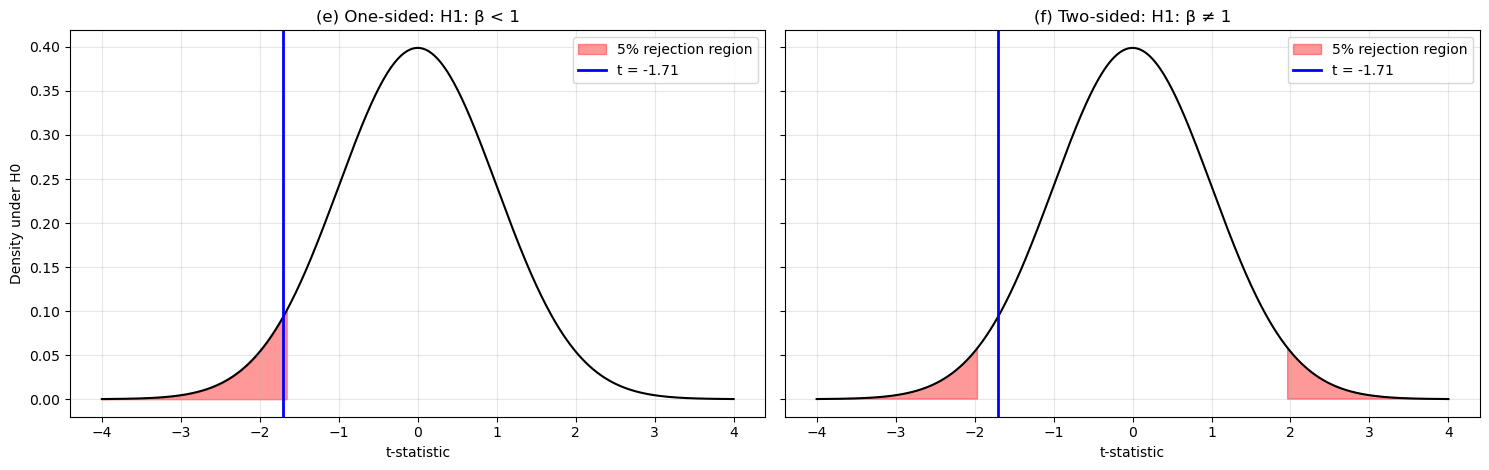

In [30]:
# Visual comparison of the one-sided (e) and two-sided (f) rejection regions for the same t-statistic
x = np.linspace(-4, 4, 500)
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8), sharey=True)
for ax, (title, lo, hi) in zip(axes, [('(e) One-sided: H1: β < 1', stats.t.ppf(0.05, df_res), np.inf),
                                     ('(f) Two-sided: H1: β ≠ 1', -stats.t.ppf(0.975, df_res), stats.t.ppf(0.975, df_res))]):
    ax.plot(x, stats.t.pdf(x, df_res), color='black')
    ax.fill_between(x, stats.t.pdf(x, df_res), where=(x <= lo) | (x >= hi), color='red', alpha=0.4, label='5% rejection region')
    ax.axvline(t_e, color='blue', lw=2, label=f't = {t_e:.2f}')
    ax.set_title(title)
    ax.set_xlabel('t-statistic')
    ax.legend(loc='upper right')
    ax.grid(True, alpha=0.3)
axes[0].set_ylabel('Density under H0')
plt.tight_layout()
plt.show()

**Against the two-sided alternative $H_1: \beta_2 \neq 1$, we do *not* reject $H_0$ at the 5% level. The $t$-statistic is unchanged ($-1.71$), but the critical values are now $\pm 1.961$, and the two-sided $p$-value of 0.087 is twice the one-sided value. Equivalently, the 95% confidence interval [0.662, 1.023] contains 1. The data are therefore consistent with an age effect of \$1,000 per year, but also with any value between roughly \$660 and \$1,020. Exactly the same data and the same $t$-statistic thus lead to opposite conclusions in (e) and (f). This is not a contradiction: the two tests answer different questions.**

**1. The test.** With $H_1: \beta_2 \neq 1$, deviations in *both* directions count as evidence against $H_0$. The 5% rejection region is split into 2.5% in each tail:
$$\text{reject if } |t| > t_{0.975,\,2014} = 1.961, \qquad p = 2\,P(T_{2014} > |{-1.710}|) = 2 \times 0.0437 = 0.0874$$
Since $|t| = 1.71 < 1.961$ and $p = 0.087 > 0.05$, we do not reject $H_0$. The figure above shows why: the observed $t$-statistic lies inside the one-sided rejection region but outside the two-sided one.

**2. The link to confidence intervals.** A two-sided test at level $\alpha$ rejects exactly those values that lie outside the $(1-\alpha)$ confidence interval. The 95% interval [0.662, 1.023] contains 1, so $\beta_2 = 1$ is not rejected. The 90% interval [0.691, 0.994] *excludes* 1. This is no coincidence: a one-sided test at 5% uses the same critical value (1.646) as a two-sided test at 10%. The result in (e) is therefore the same as saying that 1 lies just outside the 90% confidence interval. Overall:

| Alternative | Standard errors | $p$-value | Reject at 5%? |
|---|---|---|---|
| One-sided, $\beta_2 < 1$ | Classical | 0.044 | Yes |
| Two-sided, $\beta_2 \neq 1$ | Classical | 0.087 | No |
| One-sided, $\beta_2 < 1$ | White | 0.094 | No |
| Two-sided, $\beta_2 \neq 1$ | White | 0.188 | No |

Only one of the four combinations rejects at 5%. It is the one that uses the least appropriate standard errors and the most "favourable" alternative.

**3. Economic interpretation and comparison with (e).**
- *Different questions.* The two-sided test asks whether the age–wealth gradient is *different* from \$1,000 per year in either direction, i.e. whether \$1,000 per year is an acceptable description of the data. The answer is yes: the data cannot distinguish \$843 from \$1,000. The one-sided test in (e) asks a narrower question: is the gradient *smaller* than \$1,000? It ignores the possibility that it might be larger.
- *Why the one-sided test rejects more easily.* By concentrating the entire 5% of the rejection region in one tail, the one-sided test gains power against alternatives in that direction, at the cost of having no power at all against alternatives in the other direction. If $\hat\beta_2$ had been, say, 1.2, the one-sided test in (e) would never reject, no matter how precise the estimate.
- *When is each appropriate?* The choice of alternative must be made *before* looking at the data, based on the economic question. If the research question is whether singles fall short of a savings benchmark (only a shortfall matters, e.g. for retirement adequacy), the one-sided test is justified. If the question is whether \$1,000 per year is a good description of the age profile of wealth, the two-sided test is appropriate. Here, nothing in economic theory rules out $\beta_2 > 1$ (wealth could easily grow by more than \$1,000 per year through compound returns), so the two-sided test is the more natural default.
- *The danger of choosing after seeing the data.* Choosing a one-sided test *because* the estimate turned out below 1 effectively doubles the true probability of a false rejection, from 5% to 10%. This is a form of $p$-hacking, and it is the reason why the two-sided test is the standard in empirical work unless there is a strong a priori reason for a one-sided hypothesis.

**4. "Not rejecting" is not "accepting".** Not rejecting $H_0$ does not mean that the age effect *is* \$1,000 per year. It means that the data are not precise enough to rule it out. The 95% confidence interval spans about \$360 of annual wealth accumulation, which is wide relative to the point estimate. Many values, including 0.7, 0.85 and 1.0, are all consistent with the data. The correct summary of (e) and (f) is therefore that **the estimated age effect is somewhat below \$1,000 per year, but the evidence that it really is below \$1,000 is weak and not robust**. It depends on the choice of the alternative, the treatment of heteroskedasticity and the focus on the conditional mean rather than the median.

# 2 (g)

In [31]:
# Simple regression of nettfa on income only (singles), omitting age
model_g = smf.ols('nettfa ~ inc', data=single).fit()
print(model_g.summary().tables[1])
print(f'R² = {model_g.rsquared:.4f} (with age in (c): {model_c.rsquared:.4f})\n')

# Omitted variable bias: beta_inc(simple) = beta_inc(multiple) + beta_age * delta,
# where delta is the slope from the auxiliary regression of the omitted variable (age) on the included one (inc)
delta = smf.ols('age ~ inc', data=single).fit().params['inc']
print(pd.Series({'beta_inc, multiple regression (c)': model_c.params['inc'],
                 'beta_inc, simple regression (g)': model_g.params['inc'],
                 'Difference (g) - (c)': model_g.params['inc'] - model_c.params['inc'],
                 'delta (slope of age on inc)': delta,
                 'beta_age * delta (OVB formula)': model_c.params['age'] * delta,
                 'Corr(inc, age)': single['inc'].corr(single['age']),
                 'se(beta_inc): (c)': model_c.bse['inc'],
                 'se(beta_inc): (g)': model_g.bse['inc'],
                 'Residual sd: (c)': np.sqrt(model_c.scale),
                 'Residual sd: (g)': np.sqrt(model_g.scale),
                 'Variance inflation factor': 1 / (1 - single['inc'].corr(single['age'])**2)}).round(4))

# The reverse case: omitting income from the regression changes the age coefficient by beta_inc * delta_2
delta2 = smf.ols('inc ~ age', data=single).fit().params['age']
print(f"\nAge coefficient: with income {model_c.params['age']:.4f}, without income "
      f"{smf.ols('nettfa ~ age', data=single).fit().params['age']:.4f}, delta_2 = {delta2:.4f}, OVB = {model_c.params['inc'] * delta2:.4f}")

# Why is the correlation so small? Mean income by age group (hump-shaped age-earnings profile)
print('\nMean income ($1000s) by age group:')
print(single.groupby(pd.cut(single['age'], [24, 34, 44, 54, 64]), observed=True)['inc'].mean().round(2))

                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept    -10.5710      2.061     -5.130      0.000     -14.612      -6.530
inc            0.8207      0.061     13.476      0.000       0.701       0.940
R² = 0.0827 (with age in (c): 0.1193)

beta_inc, multiple regression (c)     0.7993
beta_inc, simple regression (g)       0.8207
Difference (g) - (c)                  0.0214
delta (slope of age on inc)           0.0254
beta_age * delta (OVB formula)        0.0214
Corr(inc, age)                        0.0391
se(beta_inc): (c)                     0.0597
se(beta_inc): (g)                     0.0609
Residual sd: (c)                     44.6828
Residual sd: (g)                     45.5922
Variance inflation factor             1.0015
dtype: float64

Age coefficient: with income 0.8427, without income 0.8908, delta_2 = 0.0602, OVB = 0.0481

Mean income ($1000s) by age group:
age
(24

In [32]:
# For comparison: the same exercise in the full sample, where income and age are more strongly correlated
full_c = smf.ols('nettfa ~ inc + age', data=pension).fit()
full_g = smf.ols('nettfa ~ inc', data=pension).fit()
delta_full = smf.ols('age ~ inc', data=pension).fit().params['inc']
print(f"Full sample: corr(inc, age) = {pension['inc'].corr(pension['age']):.3f}, beta_inc with age = {full_c.params['inc']:.4f}, "
      f"without age = {full_g.params['inc']:.4f}, OVB = beta_age * delta = {full_c.params['age'] * delta_full:.4f}")

Full sample: corr(inc, age) = 0.106, beta_inc with age = 0.9534, without age = 0.9999, OVB = beta_age * delta = 0.0466


**Without age, the income coefficient is 0.821 (standard error 0.061, $t = 13.5$), compared with 0.799 in (c). It is only 0.021 higher, a difference of about 2.7%, which is far smaller than its standard error. The difference is exactly the omitted variable bias: the effect of age on wealth (0.843) times the slope from a regression of age on income (0.025). It is positive because older singles have both slightly higher incomes and higher wealth, so in the simple regression income partly picks up the effect of age. It is small because income and age are almost uncorrelated among singles ($\rho = 0.039$).**

| | Multiple regression (c) | Simple regression (g) |
|---|---|---|
| $\hat\beta_{inc}$ | 0.7993 | 0.8207 |
| se($\hat\beta_{inc}$) | 0.0597 | 0.0609 |
| $\hat\beta_{age}$ | 0.8427 | (omitted) |
| $R^2$ | 0.119 | 0.083 |

**1. The omitted variable bias formula.** Let $\tilde\beta_1$ be the income coefficient of the simple regression and $\hat\beta_1, \hat\beta_2$ the coefficients of the multiple regression. Regressing the omitted variable on the included one, $\widehat{\text{age}} = \tilde\delta_0 + \tilde\delta_1\,\text{inc}$, gives the exact sample identity
$$\tilde\beta_1 = \hat\beta_1 + \hat\beta_2\,\tilde\delta_1$$
With $\tilde\delta_1 = 0.0254$:
$$\tilde\beta_1 = 0.7993 + 0.8427 \times 0.0254 = 0.7993 + 0.0214 = 0.8207 \;\checkmark$$
The decomposition is exact. The simple regression coefficient combines the *direct* association of income with wealth (0.799) with an *indirect* channel: singles with higher income are, on average, slightly older ($\tilde\delta_1 = 0.025$ years, about 9 days, per \$1,000 of income), and older singles are wealthier (\$843 per year of age). When age is left out, income is credited with this indirect effect as well.

**2. Sign of the bias.** The direction depends on two signs:

| | $\text{Corr}(\text{inc}, \text{age}) > 0$ | $\text{Corr}(\text{inc}, \text{age}) < 0$ |
|---|---|---|
| $\beta_{age} > 0$ | **Upward bias** (our case) | Downward bias |
| $\beta_{age} < 0$ | Downward bias | Upward bias |

Here, both $\hat\beta_2 > 0$ and $\tilde\delta_1 > 0$, so omitting age biases the income coefficient upwards.

**3. Size of the bias: why so small?** The bias is the *product* of two terms, so it is small whenever either term is small. The effect of age on wealth is not small, but the link between income and age among singles is very weak ($\rho = 0.039$). The reason is the *hump-shaped* age–earnings profile:

| Age | 25–34 | 35–44 | 45–54 | 55–64 |
|---|---|---|---|---|
| Mean income | \$27,520 | \$31,630 | \$32,620 | \$26,530 |

Income rises with age at first (work experience, careers) but falls again for the oldest group. This decline may reflect early retirement, part-time work, health problems and cohort differences (older cohorts are on average less educated). A linear correlation captures little of such a hump, so the two regressors are almost orthogonal. When regressors are uncorrelated, adding or removing one hardly changes the coefficient on the other. In the extreme case of zero correlation, the simple and multiple regression coefficients would be identical.

The same logic applies in the other direction. Omitting income from the regression changes the age coefficient from 0.843 to 0.891 (bias $= 0.799 \times 0.060 = 0.048$). This bias is more than twice as large, even though the correlation is the same. The auxiliary slope depends on the ratio of standard deviations, $\tilde\delta = \rho \cdot \sigma_{\text{dependent}}/\sigma_{\text{regressor}}$. Income (sd 16.7) varies more in its units than age (sd 10.8), so one year of age is associated with \$60 more income ($\tilde\delta_2 = 0.060$), while \$1,000 of income is associated with only 0.025 more years of age.

**4. Comparison with the full sample.** The bias can be much larger when the correlation is stronger. In the full sample (all household sizes), income and age are more strongly correlated (0.106), and omitting age raises the income coefficient from 0.953 to 1.000, a bias of 0.047, more than twice as large as among singles. Among singles, the two variables happen to be almost orthogonal, so the choice of specification makes little difference.

**5. Other consequences of omitting age.**
- *Fit.* The $R^2$ falls from 0.119 to 0.083. Age explains about 3.7 percentage points of the variation in wealth beyond income.
- *Precision.* The standard error of the income coefficient rises only slightly, from 0.0597 to 0.0609. Two effects offset each other. Omitting age increases the residual variance (the residual standard deviation rises from 44.68 to 45.59), which *raises* the standard error. At the same time, omitting a correlated regressor would normally *lower* it by removing multicollinearity. Since the correlation is almost zero (variance inflation factor of 1.0015), only the first effect matters.

**6. Which estimate is "right"?** It depends on the question:
- The coefficient from (c), 0.799, is the *partial* effect: how wealth differs between singles with different incomes *but the same age*. This is the relevant number if we want to isolate the role of income, for example when comparing two people of the same age.
- The coefficient from (g), 0.821, is the *total* association: how wealth differs between singles with different incomes, letting age vary as it naturally does with income in the population. This is the relevant number for pure prediction from income alone.
- For a ceteris paribus interpretation, (c) is preferable. Age is a valid control variable. It is determined at birth and cannot be caused by income, so controlling for it does not introduce a "bad control" problem.

The Frisch–Waugh–Lovell theorem gives another way to see this. The coefficient in (c) equals the slope from regressing wealth on the part of income that is *not* explained by age. Since age explains almost none of the variation in income, this "purged" income is nearly identical to income itself, and the two coefficients almost coincide.

**7. The broader lesson.** The OVB formula applies to every variable left out of the model, not just age. The regression in (c) omits, for example, education, financial literacy and inheritances. These are likely to be positively correlated with both income and wealth, so by the same formula the income coefficient in (c) is probably biased *upwards* as an estimate of the causal effect of income. Age happens to be a harmless omission here because it is nearly uncorrelated with income. Education would not be. Small changes when *one* control is added are therefore no guarantee that the estimate is free of omitted variable bias.

# 2 (h)

In [33]:
# NOTE: age and fsize are stored as 8-bit integers (int8) in the Stata file. Squaring an int8 silently overflows
# (int8 only holds values up to 127), so age**2 would be wrong. We therefore convert all variables to float first.
print('dtype of age in the file:', pension['age'].dtype)
print('Example of the overflow, ages 40, 50, 60 squared as int8:', (pd.Series([40, 50, 60], dtype='int8') ** 2).tolist())
full = pension.astype(float)
print('Check against the provided squares: max |age² - agesq| =', (full['age']**2 - full['agesq']).abs().max(),
      '| max |inc² - incsq| =', round((full['inc']**2 - full['incsq']).abs().max(), 4), '(float rounding)\n')

# OLS regression (2) on the full sample: nettfa = b0 + b1*inc + b2*age + b3*inc^2 + b4*age^2 + b5*fsize + u
formula_h = 'nettfa ~ inc + age + I(inc**2) + I(age**2) + fsize'
model_h = smf.ols(formula_h, data=full).fit()
robust_h = smf.ols(formula_h, data=full).fit(cov_type='HC1')     # White standard errors, used as a robustness check
print(model_h.summary())

dtype of age in the file: int8
Example of the overflow, ages 40, 50, 60 squared as int8: [64, -60, 16]
Check against the provided squares: max |age² - agesq| = 0.0 | max |inc² - incsq| = 0.0016 (float rounding)

                            OLS Regression Results                            
Dep. Variable:                 nettfa   R-squared:                       0.199
Model:                            OLS   Adj. R-squared:                  0.199
Method:                 Least Squares   F-statistic:                     460.4
Date:                Sun, 08 Nov 2026   Prob (F-statistic):               0.00
Time:                        12:52:54   Log-Likelihood:                -50700.
No. Observations:                9275   AIC:                         1.014e+05
Df Residuals:                    9269   BIC:                         1.015e+05
Df Model:                           5                                         
Covariance Type:            nonrobust                                        

In [34]:
# Marginal effects: d nettfa / d inc = b1 + 2*b3*inc and d nettfa / d age = b2 + 2*b4*age; turning points where they equal zero
b = model_h.params
inc2, age2 = 'I(inc ** 2)', 'I(age ** 2)'
age_star = -b['age'] / (2 * b[age2])
inc_star = -b['inc'] / (2 * b[inc2])

# Standard error of the age turning point (delta method)
grad = np.array([-1 / (2 * b[age2]), b['age'] / (2 * b[age2]**2)])
se_star = np.sqrt(grad @ model_h.cov_params().loc[['age', age2], ['age', age2]].values @ grad)
print(f"Turning point income: {inc_star:.2f}k (sample minimum {full['inc'].min():.2f}k)")
print(f"Turning point age: {age_star:.2f} years (sample minimum {full['age'].min():.0f}), "
      f"se = {se_star:.2f}, 95% CI = [{age_star - 1.96 * se_star:.1f}, {age_star + 1.96 * se_star:.1f}]\n")

# Marginal effect of age (and its t-statistic) at different ages
ages = [25, 30, 35, 40, 45, 50, 55, 60, 64]
print(pd.DataFrame({'Marginal effect of age ($1000s per year)': [b['age'] + 2 * b[age2] * a for a in ages],
                    't-stat': [model_h.t_test(f'age + {2 * a} * {age2} = 0').tvalue.item() for a in ages]},
                   index=pd.Index(ages, name='Age')).round(3), '\n')

# Marginal effect of income at different points of the income distribution
inc_pts = pd.Series({'Min': full['inc'].min(), 'P10': full['inc'].quantile(0.1), 'Median': full['inc'].median(),
                     'Mean': full['inc'].mean(), 'P90': full['inc'].quantile(0.9), 'P99': full['inc'].quantile(0.99),
                     'Max': full['inc'].max()})
print(pd.DataFrame({'Income ($1000s)': inc_pts, 'Marginal effect of income': b['inc'] + 2 * b[inc2] * inc_pts}).round(3))

Turning point income: 6.67k (sample minimum 10.01k)
Turning point age: 23.85 years (sample minimum 25), se = 4.29, 95% CI = [15.4, 32.3]

     Marginal effect of age ($1000s per year)  t-stat
Age                                                  
25                                      0.061   0.285
30                                      0.325   2.027
35                                      0.588   5.378
40                                      0.852  12.450
45                                      1.116  18.122
50                                      1.380  14.315
55                                      1.643  11.293
60                                      1.907   9.602
64                                      2.118   8.744 

        Income ($1000s)  Marginal effect of income
Min              10.008                      0.063
P10              15.300                      0.164
Median           33.288                      0.505
Mean             39.255                      0.618
P90        

In [35]:
# Robustness: White t-statistics, and the model with a marriage dummy (family size partly proxies for being married)
marr_h = smf.ols(formula_h + ' + marr', data=full).fit()
print(pd.DataFrame({'Coef': model_h.params, 't (classical)': model_h.tvalues, 't (White)': robust_h.tvalues,
                    'Coef, with marr': marr_h.params, 't, with marr': marr_h.tvalues}).round(4), '\n')
print(f"Correlation inc vs inc²: {full['inc'].corr(full['inc']**2):.3f}, age vs age²: {full['age'].corr(full['age']**2):.3f}\n")

# Raw wealth, income and age by family size (6+ pooled)
print(full.groupby(full['fsize'].clip(upper=6)).agg(households=('nettfa', 'size'), mean_nettfa=('nettfa', 'mean'),
                                                     median_nettfa=('nettfa', 'median'), mean_inc=('inc', 'mean'),
                                                     mean_age=('age', 'mean'), married=('marr', 'mean')).round(2))

                Coef  t (classical)  t (White)  Coef, with marr  t, with marr
I(age ** 2)   0.0264         4.6663     3.8257           0.0284        4.9494
I(inc ** 2)   0.0095        16.2571     3.3147           0.0093       15.5642
Intercept    13.9926         1.4004     1.1363          16.3177        1.6226
age          -1.2580        -2.5579    -2.2815          -1.4278       -2.8618
fsize        -1.9792        -4.9344    -6.4512          -1.3976       -2.8285
inc          -0.1266        -1.7296    -0.4489          -0.0783       -1.0161
marr             NaN            NaN        NaN          -3.3401       -2.0150 

Correlation inc vs inc²: 0.940, age vs age²: 0.993

       households  mean_nettfa  median_nettfa  mean_inc  mean_age  married
fsize                                                                     
1.0          2017        13.59           1.40     29.45     39.28     0.02
2.0          2199        29.11           5.53     42.50     44.37     0.68
3.0          1829     

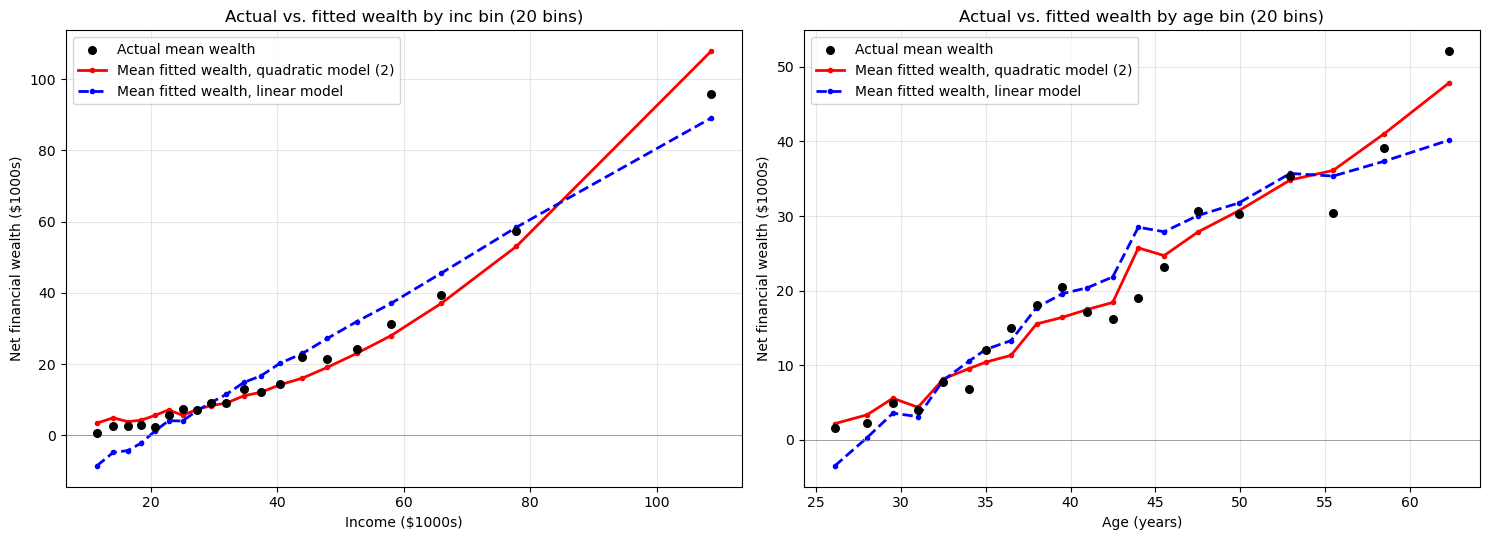

By age: {25: 2.97, 35: 6.21, 45: 14.74, 55: 28.53, 64: 45.46}
By income: {10: 0.8, 25: 3.88, 50: 18.51, 100: 83.35, 150: 195.63}


In [36]:
# Predicted wealth from the quadratic model vs. the linear model (other regressors at their means), with binned sample means
model_lin = smf.ols('nettfa ~ inc + age + fsize', data=full).fit()          # linear model, also the restricted model in (i)
means = full[['inc', 'age', 'fsize']].mean()
fit = full.assign(quad=model_h.fittedvalues, lin=model_lin.fittedvalues)
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
for ax, var in zip(axes, ['inc', 'age']):
    # Average actual and fitted wealth within 20 bins (5% of households each) of income or age
    bins = fit.groupby(pd.qcut(fit[var], 20, duplicates='drop'), observed=True)[[var, 'nettfa', 'quad', 'lin']].mean()
    ax.scatter(bins[var], bins['nettfa'], color='black', s=30, zorder=3, label='Actual mean wealth')
    ax.plot(bins[var], bins['quad'], color='red', lw=2, marker='o', ms=3, label='Mean fitted wealth, quadratic model (2)')
    ax.plot(bins[var], bins['lin'], color='blue', lw=2, ls='--', marker='o', ms=3, label='Mean fitted wealth, linear model')
    ax.axhline(0, color='grey', lw=0.5)
    ax.set_xlabel('Income ($1000s)' if var == 'inc' else 'Age (years)')
    ax.set_ylabel('Net financial wealth ($1000s)')
    ax.set_title(f'Actual vs. fitted wealth by {var} bin (20 bins)')
    ax.legend(loc='upper left')
    ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Predicted wealth at selected ages and incomes (other regressors at their means)
print('By age:', {a: round(model_h.predict(pd.DataFrame({'inc': [means['inc']], 'age': [a], 'fsize': [means['fsize']]})).iloc[0], 2) for a in [25, 35, 45, 55, 64]})
print('By income:', {i: round(model_h.predict(pd.DataFrame({'inc': [i], 'age': [means['age']], 'fsize': [means['fsize']]})).iloc[0], 2) for i in [10, 25, 50, 100, 150]})

**Both income and age have convex (U-shaped) effects on net financial wealth. The turning points are at an income of about \$6,700 and an age of about 23.8 years, both *below* the smallest values in the sample (\$10,000 and 25 years). Within the sample, wealth therefore rises with both income and age, and at an increasing rate. Age has a positive effect on wealth for everyone older than about 24, which means for every individual in the sample. The effect is, however, tiny and statistically insignificant for people in their mid-twenties, and grows to more than \$2,000 per additional year at age 64. Holding income and age fixed, each additional family member is associated with about \$1,980 less net financial wealth.**

$$\widehat{\text{nettfa}} = \underset{(9.99)}{13.99} - \underset{(0.073)}{0.1266}\,\text{inc} - \underset{(0.492)}{1.258}\,\text{age} + \underset{(0.00058)}{0.00949}\,\text{inc}^2 + \underset{(0.0057)}{0.0264}\,\text{age}^2 - \underset{(0.401)}{1.979}\,\text{fsize}, \qquad n = 9{,}275, \quad R^2 = 0.199$$

| | Coefficient | $t$ (classical) | $p$-value | $t$ (White) |
|---|---|---|---|---|
| Intercept | 13.99 | 1.40 | 0.161 | 1.14 |
| inc | $-0.1266$ | $-1.73$ | 0.084 | $-0.45$ |
| age | $-1.2580$ | $-2.56$ | 0.011 | $-2.28$ |
| inc² | 0.00949 | 16.26 | < 0.001 | 3.31 |
| age² | 0.02638 | 4.67 | < 0.001 | 3.83 |
| fsize | $-1.9792$ | $-4.93$ | < 0.001 | $-6.45$ |

**0. A data pitfall.** In the Stata file, `age` and `fsize` are stored as 8-bit integers, which can only hold values up to 127. Squaring them in Python does not raise an error but silently "wraps around" (e.g. $40^2$ becomes 64 and $50^2$ becomes $-60$). A regression with this corrupted age² gives completely different results (an age² coefficient of practically zero). We therefore convert the data to floating-point numbers first and verify that our squares match the `agesq` and `incsq` columns provided in the data set. This kind of silent error is a good reason to always check constructed variables.

**1. Why the individual coefficients cannot be read on their own.** With quadratic terms, the effect of a variable is no longer a single number but depends on the level of the variable itself:
$$\frac{\partial\,\widehat{\text{nettfa}}}{\partial\,\text{inc}} = \hat\beta_1 + 2\hat\beta_3\,\text{inc}, \qquad \frac{\partial\,\widehat{\text{nettfa}}}{\partial\,\text{age}} = \hat\beta_2 + 2\hat\beta_4\,\text{age}$$
The negative linear coefficients on income and age therefore do *not* mean that wealth falls with income or age. They only describe the slope at income zero and age zero, points far outside the data, just like the intercept in (d). For the same reason, the individual $t$-statistics of the linear and quadratic terms are not very informative. Each variable is highly correlated with its own square (0.94 for income, 0.993 for age), so the two coefficients are estimated with strongly correlated errors, and the relevant question is whether they are *jointly* significant (see (i)). This multicollinearity, together with the very different scales of the variables, is also what triggers the large condition number in the regression output. It does not bias the estimates.

**2. Income.** The coefficient on inc² is positive and highly significant, so the effect of income increases with income. The turning point is $-\hat\beta_1/(2\hat\beta_3) = 0.1266/(2 \times 0.00949) = 6.67$, i.e. \$6,670. Every household in the sample has a higher income (minimum \$10,000), so the effect of income on wealth is *positive for every household in the sample* and rises steadily:

| | Min | P10 | Median | Mean | P90 | P99 | Max |
|---|---|---|---|---|---|---|---|
| Income | \$10.0k | \$15.3k | \$33.3k | \$39.3k | \$70.9k | \$120.1k | \$199.0k |
| Effect of \$1,000 more income | \$63 | \$164 | \$505 | \$618 | \$1,218 | \$2,153 | \$3,651 |

At the median income, \$1,000 more annual income goes along with \$505 more wealth. At the 99th percentile, it is \$2,153. Predicted wealth (at the average age and family size) rises from about \$800 at an income of \$10,000 to \$18,500 at \$50,000, \$83,300 at \$100,000 and \$195,600 at \$150,000. Economically, this convexity has several plausible explanations:
- *The rich save a larger share of their income.* Households with higher (permanent) income have saving rates that rise with income (Dynan, Skinner & Zeldes, 2004). Low-income households need almost all of their income for consumption.
- *Access to saving vehicles.* Higher earners are more likely to have employer-sponsored pension plans such as 401(k)s and IRAs, and to invest in higher-yielding assets such as equities, so their wealth also grows faster through returns.
- *Social insurance.* Means-tested government programmes and Social Security, which replaces a larger share of income for low earners, reduce the need for low-income households to build up private financial wealth.

The linear model from (c) imposed the same income effect (about \$800–1,000) on everyone. The quadratic model shows that this average hides very different effects at the bottom and the top of the income distribution. The figure above compares actual and fitted average wealth within 20 income bins. The quadratic model tracks the actual averages much more closely. The linear model predicts *negative* average wealth for the lowest incomes (where actual averages are about \$1,000–3,000), overpredicts wealth for incomes between roughly \$35,000 and \$70,000, and underpredicts it in the top bin. The quadratic model fits better at both ends of the distribution.

**3. Age, and for whom it has a positive effect.** The coefficient on age² is positive, so the age profile of wealth is also convex. The marginal effect of age is positive if and only if
$$\hat\beta_2 + 2\hat\beta_4\,\text{age} > 0 \quad \Longleftrightarrow \quad \text{age} > -\frac{\hat\beta_2}{2\hat\beta_4} = \frac{1.258}{2 \times 0.02638} = 23.85 \text{ years}$$
**Age therefore has a positive effect on net wealth for everyone older than about 24, which includes every individual in the sample (aged 25–64).** The decreasing branch of the U-shape (below age 24) lies entirely outside the data and is an artefact of the quadratic functional form, so it should not be interpreted as "wealth falls with age for young people". The size and precision of the effect vary considerably with age:

| Age | 25 | 30 | 35 | 40 | 45 | 50 | 55 | 60 | 64 |
|---|---|---|---|---|---|---|---|---|---|
| Effect of one more year (\$) | 61 | 325 | 588 | 852 | 1,116 | 1,380 | 1,643 | 1,907 | 2,118 |
| $t$-statistic | 0.28 | 2.03 | 5.38 | 12.45 | 18.12 | 14.31 | 11.29 | 9.60 | 8.74 |

- *Statistically,* the effect is not significant for those aged 25–29. It becomes significant at the 5% level from about age 30. The turning point itself is estimated imprecisely: its delta-method 95% confidence interval is [15.4, 32.3] years. We cannot rule out that wealth is flat, or even slightly declining with age, for people in their twenties.
- *Economically,* wealth accumulation accelerates strongly over the working life. Holding income and family size at their means, predicted wealth rises from about \$3,000 at age 25 to \$6,200 at 35, \$14,700 at 45, \$28,500 at 55 and \$45,500 at 64. This acceleration is consistent with compound returns (wealth grows in proportion to the existing stock), with saving that intensifies as retirement approaches, and with expenses that fall later in life, as children leave home and mortgages are paid off.
- *Life-cycle perspective.* The life-cycle model predicts a *hump-shaped* wealth profile with a peak around retirement. Since the sample ends at age 64, we only observe the rising part. The convex shape within 25–64 is therefore consistent with the theory, but the quadratic would wrongly predict ever faster growth after retirement, when people actually start to draw down their wealth. As in (e), the cross-sectional age profile also mixes age with cohort effects.

**4. Family size.** Holding income and age fixed, each additional household member is associated with \$1,979 *less* net financial wealth ($t = -4.93$, and $-6.45$ with White standard errors, so the effect is highly significant). Economically, more members mean higher consumption needs (food, housing, childcare, education) for the same income, which leaves less to save. Larger families may also hold more of their wealth in housing, which is not included in net *financial* assets.

The raw data show why controlling for income and age matters. Mean wealth is *highest* for two-person households (\$29,110), not for singles (\$13,590). It then falls steadily, from \$19,170 (three persons) to \$7,880 (six or more persons). Two-person households are mostly couples, which often have two incomes and are older on average (44.4 years), so they are wealthier. Once income and age are held fixed, additional members reduce wealth. Since family size is closely linked to marital status, we also added a marriage dummy as a robustness check: the family-size coefficient shrinks to $-1.40$ but remains significant ($t = -2.83$). The linear specification assumes that each additional person reduces wealth by the same amount, whether it is the second or the sixth person. Dummies for each family size would relax this assumption.

**5. Caveats.** As for the singles in (c), wealth is extremely skewed (residual skewness 9.9), and the variance of wealth rises steeply with income. The White $t$-statistics are much smaller than the classical ones, especially for inc², where the $t$-statistic falls from 16.3 to 3.3. The strong convexity in income is largely driven by a small number of very wealthy, high-income households. The squared terms remain significant with robust standard errors, but the precise curvature should be taken with caution. All coefficients are associations in a cross-section, not causal effects.

# 2 (i)

In [37]:
# F-test of H0: beta3 = beta4 = 0 (no quadratic terms), comparing the unrestricted model (2) with the restricted linear model
q = 2                                                               # number of restrictions
F = ((model_lin.ssr - model_h.ssr) / q) / (model_h.ssr / model_h.df_resid)
print(f'SSR restricted = {model_lin.ssr:,.0f}, SSR unrestricted = {model_h.ssr:,.0f}, df = ({q}, {model_h.df_resid:.0f})')
print(f'F = {F:.2f}, p-value = {stats.f.sf(F, q, model_h.df_resid):.2e}, 5% critical value = {stats.f.ppf(0.95, q, model_h.df_resid):.3f}')

# Cross-checks: statsmodels' F-test, the same test with White standard errors, and the individual tests
print('\nstatsmodels:', model_h.f_test('I(inc ** 2) = 0, I(age ** 2) = 0'))
print('White (robust Wald):', robust_h.f_test('I(inc ** 2) = 0, I(age ** 2) = 0'))
print(f"Individual F-tests: inc² alone = {model_h.f_test('I(inc ** 2) = 0').fvalue:.2f}, "
      f"age² alone = {model_h.f_test('I(age ** 2) = 0').fvalue:.2f}\n")

# Model comparison
pd.DataFrame({'Linear (restricted)': [model_lin.rsquared, model_lin.rsquared_adj, model_lin.aic, model_lin.bic],
              'Quadratic (2)': [model_h.rsquared, model_h.rsquared_adj, model_h.aic, model_h.bic]},
             index=['R²', 'Adjusted R²', 'AIC', 'BIC']).round(4)

SSR restricted = 31,361,180, SSR unrestricted = 30,394,935, df = (2, 9269)
F = 147.33, p-value = 1.03e-63, 5% critical value = 2.997

statsmodels: <F test: F=147.3291498868273, p=1.0273748464842942e-63, df_denom=9.27e+03, df_num=2>
White (robust Wald): <F test: F=10.866995588612955, p=1.9321830629992404e-05, df_denom=9.27e+03, df_num=2>
Individual F-tests: inc² alone = 264.29, age² alone = 21.77



,Linear (restricted),Quadratic (2)
R²,0.1735,0.1989
Adjusted R²,0.1732,0.1985
AIC,101697.9921,101411.7327
BIC,101726.5325,101454.5431


**We strongly reject $H_0: \beta_3 = \beta_4 = 0$ at the 5% level. The $F$-statistic is 147.3 with (2, 9,269) degrees of freedom, compared with a 5% critical value of 3.00, and the $p$-value is about $10^{-63}$. The quadratic terms are jointly significant: the relationship between wealth and income and age is not linear but convex, so the marginal effects of income and age increase with their level. The rejection is robust to heteroskedasticity ($F = 10.9$, $p = 0.00002$ with White standard errors).**

**1. The test.** The restricted model imposes $H_0$ and drops both squared terms:
$$\text{nettfa} = \beta_0 + \beta_1\,\text{inc} + \beta_2\,\text{age} + \beta_5\,\text{fsize} + u$$
The $F$-statistic measures how much the sum of squared residuals (SSR) increases when the restrictions are imposed, relative to the unrestricted residual variance:
$$F = \frac{(\text{SSR}_r - \text{SSR}_{ur})/q}{\text{SSR}_{ur}/(n - k - 1)} = \frac{(31{,}361{,}180 - 30{,}394{,}935)/2}{30{,}394{,}935/9{,}269} = 147.3 \;\sim\; F_{2,\,9269} \text{ under } H_0$$
Equivalently, in terms of $R^2$: $F = \frac{(0.1989 - 0.1735)/2}{(1 - 0.1989)/9{,}269} = 147.3$. Since $147.3 \gg 3.00$, we reject $H_0$. The result is identical to statsmodels' built-in `f_test`.

**2. Interpretation.**
- *The linear model is misspecified.* Adding the two squared terms raises the $R^2$ from 0.173 to 0.199, and this increase is far too large to be due to chance. Adjusted $R^2$, AIC and BIC, which penalize the additional parameters, all prefer the quadratic model. The bin averages in the figure in (h) show where the linear model fails. It predicts negative wealth for low-income households, overpredicts wealth for middle-to-upper incomes, and underpredicts it for the highest incomes and the oldest households, exactly the pattern that a convex relationship produces when it is forced into a straight line.
- *Economic meaning.* Rejecting $H_0$ means that \$1,000 of additional income, or one additional year of age, is *not* associated with the same change in wealth for everyone. Wealth accumulates faster for richer and older households. This matters for any policy evaluation: the average effects estimated by a linear model would understate the response of high-income or older households and overstate it for low-income or young households.
- *Which term drives the result?* Both squared terms are also individually significant. inc² alone gives $F = 264.3$ ($= t^2 = 16.26^2$), age² alone $F = 21.8$ ($= 4.67^2$). The convexity in income is by far the stronger of the two.

**3. Why a joint test rather than two $t$-tests?**
- The joint $F$-test answers the actual question: does the model need non-linear terms *at all*? Two separate $t$-tests would each have a 5% false rejection rate, so the probability of at least one false rejection would be higher than 5%.
- The $F$-test takes the *covariance* between the two estimates into account. This is especially important when the regressors are correlated. In other applications, two individually insignificant coefficients can be jointly highly significant, for example when the variables are highly collinear. The joint test is the correct tool in that case. Here, both approaches agree.

**4. Caveats.**
- *Heteroskedasticity.* The classical $F$-test assumes homoskedastic errors, which is clearly violated (see (c) and (k)). The heteroskedasticity-robust Wald test gives a much smaller statistic ($F = 10.9$), but it is still far above the critical value. The conclusion holds, although the evidence is far less overwhelming than the classical $F$ of 147 suggests.
- *Large samples.* With more than 9,000 observations, even small deviations from linearity are statistically significant. Here, however, the non-linearity is also *economically* large: the marginal effect of income ranges from \$63 to \$3,651 per \$1,000 of income.
- *Rejecting linearity does not prove that the quadratic is correct.* The test only shows that the quadratic terms improve the fit compared with a linear model. Other functional forms could fit even better, for example splines, income categories, or a transformation of the very skewed dependent variable (e.g. the inverse hyperbolic sine, which, unlike the logarithm, can handle zero and negative wealth). The fact that the convexity in income is so sensitive to robust standard errors suggests that it is driven by a small number of very wealthy households.

# 2 (j)

In [38]:
# Rescale income to $100,000s (inc / 100); the squared term I(inc**2) is automatically recomputed from the rescaled income
full_j = full.assign(inc=full['inc'] / 100)
model_j = smf.ols(formula_h, data=full_j).fit()
print(model_j.summary().tables[1], '\n')

# Side-by-side comparison of coefficients, standard errors and t-statistics
print(pd.DataFrame({'Coef (inc in $1000s)': model_h.params, 'Coef (inc in $100,000s)': model_j.params,
                    'Ratio of coefs': model_j.params / model_h.params, 'Ratio of SEs': model_j.bse / model_h.bse,
                    't (original)': model_h.tvalues, 't (rescaled)': model_j.tvalues}).round(4), '\n')

# Everything that does not depend on the units of income is unchanged
bj = model_j.params
print(f'R²: {model_h.rsquared:.6f} vs {model_j.rsquared:.6f}; F-statistic: {model_h.fvalue:.4f} vs {model_j.fvalue:.4f}')
print(f'Max |difference in fitted values|: {(model_h.fittedvalues - model_j.fittedvalues).abs().max():.2e}')
print(f"Income turning point: {-bj['inc'] / (2 * bj['I(inc ** 2)']):.4f} (in $100,000s) = {-bj['inc'] / (2 * bj['I(inc ** 2)']) * 100:.2f}k")
print(f"Marginal effect at the median income: {bj['inc'] + 2 * bj['I(inc ** 2)'] * full_j['inc'].median():.2f} per $100,000 "
      f"= {(bj['inc'] + 2 * bj['I(inc ** 2)'] * full_j['inc'].median()) / 100:.4f} per $1,000")
print(f'White t-statistics unchanged: {np.allclose(robust_h.tvalues, smf.ols(formula_h, data=full_j).fit(cov_type="HC1").tvalues)}')
print(f'Condition number of the regressor matrix: {np.linalg.cond(model_h.model.exog):,.0f} (original) vs {np.linalg.cond(model_j.model.exog):,.0f} (rescaled)')

                  coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------
Intercept      13.9926      9.992      1.400      0.161      -5.594      33.579
inc           -12.6642      7.322     -1.730      0.084     -27.017       1.689
age            -1.2580      0.492     -2.558      0.011      -2.222      -0.294
I(inc ** 2)    94.8931      5.837     16.257      0.000      83.451     106.335
I(age ** 2)     0.0264      0.006      4.666      0.000       0.015       0.037
fsize          -1.9792      0.401     -4.934      0.000      -2.765      -1.193

             Coef (inc in $1000s)  Coef (inc in $100,000s)  Ratio of coefs  Ratio of SEs  t (original)  t (rescaled)
Intercept                 13.9926                  13.9926             1.0           1.0        1.4004        1.4004
inc                       -0.1266                 -12.6642           100.0         100.0       -1.7296       -1.7296
age     

**Rescaling income to units of \$100,000 multiplies the coefficient on inc by 100 (from $-0.1266$ to $-12.66$) and the coefficient on inc² by $100^2 = 10{,}000$ (from 0.00949 to 94.89). Their standard errors change by exactly the same factors, so the $t$-statistics and $p$-values are identical ($t = -1.73$ for inc and $16.26$ for inc²). The statistical significance of the income coefficients therefore does not change. All other coefficients, the $R^2$, the $F$-statistic, the residuals and the fitted values are unchanged as well. Rescaling a regressor changes only the units in which its coefficients are expressed, not the model or its economic content.**

| | Coefficient (inc in \$1,000s) | Coefficient (inc in \$100,000s) | Factor | $t$ (both) |
|---|---|---|---|---|
| Intercept | 13.99 | 13.99 | 1 | 1.40 |
| inc | $-0.1266$ | $-12.66$ | 100 | $-1.73$ |
| age | $-1.258$ | $-1.258$ | 1 | $-2.56$ |
| inc² | 0.00949 | 94.89 | 10,000 | 16.26 |
| age² | 0.02638 | 0.02638 | 1 | 4.67 |
| fsize | $-1.979$ | $-1.979$ | 1 | $-4.93$ |

**1. Why the coefficients change as they do.** Write the new variable as $\text{inc}^* = \text{inc}/100$, so $\text{inc} = 100\,\text{inc}^*$ and $\text{inc}^2 = 10{,}000\,\text{inc}^{*2}$. Substituting into the original model gives
$$\beta_1\,\text{inc} + \beta_3\,\text{inc}^2 = (100\,\beta_1)\,\text{inc}^* + (10{,}000\,\beta_3)\,\text{inc}^{*2}$$
The model is exactly the same, merely written in different units. OLS finds the same fitted values and adjusts the coefficients to compensate: $\beta_1^* = 100\,\beta_1$ and $\beta_3^* = 10{,}000\,\beta_3$. As a general rule, dividing a regressor by $c$ multiplies its coefficient by $c$ (and the coefficient on its square by $c^2$). Dividing the *dependent* variable by $c$ would instead divide *all* coefficients by $c$.

**2. Why statistical significance cannot change.** The standard errors scale by exactly the same factor as the coefficients (100 and 10,000, as shown in the "Ratio of SEs" column), so
$$t^* = \frac{100\,\hat\beta_1}{100\,\text{se}(\hat\beta_1)} = \frac{\hat\beta_1}{\text{se}(\hat\beta_1)} = t$$
The same holds for the White standard errors and for the joint $F$-test in (i). Statistical significance is a property of the *information in the data* about a relationship, and that information does not depend on whether income is measured in dollars, thousands or hundreds of thousands. Any test that changed with the units of measurement would be meaningless.

**3. The economic content is unchanged.** All economically meaningful quantities are identical once they are converted back to the same units:
- *Turning point:* $-\hat\beta_1^*/(2\hat\beta_3^*) = 12.66/(2 \times 94.89) = 0.0667$, i.e. \$6,670, exactly as before.
- *Marginal effect at the median income* (\$33,288, i.e. $\text{inc}^* = 0.333$): $-12.66 + 2 \times 94.89 \times 0.333 = 50.5$, meaning \$50,500 more wealth per \$100,000 of additional income. That is \$505 per \$1,000, exactly as in (h).
- $R^2$, the $F$-statistic, the residuals and all predictions are identical, up to floating-point rounding.

**4. Why rescale at all? Presentation and numerics.** Rescaling is a matter of convenience, and in this case it is a useful one:
- *Readability.* In the original units, the inc² coefficient is 0.00949, a number with many leading zeros that is easy to misread or round away (a table rounded to two decimals would show it as 0.01 or even 0.00). In the new units, it is 94.89. Choosing units so that coefficients are of a "reasonable" magnitude makes results much easier to report and interpret.
- *Numerical stability.* When regressors differ greatly in scale (inc² goes up to almost 40,000, while fsize is between 1 and 13), the regressor matrix becomes poorly conditioned, which can lead to numerical inaccuracies in the OLS computation. Rescaling income roughly halves the condition number, from about 65,000 to 34,000, and so partly removes the warning in the regression output. The remaining part comes from the high correlation between age and age², which rescaling income does not affect. In this data set, these numerical issues are harmless, but in larger models they can matter.
- *Interpretation per unit.* A \$100,000 change in income is very large relative to the sample (median \$33,000), so coefficients in these units refer to unrealistically large changes. In practice, it is best to choose the units of a regressor so that a one-unit change is economically meaningful, here e.g. \$1,000 or \$10,000.

(Note: if one rescaled inc but kept the original `incsq` variable from the data set instead of recomputing the square, only the coefficient on inc would change, by a factor of 100. The inc² coefficient would remain 0.00949, and the fit would again be identical. Either way, the model's content is unaffected.)

# 2 (k)

In [39]:
# Model (2) with White heteroskedasticity-robust standard errors (HC0 = White's original estimator)
white_k = smf.ols(formula_h, data=full).fit(cov_type='HC0')
print(white_k.summary())

                            OLS Regression Results                            
Dep. Variable:                 nettfa   R-squared:                       0.199
Model:                            OLS   Adj. R-squared:                  0.199
Method:                 Least Squares   F-statistic:                     147.9
Date:                Sun, 08 Nov 2026   Prob (F-statistic):          1.48e-151
Time:                        12:52:55   Log-Likelihood:                -50700.
No. Observations:                9275   AIC:                         1.014e+05
Df Residuals:                    9269   BIC:                         1.015e+05
Df Model:                           5                                         
Covariance Type:                  HC0                                         
                  coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------
Intercept      13.9926     12.310      1.137      

In [40]:
# Classical vs. robust inference, coefficient by coefficient (HC1 and HC3 are small-sample refinements of White's estimator)
hc1_k = smf.ols(formula_h, data=full).fit(cov_type='HC1')
hc3_k = smf.ols(formula_h, data=full).fit(cov_type='HC3')
pd.DataFrame({'Coef': model_h.params,
              'SE classical': model_h.bse, 'SE White': white_k.bse, 'SE ratio White/classical': white_k.bse / model_h.bse,
              't classical': model_h.tvalues, 't White': white_k.tvalues,
              'p classical': model_h.pvalues, 'p White': white_k.pvalues,
              't HC1': hc1_k.tvalues, 't HC3': hc3_k.tvalues}).round(4)

,Coef,SE classical,SE White,SE ratio White/classical,t classical,t White,p classical,p White,t HC1,t HC3
Intercept,13.9926,9.9920,12.3100,1.2320,1.4004,1.1367,0.1614,0.2557,1.1363,1.1224
inc,-0.1266,0.0732,0.2820,3.8513,-1.7296,-0.4491,0.0837,0.6534,-0.4489,-0.4368
age,-1.2580,0.4918,0.5512,1.1208,-2.5579,-2.2822,0.0105,0.0225,-2.2815,-2.2705
I(inc ** 2),0.0095,0.0006,0.0029,4.9030,16.2571,3.3157,0.0000,0.0009,3.3147,3.2276
I(age ** 2),0.0264,0.0057,0.0069,1.2193,4.6663,3.8269,0.0000,0.0001,3.8257,3.8071
fsize,-1.9792,0.4011,0.3067,0.7646,-4.9344,-6.4532,0.0000,0.0000,-6.4512,-6.4314


In [41]:
# Is there heteroskedasticity? Formal tests (H0: homoskedasticity) and residual dispersion by income and age
bp = het_breuschpagan(model_h.resid, model_h.model.exog)
wt = het_white(model_h.resid, model_h.model.exog)
print(f'Breusch-Pagan test: LM = {bp[0]:.1f}, p = {bp[1]:.1e} | White test: LM = {wt[0]:.1f}, p = {wt[1]:.1e}\n')

res = full.assign(resid=model_h.resid)
print('Std. dev. of residuals by income quintile:')
print(res.groupby(pd.qcut(res['inc'], 5), observed=True)['resid'].std().round(2))
print('\nStd. dev. of residuals by age group:')
print(res.groupby(pd.cut(res['age'], [24, 34, 44, 54, 64]), observed=True)['resid'].std().round(2))
print('\nStd. dev. of residuals by family size (6+ pooled):')
print(res.groupby(res['fsize'].clip(upper=6))['resid'].std().round(2))
e2 = model_h.resid**2
print(f'\nShare of the SSR due to the 1% largest squared residuals: {e2.nlargest(len(e2) // 100).sum() / e2.sum():.1%}')

Breusch-Pagan test: LM = 349.7, p = 2.0e-73 | White test: LM = 594.1, p = 1.5e-114

Std. dev. of residuals by income quintile:
inc
(10.007, 19.457]      17.75
(19.457, 28.415]      29.96
(28.415, 38.949]      31.97
(38.949, 55.108]      55.82
(55.108, 199.041]    105.05
Name: resid, dtype: float64

Std. dev. of residuals by age group:
age
(24, 34]    22.29
(34, 44]    58.16
(44, 54]    67.99
(54, 64]    86.59
Name: resid, dtype: float64

Std. dev. of residuals by family size (6+ pooled):
fsize
1.0    44.90
2.0    73.24
3.0    60.88
4.0    50.13
5.0    54.89
6.0    26.76
Name: resid, dtype: float64

Share of the SSR due to the 1% largest squared residuals: 70.7%


In [42]:
# Consequences for the main conclusions: joint tests and marginal effects with classical vs. White standard errors
tests = {'Quadratic terms (inc², age²)': 'I(inc ** 2) = 0, I(age ** 2) = 0',
         'Income terms (inc, inc²)': 'inc = 0, I(inc ** 2) = 0',
         'Age terms (age, age²)': 'age = 0, I(age ** 2) = 0'}
print(pd.DataFrame({'F classical': {k: model_h.f_test(v).fvalue for k, v in tests.items()},
                    'F White': {k: white_k.f_test(v).fvalue for k, v in tests.items()},
                    'p White': {k: white_k.f_test(v).pvalue for k, v in tests.items()}}).round(4), '\n')

me = {f'Income effect at inc = {i}': f'inc + {2 * i} * I(inc ** 2) = 0' for i in [10, 33.3, 70.9, 120.1]}
me.update({f'Age effect at age = {a}': f'age + {2 * a} * I(age ** 2) = 0' for a in [25, 30, 40, 60]})
print(pd.DataFrame({'Effect': {k: model_h.t_test(v).effect.item() for k, v in me.items()},
                    't classical': {k: model_h.t_test(v).tvalue.item() for k, v in me.items()},
                    't White': {k: white_k.t_test(v).tvalue.item() for k, v in me.items()}}).round(3), '\n')

# Diagnostic only: the same model with White SEs after removing the top and bottom 1% of wealth
trim_k = full[full['nettfa'].between(full['nettfa'].quantile(0.01), full['nettfa'].quantile(0.99))]
trim_fit = smf.ols(formula_h, data=trim_k).fit(cov_type='HC0')
print(pd.DataFrame({'Coef, trimmed': trim_fit.params, 't White, trimmed': trim_fit.tvalues}).round(4))

                              F classical   F White  p White
Quadratic terms (inc², age²)     147.3291   10.8740      0.0
Income terms (inc, inc²)         906.5358  257.6129      0.0
Age terms (age, age²)            165.1870  187.9450      0.0 

                              Effect  t classical  t White
Income effect at inc = 10      0.063        1.012    0.280
Income effect at inc = 33.3    0.505       12.932    5.264
Income effect at inc = 70.9    1.219       42.294    9.303
Income effect at inc = 120.1   2.153       28.415    5.260
Age effect at age = 25         0.061        0.285    0.290
Age effect at age = 30         0.325        2.027    2.271
Age effect at age = 40         0.852       12.450   19.157
Age effect at age = 60         1.907        9.602    6.782 

             Coef, trimmed  t White, trimmed
Intercept         -12.4297           -2.5947
inc                 0.5971           11.2551
age                -0.3171           -1.2855
I(inc ** 2)         0.0003            0.5

**Yes, in parts. With White standard errors, the point estimates are unchanged, but the standard errors of the income terms rise dramatically: by a factor of 3.9 for inc and 4.9 for inc². Those of the age terms rise only moderately (by factors of 1.1–1.2), and the standard error of family size actually *falls* (by a factor of 0.76). In terms of significance at the 5% level, no coefficient changes status. inc² ($t$: 16.26 → 3.32), age ($-2.56$ → $-2.28$), age² (4.67 → 3.83) and fsize ($-4.93$ → $-6.45$) remain significant, and the intercept and inc remain insignificant. The *strength* of the evidence, however, changes considerably. The linear income term goes from marginally significant at 10% ($p = 0.084$) to completely insignificant ($p = 0.65$), and the convexity in income, which looked overwhelming, is supported far less strongly. Formal tests show that the errors are highly heteroskedastic, so the robust standard errors are the ones to use.**

| | Coef | SE classical | SE White | Ratio | $t$ classical | $t$ White | $p$ classical | $p$ White |
|---|---|---|---|---|---|---|---|---|
| Intercept | 13.99 | 9.992 | 12.310 | 1.23 | 1.40 | 1.14 | 0.161 | 0.256 |
| inc | $-0.1266$ | 0.0732 | 0.2820 | 3.85 | $-1.73$ | $-0.45$ | 0.084 | 0.653 |
| age | $-1.258$ | 0.4918 | 0.5512 | 1.12 | $-2.56$ | $-2.28$ | 0.011 | 0.022 |
| inc² | 0.00949 | 0.00058 | 0.00286 | 4.90 | 16.26 | 3.32 | < 0.001 | 0.001 |
| age² | 0.02638 | 0.00565 | 0.00689 | 1.22 | 4.67 | 3.83 | < 0.001 | < 0.001 |
| fsize | $-1.979$ | 0.4011 | 0.3067 | 0.76 | $-4.93$ | $-6.45$ | < 0.001 | < 0.001 |

**1. Why robust standard errors?** The classical OLS variance formula $\widehat{\text{Var}}(\hat\beta) = \hat\sigma^2 (X'X)^{-1}$ assumes *homoskedasticity*: the variance of the error is the same for all households, $\text{Var}(u_i \mid x_i) = \sigma^2$. If this assumption fails, OLS remains unbiased and consistent, but the classical standard errors, and with them all $t$- and $F$-tests, are wrong. OLS is then also no longer the most efficient linear estimator (BLUE). White's (1980) estimator replaces the single $\hat\sigma^2$ by each observation's own squared residual:
$$\widehat{\text{Var}}_{White}(\hat\beta) = (X'X)^{-1}\left(\sum_{i=1}^{n} \hat u_i^2\, x_i x_i'\right)(X'X)^{-1}$$
This "sandwich" estimator is consistent under heteroskedasticity of any unknown form, so it does not require us to model *how* the variance changes. HC0 is White's original version. HC1 multiplies by $n/(n-k-1)$, and HC3 adjusts for high-leverage observations. With $n = 9{,}275$, the three versions give practically identical results (e.g. $t$ = 3.32, 3.31 and 3.23 for inc²).

**2. The errors are clearly heteroskedastic.**
- *Formal tests.* The Breusch–Pagan test (LM = 349.7, $p \approx 10^{-73}$) and the White test (LM = 594.1, $p \approx 10^{-114}$) both reject homoskedasticity overwhelmingly.
- *Residual dispersion by group.* The standard deviation of the residuals rises from 17.8 in the lowest income quintile to 105.1 in the highest, a factor of six. It also rises steadily with age, from 22.3 (25–34) to 86.6 (55–64).
- *Economic intuition.* Low-income households have little room to save, so almost all of them have wealth close to zero, and the dispersion is small. High-income households *can* save a lot but differ enormously in whether they actually do so, depending on their preferences, their access to pension plans and their investment success, so their wealth is very dispersed. The same mechanism works over the life cycle. Differences in saving rates and returns accumulate and compound over time, so wealth "fans out" with age.
- *Concentration.* The 1% largest squared residuals account for 71% of the total sum of squared residuals. A handful of very wealthy households dominate the residual variance.

**3. Why the standard errors change in *different* directions.** The White estimator weights each squared residual by the corresponding (squared) values of the regressors. Robust standard errors are therefore larger than classical ones when large residuals coincide with extreme values of a regressor, and smaller when large residuals occur at *typical* values of a regressor:
- *Income terms (×3.9 and ×4.9).* The largest residuals belong to high-income households, which is exactly where inc and especially inc² take their most extreme values. The information about the curvature in income comes largely from these few households, and they are the noisiest. The classical formula, which assumes the same error variance everywhere, greatly overstates the precision.
- *Age terms (×1.1–1.2).* The residual variance also increases with age, but age varies within a narrow range (25–64), so the effect is moderate.
- *Family size (×0.76).* The largest families have the *smallest* residuals. Households with six or more members have a residual standard deviation of only 26.8, because their wealth is uniformly low (median of zero). The largest residual dispersion (73.2) occurs among two-person households, which are close to the average family size of 2.9. Extreme values of fsize therefore coincide with low residual variance, and the robust standard error is smaller than the classical one. Robust standard errors are not always larger, which is a frequent misconception.

**4. Consequences for the conclusions of (h) and (i).**

| | Classical | White |
|---|---|---|
| $F$-test inc² = age² = 0 (from (i)) | 147.3 | 10.9 (with HC1), still $p < 0.001$ |
| $F$-test inc = inc² = 0 | 906.5 | 257.6 |
| $F$-test age = age² = 0 | 165.2 | 187.9 |
| $t$ of the income effect at the median income | 12.9 | 5.3 |
| $t$ of the age effect at age 30 | 2.03 | 2.27 |
| 95% CI of the age turning point | [15.4, 32.3] | [15.5, 32.2] |

The main conclusions survive. Income and age are jointly highly significant, the squared terms are jointly significant, and age has a significantly positive effect from around age 30 (the robust $t$ at age 25 is still only 0.29). All the evidence on *income*, however, is several times weaker than the classical output suggests. The conclusions about *age* and *family size* are essentially unaffected or even strengthened. The answer to "for which individuals does age have a positive effect?" from (h) remains unchanged.

**5. What robust standard errors do *not* fix.**
- *The point estimates are unchanged.* White standard errors correct the inference, not the estimates. The coefficients are still driven by a few extreme households. When the top and bottom 1% of wealth are excluded (only as a diagnostic), the inc² coefficient collapses from 0.0095 to 0.0003 and becomes insignificant ($t = 0.52$). The linear income coefficient becomes large and highly significant (0.60, $t = 11.3$), while age² remains significant ($t = 4.23$). **The convexity in income found in (h) is thus essentially a feature of the top 1% of the wealth distribution.** For the remaining 98% of households, wealth rises roughly linearly with income. (Trimming on the dependent variable itself biases the estimates, so this is a diagnostic and not a preferred estimator. But it shows how fragile the curvature result is.)
- *Efficiency.* If the form of the heteroskedasticity were known, for example a variance that rises with income, weighted least squares (WLS) or feasible GLS would give more precise estimates than OLS with robust standard errors. White standard errors make OLS inference *valid*, not *efficient*.
- *Other problems.* Robust standard errors do not address omitted variables, a misspecified functional form or the extreme skewness of wealth. For the latter, modelling a transformation of wealth or a quantile regression may be more appropriate.

**6. Practical lesson.** In cross-sectional microdata such as household wealth, heteroskedasticity is the rule rather than the exception. Using robust standard errors as the default costs almost nothing when the errors are homoskedastic (the classical and robust results then coincide in large samples), but protects against seriously misleading inference when they are not, as in this case. This is why robust standard errors are the standard choice in applied econometrics.

# 2 (l)

In [43]:
# Standardize all variables of model (1) within the sample of single-person households: z = (x - mean) / std
cols = ['nettfa', 'inc', 'age']
s1 = single[cols].astype(float)                 # double precision (the Stata file stores these as float32)
sd = s1.std()
z = (s1 - s1.mean()) / sd
print(z.describe().loc[['mean', 'std']].round(4), '\n')

# Re-estimate model (1) with the standardized variables
model_l = smf.ols('nettfa ~ inc + age', data=z).fit()
print(model_l.summary())

      nettfa  inc  age
mean     0.0  0.0  0.0
std      1.0  1.0  1.0 

                            OLS Regression Results                            
Dep. Variable:                 nettfa   R-squared:                       0.119
Model:                            OLS   Adj. R-squared:                  0.118
Method:                 Least Squares   F-statistic:                     136.5
Date:                Sun, 08 Nov 2026   Prob (F-statistic):           2.63e-56
Time:                        12:52:55   Log-Likelihood:                -2733.3
No. Observations:                2017   AIC:                             5473.
Df Residuals:                    2014   BIC:                             5489.
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------

In [44]:
# Comparison with the original estimates from (c): standardized coefficient = original coefficient * sd(x) / sd(y)
x = ['inc', 'age']
print(pd.DataFrame({'Original coef (c)': model_c.params[x], 'sd(x)': sd[x],
                    'Original coef * sd(x) / sd(y)': model_c.params[x] * sd[x] / sd['nettfa'],
                    'Standardized coef (l)': model_l.params[x],
                    'Effect of +1 sd in $1000s': model_l.params[x] * sd['nettfa'],
                    't original': model_c.tvalues[x], 't standardized': model_l.tvalues[x]}).round(4))
print(f"sd(nettfa) = {sd['nettfa']:.2f}k | R²: original {model_c.rsquared:.4f}, standardized {model_l.rsquared:.4f} | "
      f"intercept {model_l.params['Intercept']:.1e}\n")

# Link to correlations: R² = sum of (standardized coef x correlation with nettfa)
r = s1.corr()
print(r.round(4), '\n')
contrib = model_l.params[x] * r.loc[x, 'nettfa']
print('Contribution to R²:', contrib.round(4).to_dict(), '| sum =', round(contrib.sum(), 4))

# Are the two standardized effects significantly different? And for the typical single (median regression)?
print(model_l.t_test('inc - age = 0'))
print('Median regression, standardized:', smf.quantreg('nettfa ~ inc + age', data=z).fit(q=0.5).params[x].round(4).to_dict())

     Original coef (c)    sd(x)  Original coef * sd(x) / sd(y)  Standardized coef (l)  Effect of +1 sd in $1000s  t original  t standardized
inc             0.7993  16.6736                         0.2800                 0.2800                    13.3275     13.3820         13.3820
age             0.8427  10.8233                         0.1916                 0.1916                     9.1203      9.1576          9.1576
sd(nettfa) = 47.59k | R²: original 0.1193, standardized 0.1193 | intercept -3.1e-17

        nettfa     inc     age
nettfa  1.0000  0.2875  0.2026
inc     0.2875  1.0000  0.0391
age     0.2026  0.0391  1.0000 

Contribution to R²: {'inc': 0.0805, 'age': 0.0388} | sum = 0.1193
                             Test for Constraints                             
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
c0             0.0884      0.030      2.930      0.003       0.

**After standardizing, the coefficients are 0.280 for income and 0.192 for age, and the intercept is exactly zero. A one-standard-deviation increase in income (\$16,674), holding age fixed, is associated with a 0.28 standard-deviation increase in net financial wealth (about \$13,300). A one-standard-deviation increase in age (10.8 years), holding income fixed, is associated with a 0.19 standard-deviation increase (about \$9,100). Nothing else changes: the $t$-statistics (13.38 and 9.16), the $p$-values and the $R^2$ (0.119) are identical to (c). Standardizing only changes the units in which the effects are expressed. It does, however, make the two effects comparable: measured in standard deviations, income is about 1.5 times as important as age, a difference that is statistically significant.**

$$\widehat{z}_{\text{nettfa}} = \underset{(0.021)}{0.000} + \underset{(0.021)}{0.280}\, z_{\text{inc}} + \underset{(0.021)}{0.192}\, z_{\text{age}}, \qquad n = 2{,}017, \quad R^2 = 0.119$$

**1. What standardization does.** Each variable is replaced by its $z$-score, $z = (x - \bar x)/s_x$, so all variables have mean 0 and standard deviation 1. As in (j), this is just a linear change of units, so it cannot change the fit or the statistical significance. The coefficients change in a predictable way:
$$\hat\beta_j^{std} = \hat\beta_j \cdot \frac{s_{x_j}}{s_y}: \qquad \hat\beta_{inc}^{std} = 0.7993 \times \frac{16.674}{47.591} = 0.280, \qquad \hat\beta_{age}^{std} = 0.8427 \times \frac{10.823}{47.591} = 0.192$$
The intercept is zero (up to floating-point rounding, $\approx 10^{-17}$) because the regression passes through the point of means, which is now the origin. In the standardized model, the intercept is zero by construction and carries no information, which removes the interpretation problem from (d).

**2. Interpretation of the coefficients.**
- *Income:* Comparing two singles of the same age whose incomes differ by one standard deviation (\$16,674), the one with the higher income has, on average, 0.28 standard deviations (\$13,330) more net financial wealth.
- *Age:* Comparing two singles with the same income whose ages differ by one standard deviation (10.8 years), the older one has, on average, 0.19 standard deviations (\$9,120) more net financial wealth.
- Both are *beta coefficients*: unit-free measures of how strongly the dependent variable responds to a "typical" variation in each regressor.

**3. What do we find? Income matters more than age.** The original coefficients in (c) seemed to suggest the opposite: age had the slightly *larger* coefficient (0.843 vs. 0.799). But these numbers are not comparable, because one refers to \$1,000 of income and the other to one year of age. Is a year of age "more" or "less" than \$1,000 of income? The question has no meaningful answer. Standardization resolves this by measuring both variables in units of their own variability in the sample. Income varies a lot across singles (sd \$16,674, i.e. about 17 "units"), while age varies by about 11 units (years). In terms of these typical variations, income has the larger effect (0.280 vs. 0.192). The difference of 0.088 is statistically significant ($t = 2.93$, $p = 0.003$).

**4. The link to correlations, and an $R^2$ decomposition.** With two regressors, the standardized coefficients follow directly from the correlations:
$$\hat\beta_{inc}^{std} = \frac{r_{y,inc} - r_{y,age}\, r_{inc,age}}{1 - r_{inc,age}^2} = \frac{0.2875 - 0.2026 \times 0.0391}{1 - 0.0391^2} = 0.280$$
Since income and age are almost uncorrelated ($r = 0.039$, see (g)), the standardized coefficients are almost equal to the simple correlations of each regressor with wealth (0.2875 and 0.2026). The $R^2$ can be decomposed as $R^2 = \sum_j \hat\beta_j^{std}\, r_{y,j}$:
$$R^2 = 0.280 \times 0.2875 + 0.192 \times 0.2026 = 0.0805 + 0.0388 = 0.119$$
About two thirds of the explained variation can be attributed to income and one third to age. Because the regressors are nearly orthogonal, this decomposition is unambiguous. With strongly correlated regressors, it would not be.

**5. Caveats.**
- *The standard deviation of wealth is dominated by outliers.* With a median of \$1,400 and a few singles worth more than \$1 million, the standard deviation of wealth (\$47,591) is a poor measure of "typical" variation. An effect of "0.28 standard deviations" sounds modest, but it corresponds to \$13,300, almost ten times the wealth of the median single. For such skewed variables, effect sizes in standard deviations can be misleading. The median regression on the standardized variables gives 0.126 for income and 0.033 for age. For the *typical* single, income is even more dominant (almost four times as important as age instead of 1.5 times).
- *Standardized coefficients are sample-specific.* They depend on how much the regressors vary *in this sample*. In a sample with a wider age range, for example including retirees, age would have a larger standard deviation and would appear more important, even if its effect per year were the same. Beta coefficients therefore describe relative importance *within this population*, not a structural property of the relationship.
- *Same caveats as before.* Standardization changes neither the heteroskedasticity (the robust $t$-statistics are 7.93 and 7.06, identical to (c)) nor the causal interpretation. The standardized coefficients are still conditional associations, subject to the omitted variable concerns discussed in (c) and (g).

**Conclusion.** Standardizing the variables leaves the model, its fit and its statistical significance unchanged, but expresses the coefficients in comparable, unit-free terms. This shows what the original coefficients concealed: among single-person households, a typical difference in income is associated with a substantially larger difference in financial wealth than a typical difference in age.